# Plot the MEKi group linear models
Port of `5.differential_analysis/9.plot_mek_signatures` to the technical-covariate linear models from `3.linear_modeling_technical_vars`.
Those models fit each MEK inhibitor (MEKi) group vs DMSO within one patient, per feature, with the count and technical covariates in the model:

- **Pooled** (`All MEKi`): every MEK drug x dose well of the patient is one treatment level.
- **Individual** (`<drug> <dose> uM`): one model per MEK drug x dose.
- **Positive control** (`Staurosporine 10 nM`): the staurosporine vs DMSO model from the same step-3 fits. Staurosporine is a broad kinase inhibitor that kills cells, so it should give many significant treatment features.

A feature is significant for a term when `pvalue_fdr < 0.05`, with FDR run per term x MEKi group (step 3).
Staurosporine comes from the main step-3 output, where FDR is run per term across all treatments. Here its FDR is rerun per term on the staurosporine fits only, so it is one family of tests like each MEKi group.
Staurosporine is plotted as the last group, next to the MEKi groups. Direction is the sign of the treatment coefficient relative to DMSO.
Each step-3 profile (organoid, single cell, and their well-aggregated versions) is plotted separately.

1. **Significant feature counts**: per patient, how many features each term (treatment and covariates) is significant for, in each MEKi group.
2. **Shared treatment features**: UpSet plots of the patient x feature pairs that are significant for treatment in each MEKi group. They show whether the pooled and individual groups find the same features.
3. **Feature categories**: feature type and direction (sign of the treatment coefficient) of the significant treatment features per patient.
4. **Recurrence**: in how many patients each feature is significant for treatment, and whether the pooled model also finds it.

In [1]:
list_of_packages <- c("ggplot2", "dplyr", "arrow", "RColorBrewer", "tidyr", "ggupset")
for (package in list_of_packages) {
    suppressPackageStartupMessages(
        suppressWarnings(
            library(package, character.only = TRUE, quietly = TRUE, warn.conflicts = FALSE)
        )
    )
}

find_git_root <- function() {
    current_path <- getwd()
    while (!dir.exists(file.path(current_path, ".git"))) {
        parent_path <- dirname(current_path)
        if (parent_path == current_path) stop("No Git root directory found.")
        current_path <- parent_path
    }
    current_path
}
root_dir <- find_git_root()
source(file.path(root_dir, "utils", "r_plot_themes.r"))
source(file.path(root_dir, "utils", "r_plot_funcs.r"))

In [2]:
results_dir <- file.path(root_dir, "4.linear_modeling", "results", "linear_modeling")
# step-3 input profile of the single cell (well aggregated) model
sc_agg_profile_path <- file.path(root_dir, "4.linear_modeling", "data", "sc_norm_aggregated_profile.parquet")
figures_dir <- file.path(root_dir, "4.linear_modeling", "figures", "mek_group_linear_models")
dir.create(figures_dir, recursive = TRUE, showWarnings = FALSE)

# step-3 MEKi group outputs, keyed by the label used in the plot titles
mek_group_paths <- c(
    "Organoid" = file.path(results_dir, "organoid_norm_technical_model_mek_groups.parquet"),
    "Single cell" = file.path(results_dir, "sc_norm_technical_model_mek_groups.parquet"),
    "Organoid (well aggregated)" = file.path(results_dir, "organoid_agg_technical_model_mek_groups.parquet"),
    "Single cell (well aggregated)" = file.path(results_dir, "single_cell_agg_technical_model_mek_groups.parquet")
)

# step-3 main (per treatment vs DMSO) outputs, for the staurosporine positive control
technical_model_paths <- c(
    "Organoid" = file.path(results_dir, "organoid_norm_technical_model.parquet"),
    "Single cell" = file.path(results_dir, "sc_norm_technical_model.parquet"),
    "Organoid (well aggregated)" = file.path(results_dir, "organoid_agg_technical_model.parquet"),
    "Single cell (well aggregated)" = file.path(results_dir, "single_cell_agg_technical_model.parquet")
)

significant_count_path <- file.path(figures_dir, "mek_group_significant_feature_counts.pdf")
upset_path <- file.path(figures_dir, "mek_group_treatment_feature_upsets.pdf")
category_path <- file.path(figures_dir, "mek_group_feature_categories.pdf")
recurrence_path <- file.path(figures_dir, "mek_group_feature_recurrence.pdf")
treatment_unique_path <- file.path(figures_dir, "mek_group_treatment_unique_features.pdf")
treatment_unique_tumor_type_path <- file.path(
    figures_dir, "mek_group_treatment_unique_features_by_tumor_type.pdf"
)
treatment_unique_results_path <- file.path(results_dir, "mek_group_treatment_unique_features.parquet")
volume_size_shape_path <- file.path(figures_dir, "mek_group_volume_size_shape_distributions.pdf")
selected_volume_size_shape_path <- file.path(
    figures_dir, "mek_group_selected_volume_size_shape_distributions.pdf"
)

FDR_MAX <- 0.05
POOLED_MEK_GROUP <- "All MEKi"
tumor_type_levels <- c("cNF", "pNF", "MPNST", "Other")
# "All MEKi" (pooled) first, then each drug's doses together, in the same order
# step 3 builds MEK_GROUPS
mek_drug_order <- c("Binimetinib", "Mirdametinib", "Trametinib", "Selumetinib")
# staurosporine is the positive control, plotted after the MEKi groups
STAUROSPORINE_TREATMENT <- "Staurosporine_10nM"
STAUROSPORINE_GROUP <- "Staurosporine 10 nM"
mek_group_levels <- c(
    POOLED_MEK_GROUP,
    unlist(lapply(mek_drug_order, function(drug) paste0(drug, " ", c("1 uM", "10 uM")))),
    STAUROSPORINE_GROUP
)
# model terms in model-specification order; the aggregated profiles have no
# position covariates, so only the terms present are kept
term_levels <- c(
    "treatment", "cell_count", "organoid_count", "cell_per_organoid_count",
    "manhattan_distance_from_center", "cell_x_position", "cell_y_position",
    "cell_z_position", "cell_z_depth"
)

In [3]:
mek_lm_df <- bind_rows(lapply(names(mek_group_paths), function(profile_label) {
    read_parquet(
        mek_group_paths[[profile_label]],
        col_select = c(
            "term", "Metadata_Biology_PatientTumor", "Metadata_Biology_TumorType",
            "mek_group", "grouping", "feature", "Feature_type", "coefficient", "pvalue_fdr"
        )
    ) %>%
        mutate(profile = profile_label)
}))
# the main step-3 output has no tumor type column, so it is taken from the MEKi output
patient_tumor_type_df <- mek_lm_df %>%
    distinct(Metadata_Biology_PatientTumor, Metadata_Biology_TumorType)

# staurosporine positive control: FDR is rerun per term on the staurosporine
# fits only, the same family definition as each MEKi group. p.adjust leaves out
# the NaN p-values of degenerate fits, as step 3 does.
staurosporine_lm_df <- bind_rows(lapply(names(technical_model_paths), function(profile_label) {
    read_parquet(
        technical_model_paths[[profile_label]],
        col_select = c(
            "term", "Metadata_Biology_PatientTumor", "Metadata_Experiment_Treatment",
            "feature", "Feature_type", "coefficient", "pvalue"
        )
    ) %>%
        filter(Metadata_Experiment_Treatment == STAUROSPORINE_TREATMENT) %>%
        mutate(profile = profile_label)
})) %>%
    group_by(profile, term) %>%
    mutate(pvalue_fdr = p.adjust(pvalue, method = "BH")) %>%
    ungroup() %>%
    left_join(patient_tumor_type_df, by = "Metadata_Biology_PatientTumor") %>%
    mutate(mek_group = STAUROSPORINE_GROUP, grouping = "control") %>%
    select(all_of(colnames(mek_lm_df)))

lm_df <- bind_rows(mek_lm_df, staurosporine_lm_df) %>%
    mutate(
        profile = factor(profile, levels = names(mek_group_paths)),
        term = if_else(term == "Metadata_Experiment_Treatment", "treatment", term),
        term = factor(term, levels = intersect(term_levels, unique(term))),
        mek_group = factor(mek_group, levels = mek_group_levels),
        tumor_type = factor(Metadata_Biology_TumorType, levels = tumor_type_levels),
        patient_label = paste0(Metadata_Biology_PatientTumor, " (", Metadata_Biology_TumorType, ")"),
        feature_category = coalesce(Feature_type, "Other"),
        significant = !is.na(pvalue_fdr) & pvalue_fdr < FDR_MAX,
        direction = if_else(coefficient > 0, "Higher than DMSO", "Lower than DMSO")
    )
# patients grouped by tumor type
patient_label_levels <- lm_df %>%
    distinct(tumor_type, patient_label) %>%
    arrange(tumor_type, patient_label) %>%
    pull(patient_label)
lm_df$patient_label <- factor(lm_df$patient_label, levels = patient_label_levels)

# "Other" always last so it sits at one end of the stacked bars, signaling it is
# a catch-all rather than a strongly categorized group.
category_levels <- c(sort(setdiff(unique(lm_df$feature_category), "Other")), "Other")
lm_df$feature_category <- factor(lm_df$feature_category, levels = category_levels)
category_palette <- setNames(
    colorRampPalette(brewer.pal(8, "Dark2"))(length(category_levels)),
    category_levels
)
treatment_df <- lm_df %>% filter(term == "treatment")
lm_df %>% count(profile, mek_group, term, wt = significant, name = "n_significant_tests")

profile,mek_group,term,n_significant_tests
<fct>,<fct>,<fct>,<int>
Organoid,All MEKi,treatment,939
Organoid,All MEKi,cell_count,2184
Organoid,All MEKi,organoid_count,3301
Organoid,All MEKi,cell_per_organoid_count,320
Organoid,All MEKi,manhattan_distance_from_center,716
Organoid,All MEKi,cell_x_position,173
Organoid,All MEKi,cell_y_position,85
Organoid,All MEKi,cell_z_position,3381
Organoid,All MEKi,cell_z_depth,4682


## Significant feature counts
One page per profile: rows are patients (grouped by tumor type), columns are the model terms, and panels are the MEKi groups.

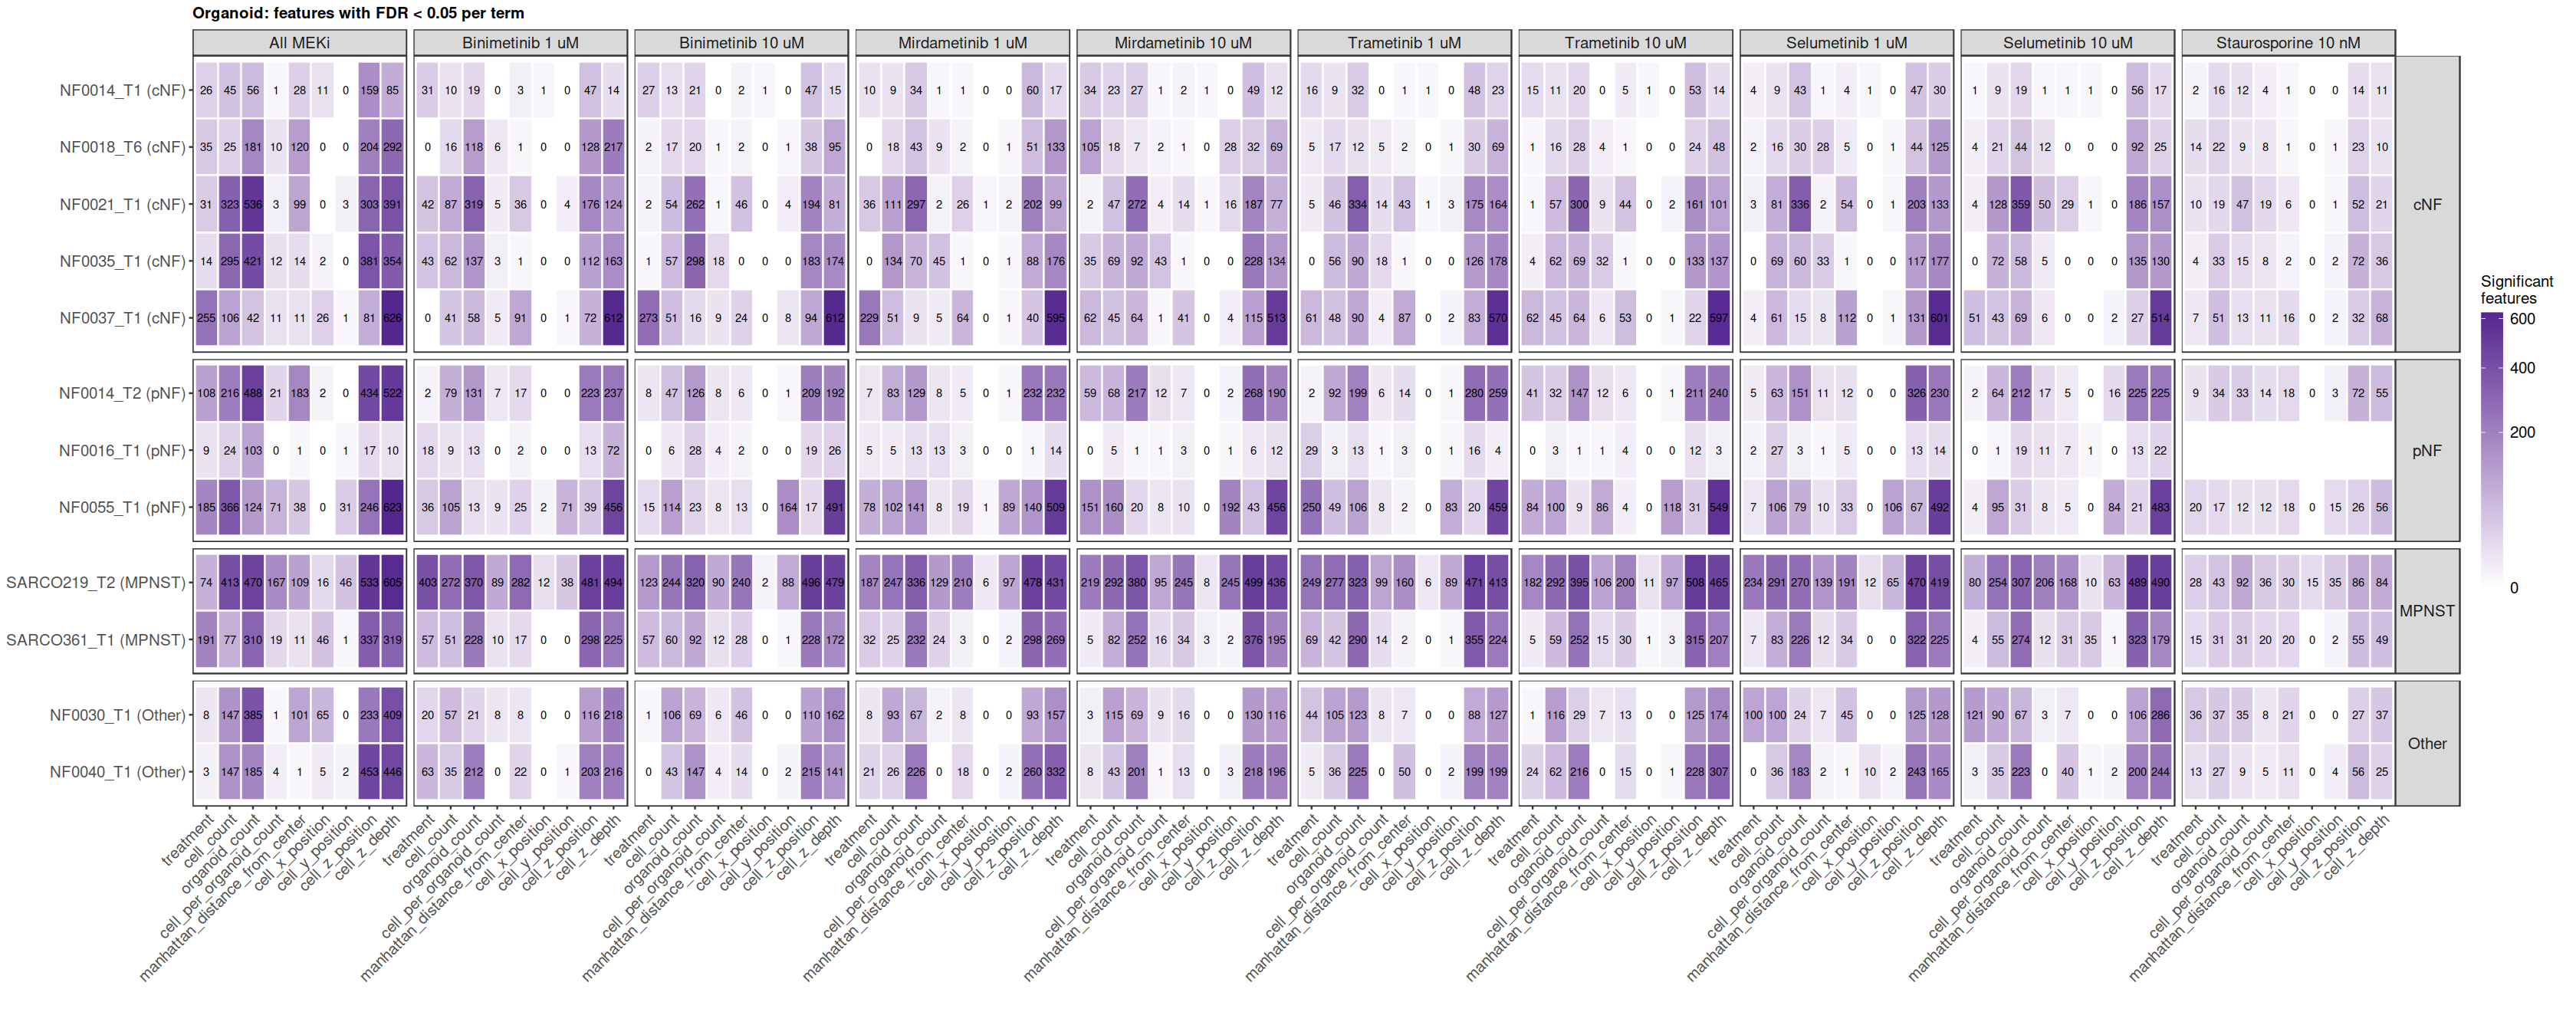

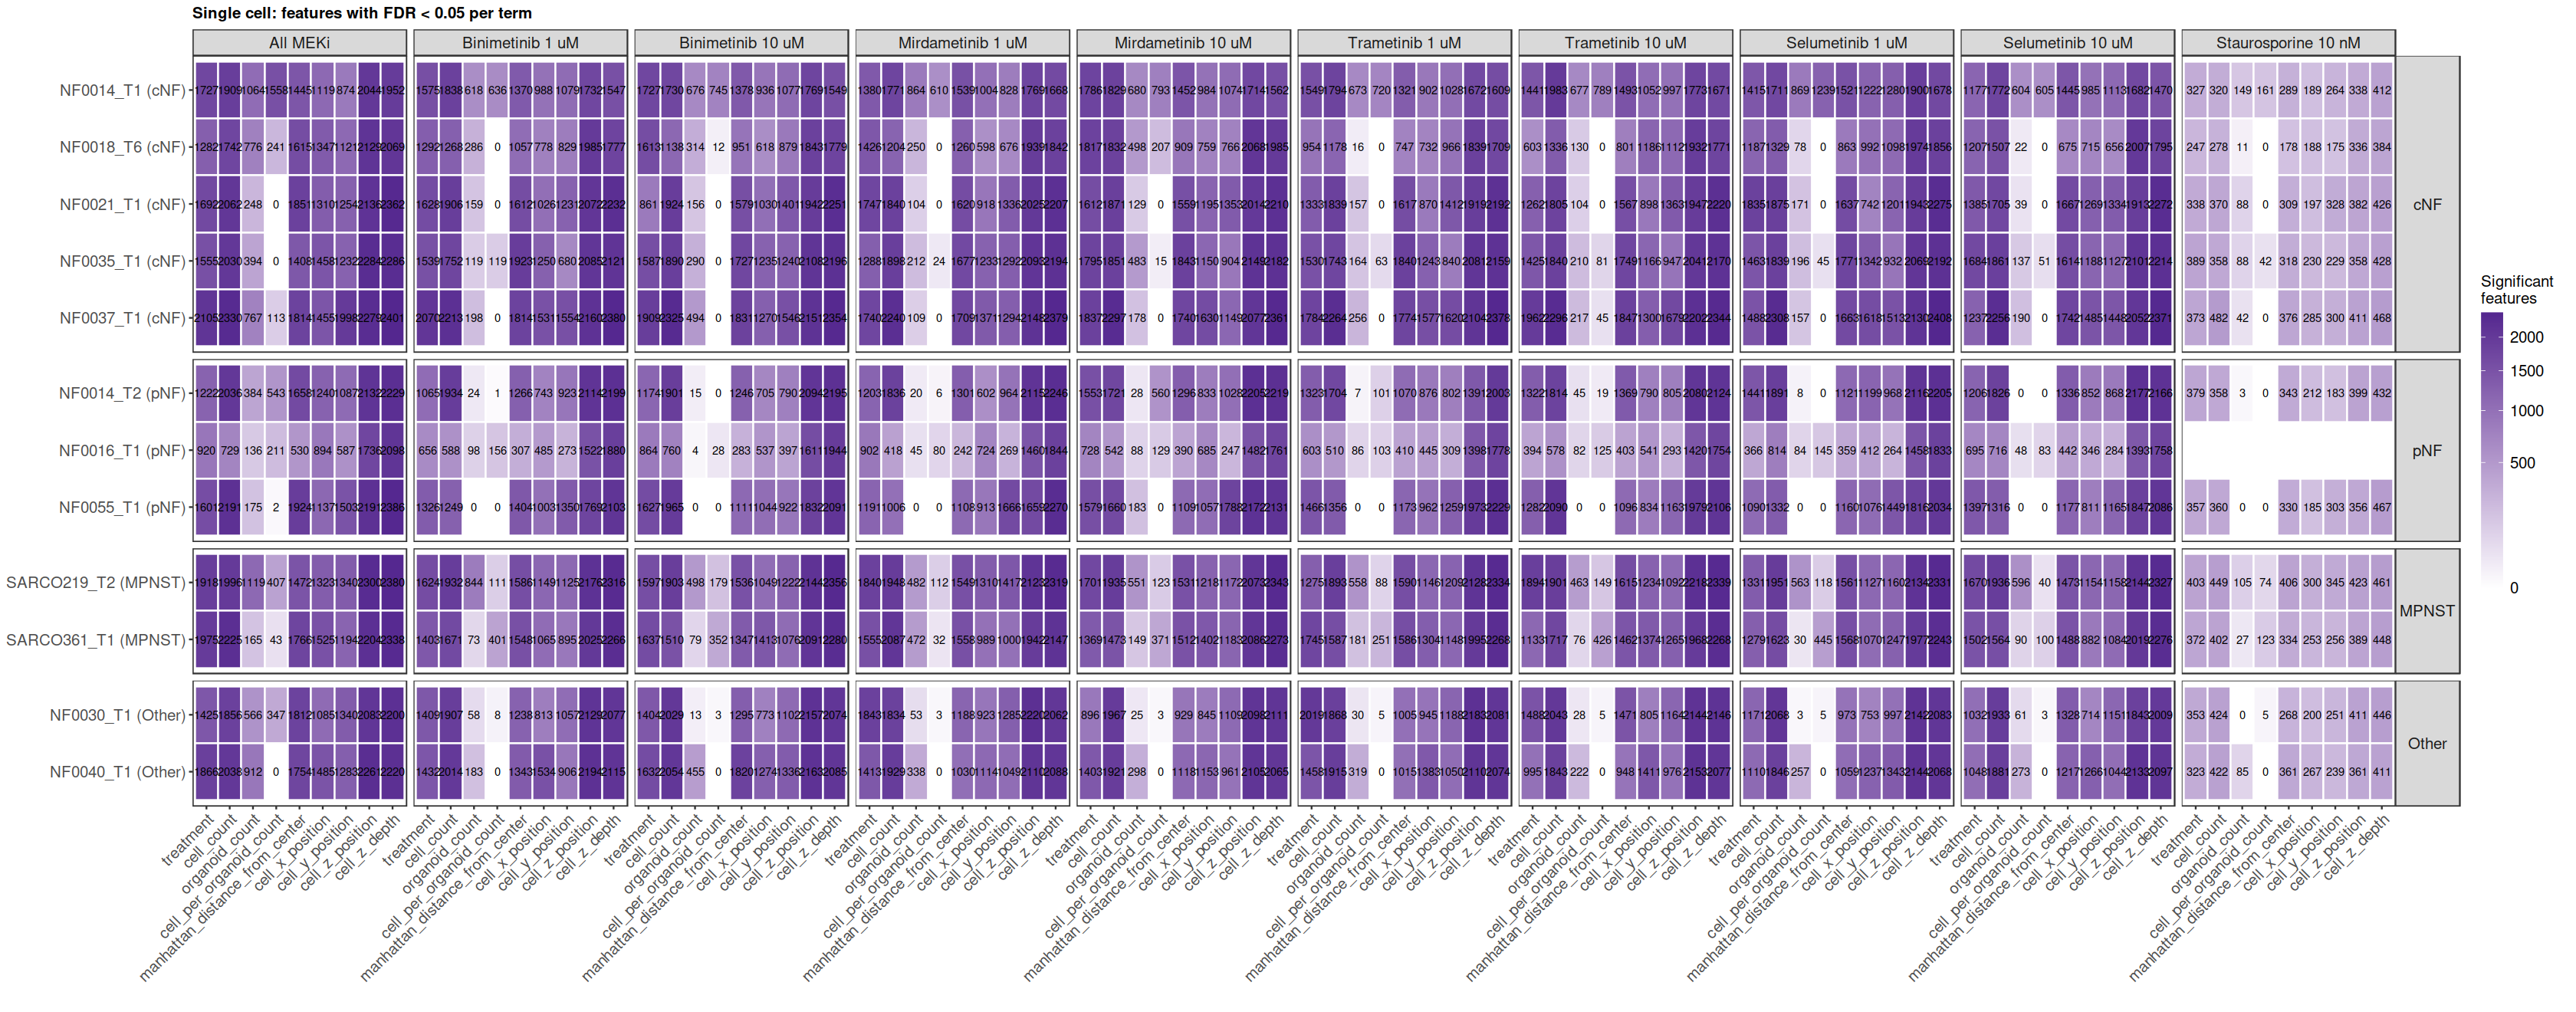

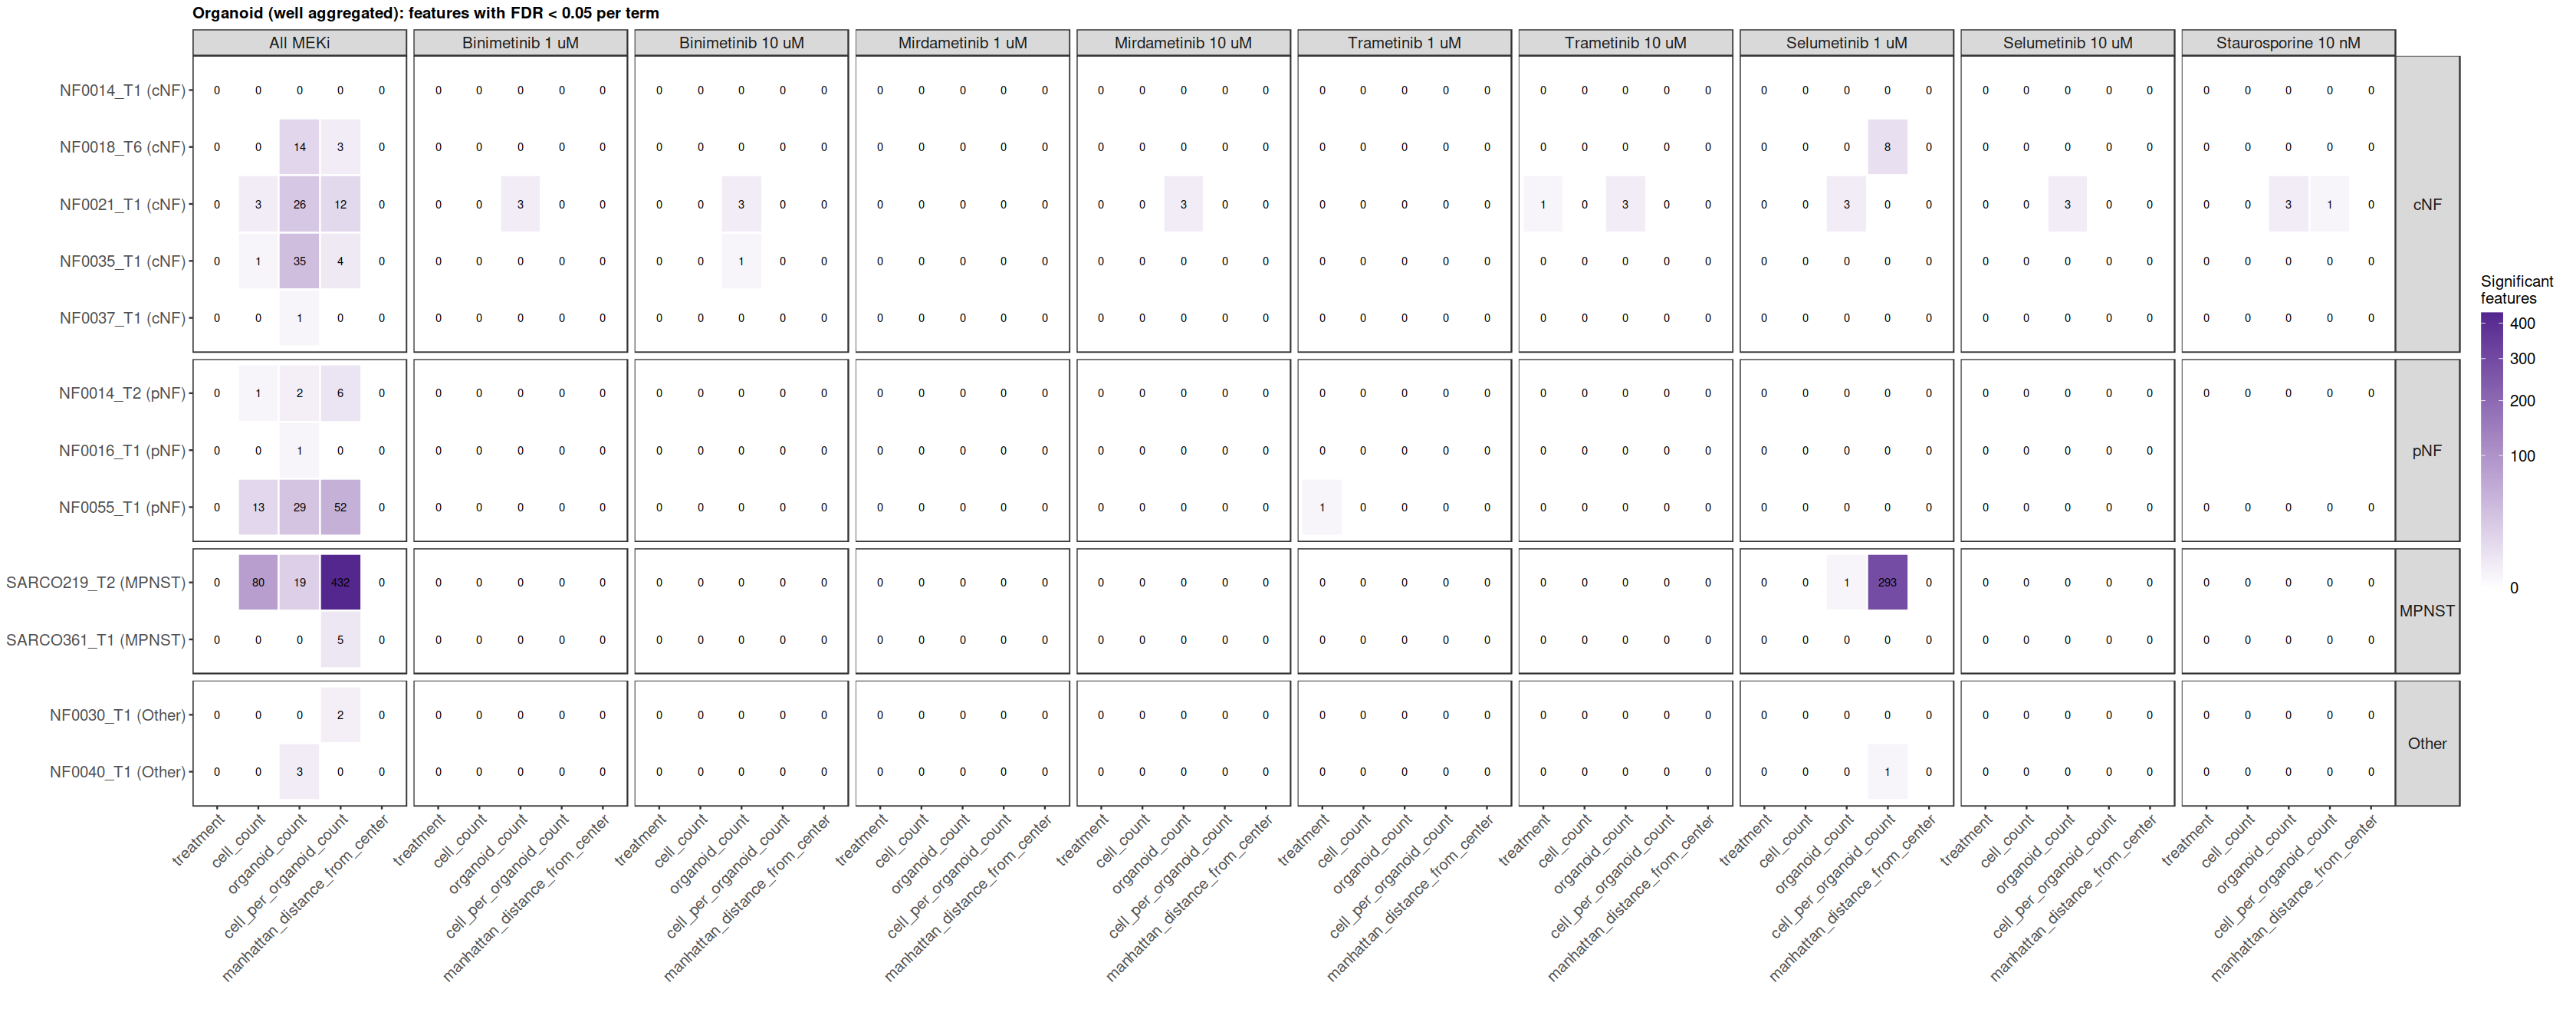

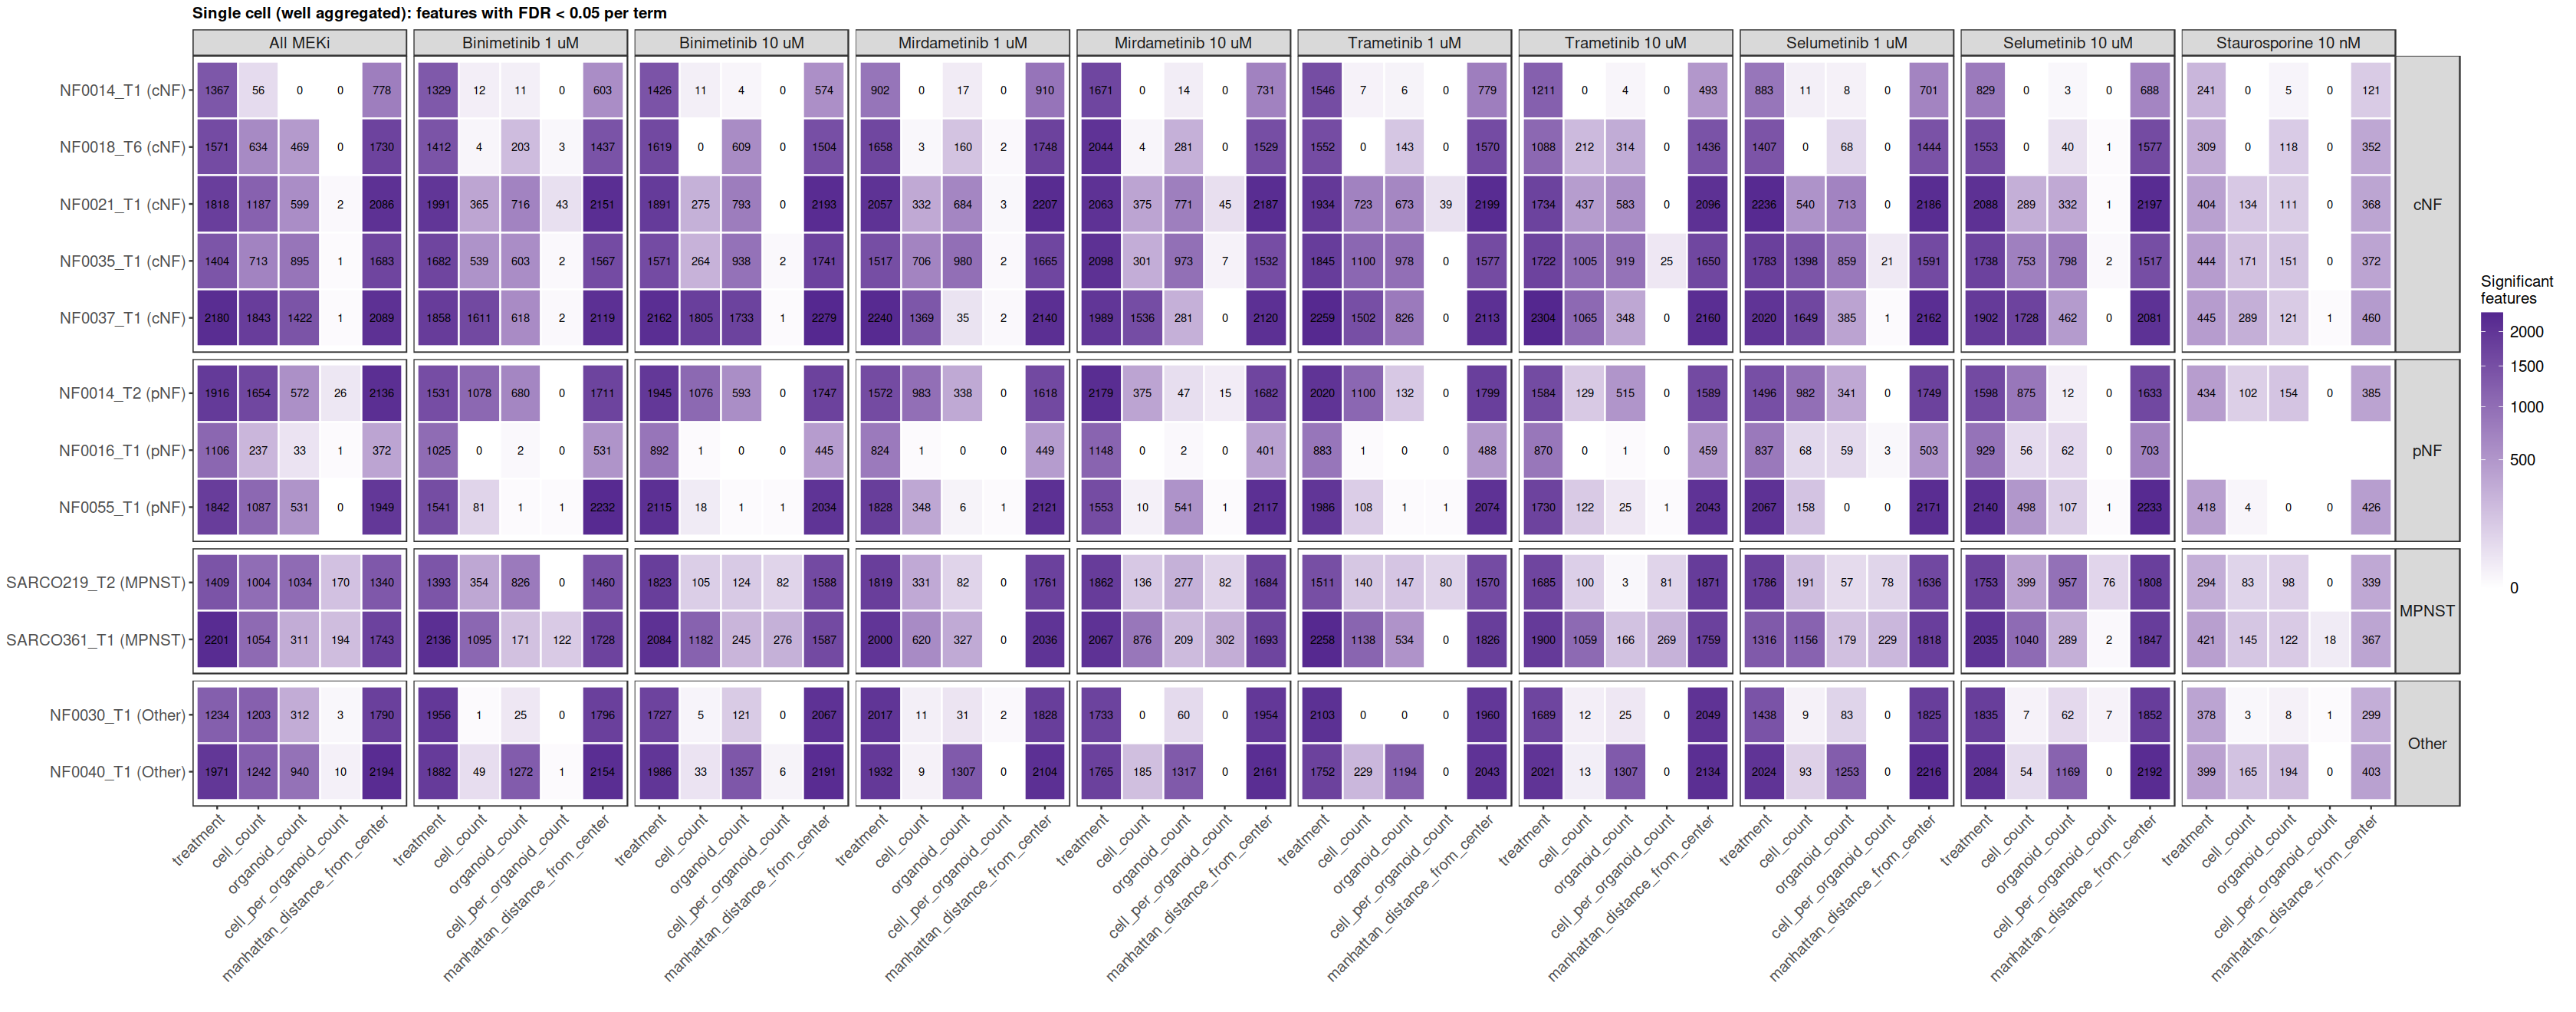

In [4]:
count_df <- lm_df %>%
    group_by(profile, mek_group, tumor_type, patient_label, term) %>%
    summarise(n_significant = sum(significant), .groups = "drop")

options(repr.plot.width = 28, repr.plot.height = 11)
count_plots <- lapply(levels(count_df$profile), function(profile_name) {
    (
        ggplot(
            count_df %>% filter(profile == profile_name),
            aes(x = term, y = patient_label, fill = n_significant)
        )
        + geom_tile(color = "white", linewidth = 0.5)
        + geom_text(aes(label = n_significant), size = 3)
        + scale_fill_gradient(
            low = "white",
            high = "#54278f",
            trans = "sqrt",
            guide = guide_colourbar(barheight = unit(3, "in"))
        )
        + scale_y_discrete(limits = rev)
        + facet_grid(tumor_type ~ mek_group, scales = "free_y", space = "free_y")
        + labs(
            title = paste0(profile_name, ": features with FDR < ", FDR_MAX, " per term"),
            x = NULL,
            y = NULL,
            fill = "Significant\nfeatures"
        )
        + theme_manuscript(base_size = 12, x_text = "angled")
        + theme(panel.grid = element_blank(), strip.text.y = element_text(angle = 0))
    )
})
save_plots_pdf(count_plots, significant_count_path, width = 28, height = 11)
for (count_plot in count_plots) print(count_plot)

## Features significant only for treatment
A feature is treatment-unique for a patient and MEKi group when its treatment term has FDR < 0.05 and no other term in the same model does.
This removes features whose treatment effect may be confounded with the technical covariates.
The first page per profile counts these features per patient and MEKi group.
The next pages, one per patient, show which features they are, grouped by feature category.
The full list is saved as a parquet file.

In [5]:
# a feature is treatment-unique when treatment is the only significant term in its model
treatment_unique_df <- lm_df %>%
    filter(significant) %>%
    group_by(profile, mek_group, patient_label, feature) %>%
    filter(all(term == "treatment")) %>%
    ungroup() %>%
    select(
        profile, mek_group, tumor_type, patient_label, Metadata_Biology_PatientTumor,
        feature, feature_category, coefficient, pvalue_fdr, direction
    )
write_parquet(
    treatment_unique_df %>% mutate(across(where(is.factor), as.character)),
    treatment_unique_results_path
)
treatment_unique_df %>% count(profile, mek_group, name = "n_treatment_unique")

profile,mek_group,n_treatment_unique
<fct>,<fct>,<int>
Organoid,All MEKi,109
Organoid,Binimetinib 1 uM,110
Organoid,Binimetinib 10 uM,107
Organoid,Mirdametinib 1 uM,77
Organoid,Mirdametinib 10 uM,131
Organoid,Trametinib 1 uM,186
Organoid,Trametinib 10 uM,79
Organoid,Selumetinib 1 uM,73
Organoid,Selumetinib 10 uM,112


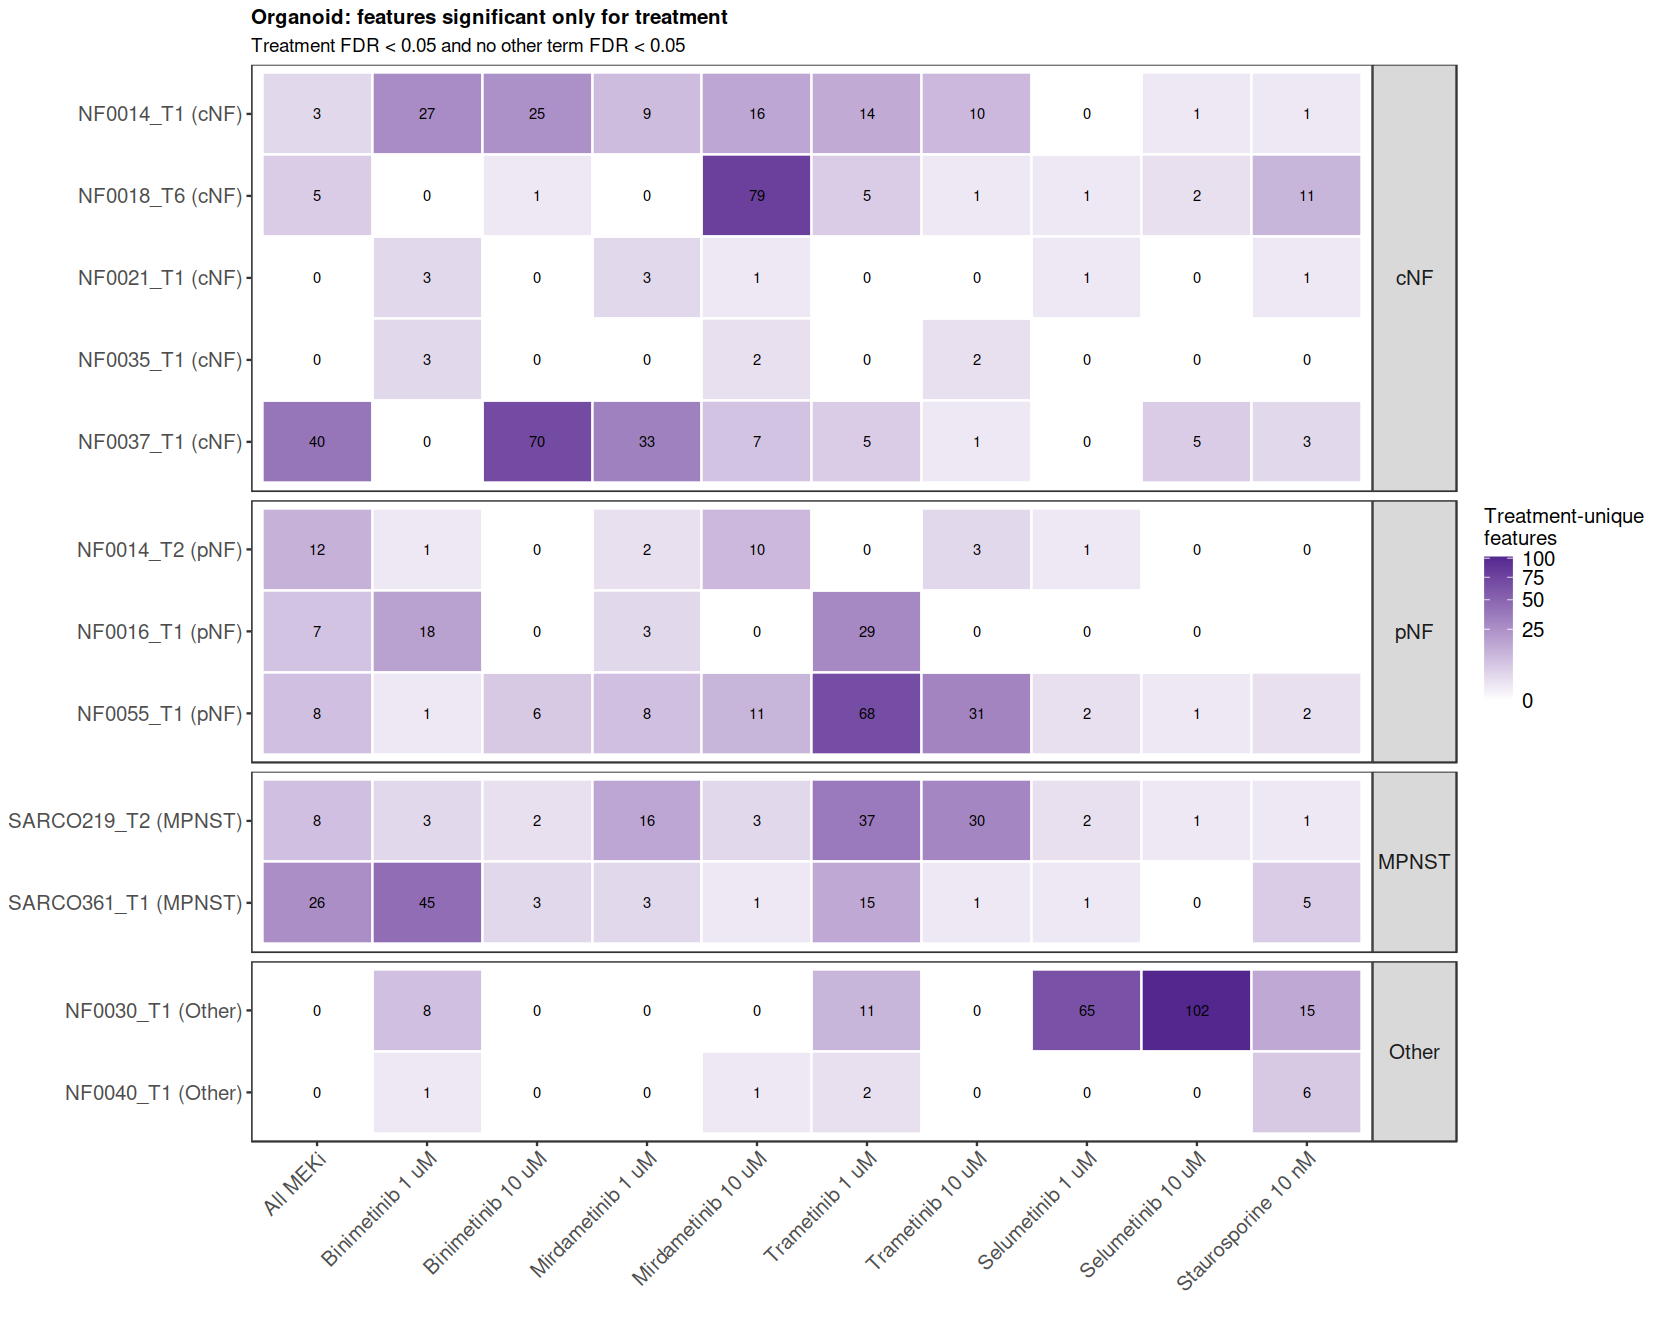

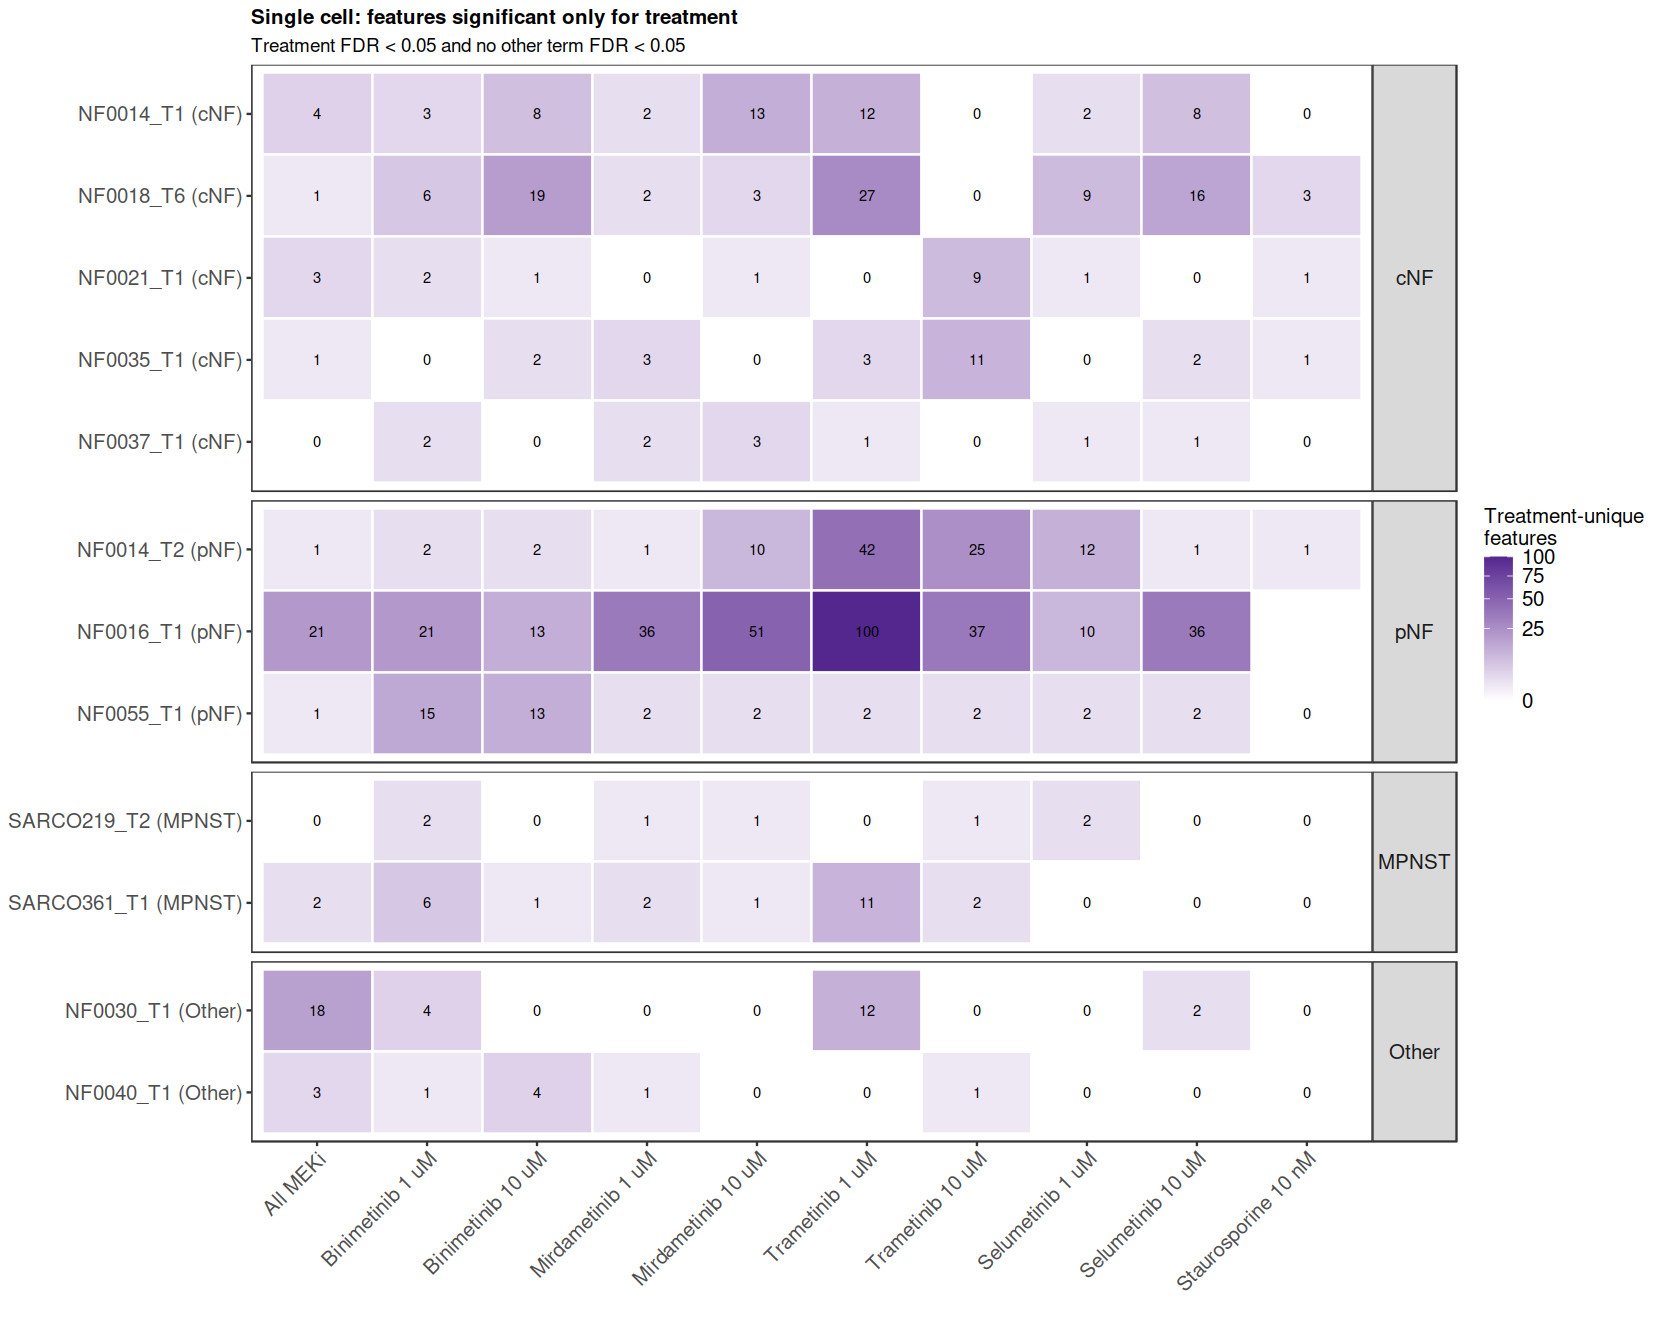

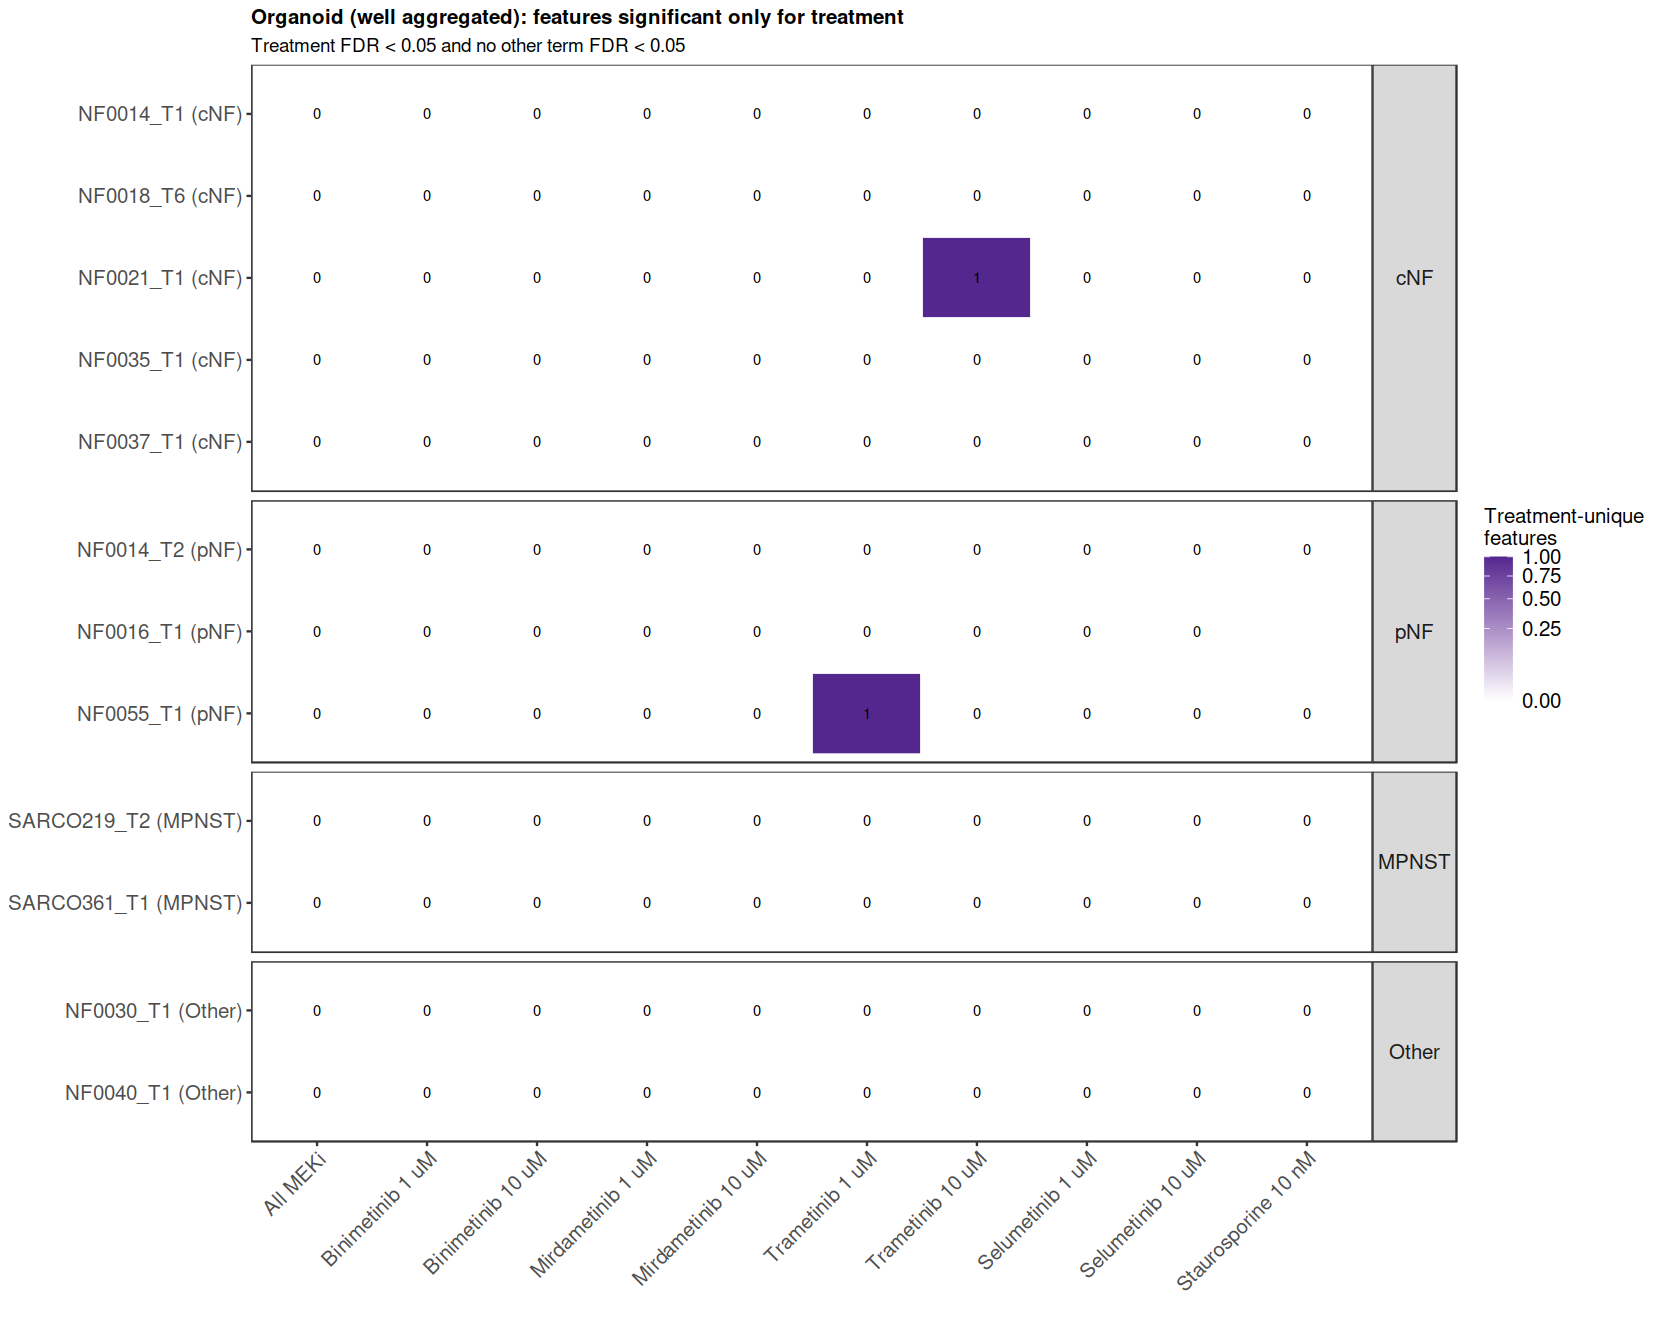

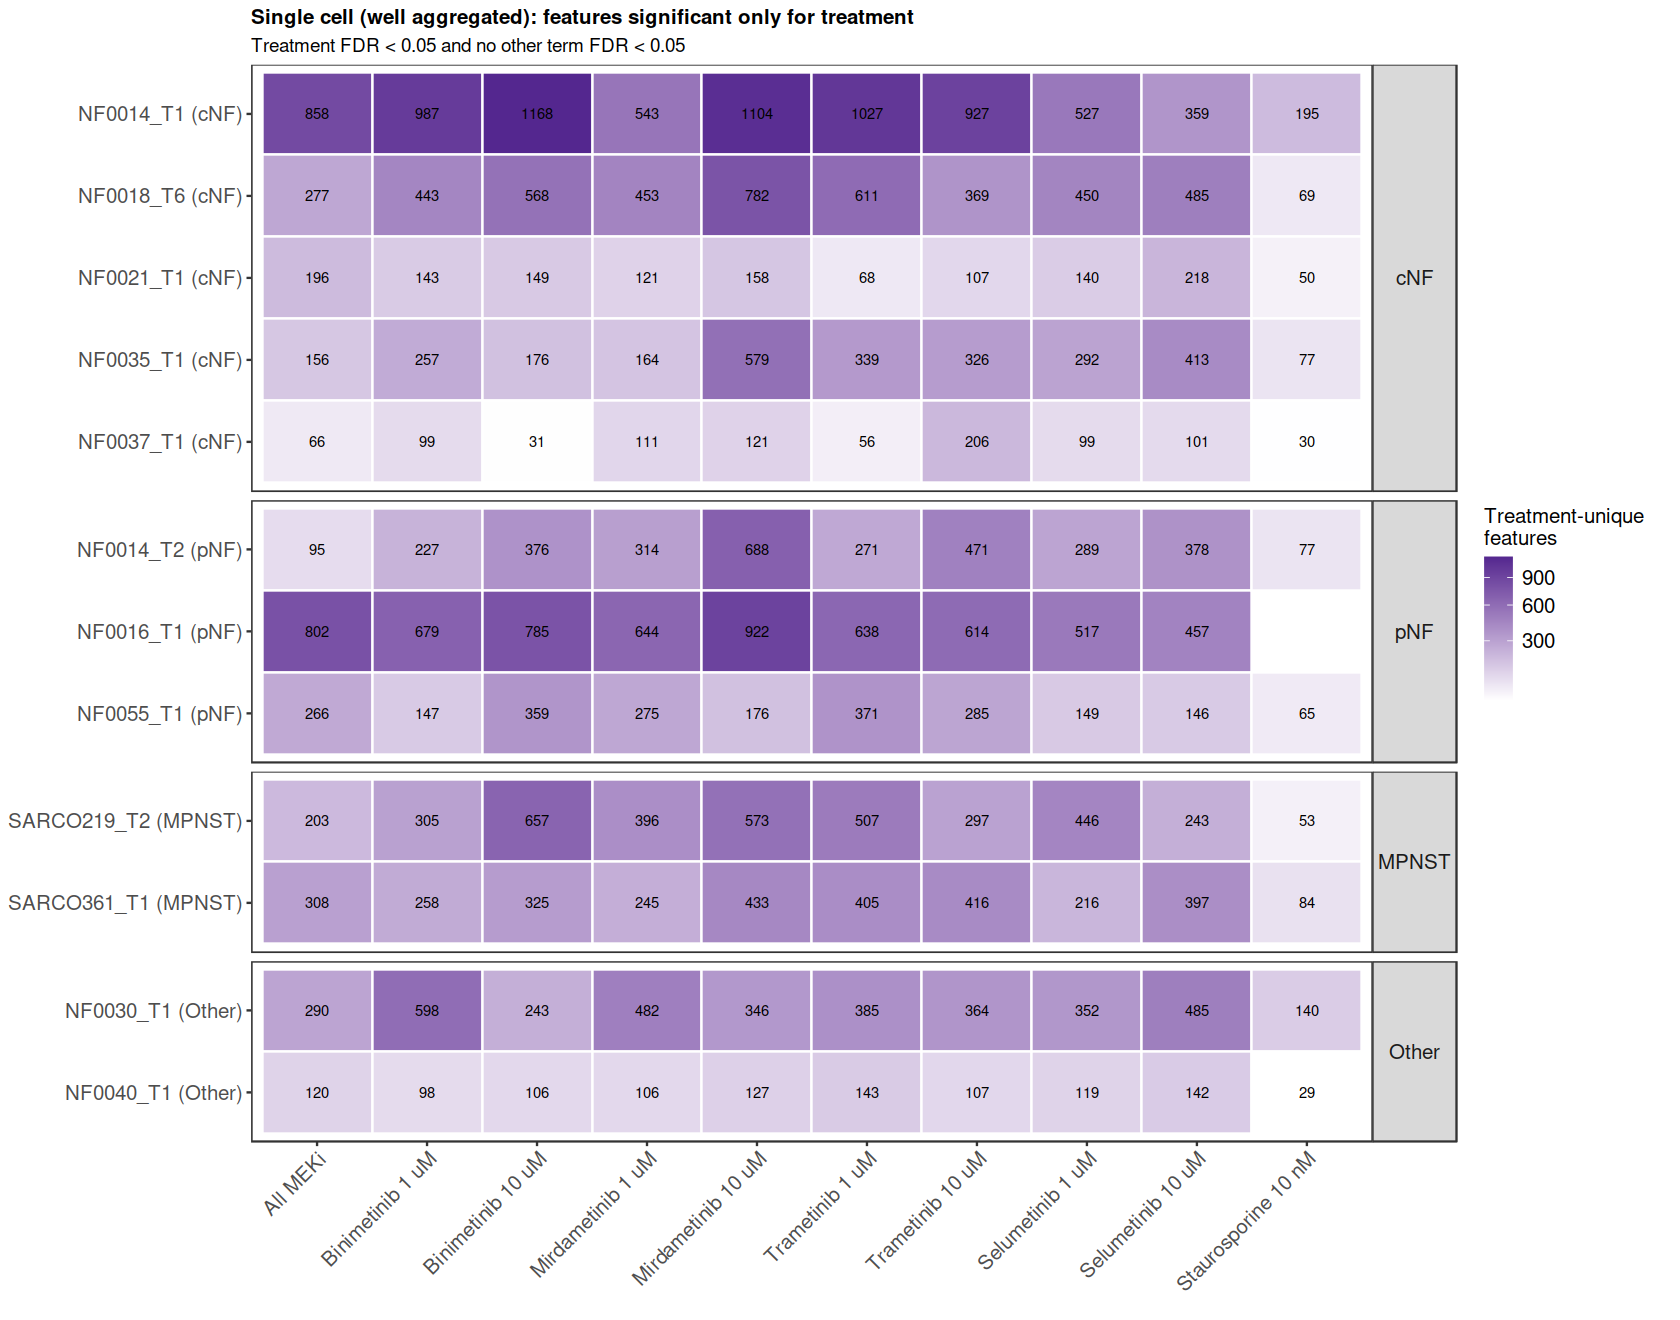

In [6]:
direction_palette <- c("Higher than DMSO" = "#d73027", "Lower than DMSO" = "#4575b4")
# feature names become unreadable past this many rows, so they are hidden
MAX_LABELED_FEATURES <- 200
# smallest height (inches) a feature category row gets, so that the strip label
# of a category with only a few features (e.g. VolumeSizeShape) is not cut off
MIN_FACET_HEIGHT_IN <- 0.3

thicken_small_facets <- function(plot, min_height_in = MIN_FACET_HEIGHT_IN) {
    # Return a page-drawing function (for save_plots_pdf) that draws `plot`
    # with each facet row at least `min_height_in` inches tall.
    # facet_grid(space = "free_y") stores each row height as a relative
    # "null" unit sharing whatever height the fixed rows leave free, so the
    # floor is converted to that relative scale before raising small rows.
    function() {
        # ggplotGrob() opens the page itself, so no grid.newpage() is needed
        plot_gtable <- ggplotGrob(plot)
        panel_rows <- unique(plot_gtable$layout$t[grepl("^panel", plot_gtable$layout$name)])
        panel_heights <- as.numeric(plot_gtable$heights[panel_rows])
        page_height_in <- grid::convertHeight(unit(1, "npc"), "in", valueOnly = TRUE)
        fixed_height_in <- sum(
            grid::convertHeight(plot_gtable$heights[-panel_rows], "in", valueOnly = TRUE)
        )
        min_height_null <- min_height_in / (page_height_in - fixed_height_in) * sum(panel_heights)
        plot_gtable$heights[panel_rows] <- unit(pmax(panel_heights, min_height_null), "null")
        grid::grid.draw(plot_gtable)
    }
}

unique_count_plot <- function(profile_name) {
    plot_df <- treatment_unique_df %>%
        filter(profile == profile_name) %>%
        count(mek_group, tumor_type, patient_label, name = "n_unique") %>%
        # keep every patient x MEKi group cell, including the ones with zero features
        right_join(
            lm_df %>%
                filter(profile == profile_name) %>%
                distinct(mek_group, tumor_type, patient_label),
            by = c("mek_group", "tumor_type", "patient_label")
        ) %>%
        mutate(n_unique = coalesce(n_unique, 0L))
    (
        ggplot(plot_df, aes(x = mek_group, y = patient_label, fill = n_unique))
        + geom_tile(color = "white", linewidth = 0.5)
        + geom_text(aes(label = n_unique), size = 3)
        + scale_fill_gradient(low = "white", high = "#54278f", trans = "sqrt")
        + scale_y_discrete(limits = rev)
        + facet_grid(tumor_type ~ ., scales = "free_y", space = "free_y")
        + labs(
            title = paste0(profile_name, ": features significant only for treatment"),
            subtitle = paste0("Treatment FDR < ", FDR_MAX, " and no other term FDR < ", FDR_MAX),
            x = NULL,
            y = NULL,
            fill = "Treatment-unique\nfeatures"
        )
        + theme_manuscript(base_size = 12, x_text = "angled")
        + theme(panel.grid = element_blank(), strip.text.y = element_text(angle = 0))
    )
}

unique_feature_plot <- function(profile_name, patient_name) {
    plot_df <- treatment_unique_df %>%
        filter(profile == profile_name, patient_label == patient_name) %>%
        # features found in the most MEKi groups at the top of each category
        add_count(feature, name = "n_mek_groups") %>%
        arrange(desc(n_mek_groups), feature) %>%
        mutate(feature = factor(feature, levels = rev(unique(feature))))
    n_features <- n_distinct(plot_df$feature)
    show_labels <- n_features <= MAX_LABELED_FEATURES
    subtitle <- paste0(n_features, " features")
    if (!show_labels) {
        subtitle <- paste0(subtitle, " (names hidden; see the treatment-unique parquet file)")
    }
    (
        ggplot(plot_df, aes(x = mek_group, y = feature, fill = direction))
        # tile borders would cover the sub-pixel tiles of the unlabeled pages
        + geom_tile(color = if (show_labels) "white" else NA, linewidth = 0.3)
        + scale_x_discrete(limits = mek_group_levels, drop = FALSE)
        + scale_fill_manual(values = direction_palette)
        + facet_grid(feature_category ~ ., scales = "free_y", space = "free_y")
        + labs(
            title = paste0(profile_name, " | ", patient_name, " | features significant only for treatment"),
            subtitle = subtitle,
            x = NULL,
            y = NULL,
            fill = NULL
        )
        + theme_manuscript(base_size = 12, x_text = "angled")
        + theme(
            panel.grid = element_blank(),
            strip.text.y = element_text(angle = 0),
            axis.text.y = if (show_labels) element_text(size = 6) else element_blank(),
            axis.ticks.y = if (show_labels) element_line() else element_blank(),
            legend.position = "top"
        )
    )
}

# one summary page per profile, followed by one page per patient that has any
# treatment-unique features
unique_pages <- list()
unique_heights <- c()
for (profile_name in levels(lm_df$profile)) {
    unique_pages[[length(unique_pages) + 1]] <- unique_count_plot(profile_name)
    unique_heights <- c(unique_heights, 11)
    profile_patients <- treatment_unique_df %>%
        filter(profile == profile_name) %>%
        distinct(patient_label) %>%
        arrange(patient_label) %>%
        pull(patient_label) %>%
        as.character()
    for (patient_name in profile_patients) {
        n_features <- treatment_unique_df %>%
            filter(profile == profile_name, patient_label == patient_name) %>%
            pull(feature) %>%
            n_distinct()
        unique_pages[[length(unique_pages) + 1]] <- thicken_small_facets(
            unique_feature_plot(profile_name, patient_name)
        )
        # labeled pages get a row per feature; unlabeled ones stay at a fixed size
        unique_heights <- c(
            unique_heights,
            if (n_features <= MAX_LABELED_FEATURES) max(6, 3 + 0.11 * n_features) else 14
        )
    }
}
save_plots_pdf(unique_pages, treatment_unique_path, width = 14, height = unique_heights)
options(repr.plot.width = 14, repr.plot.height = 11)
for (profile_name in levels(lm_df$profile)) print(unique_count_plot(profile_name))

### Treatment-unique features by tumor type
The same feature maps as above, with one page per profile and tumor type instead of per patient.
Each tile is the signed fraction of patients in the tumor type for which the feature is treatment-unique in that MEKi group.
A patient adds +1 when the feature is higher in MEKi and -1 when it is lower; the sum is divided by the number of patients of that tumor type in the MEKi group.
So +1 or -1 means every patient agrees, and values near 0 mean few patients or opposing directions.

In [7]:
# patients of each tumor type modeled in each MEKi group: the denominator of the fraction
tumor_type_patients_df <- lm_df %>%
    distinct(profile, tumor_type, mek_group, patient_label) %>%
    count(profile, tumor_type, mek_group, name = "n_patients")

treatment_unique_tumor_type_df <- treatment_unique_df %>%
    group_by(profile, tumor_type, mek_group, feature, feature_category) %>%
    summarise(
        n_higher = sum(direction == "Higher than DMSO"),
        n_lower = sum(direction == "Lower than DMSO"),
        .groups = "drop"
    ) %>%
    left_join(tumor_type_patients_df, by = c("profile", "tumor_type", "mek_group")) %>%
    mutate(signed_fraction = (n_higher - n_lower) / n_patients)

unique_tumor_type_plot <- function(profile_name, tumor_type_name) {
    plot_df <- treatment_unique_tumor_type_df %>%
        filter(profile == profile_name, tumor_type == tumor_type_name) %>%
        # features shared by the most patients across MEKi groups at the top of each category
        group_by(feature) %>%
        mutate(n_patient_hits = sum(n_higher + n_lower)) %>%
        ungroup() %>%
        arrange(desc(n_patient_hits), feature) %>%
        mutate(feature = factor(feature, levels = rev(unique(feature))))
    n_features <- n_distinct(plot_df$feature)
    n_patients <- lm_df %>%
        filter(profile == profile_name, tumor_type == tumor_type_name) %>%
        pull(patient_label) %>%
        n_distinct()
    show_labels <- n_features <= MAX_LABELED_FEATURES
    subtitle <- paste0(n_features, " features across ", n_patients, " patients")
    if (!show_labels) {
        subtitle <- paste0(subtitle, " (names hidden; see the treatment-unique parquet file)")
    }
    (
        ggplot(plot_df, aes(x = mek_group, y = feature, fill = signed_fraction))
        # tile borders would cover the sub-pixel tiles of the unlabeled pages
        + geom_tile(color = if (show_labels) "white" else NA, linewidth = 0.3)
        + scale_x_discrete(limits = mek_group_levels, drop = FALSE)
        + scale_fill_gradient2(
            low = direction_palette[["Lower than DMSO"]],
            mid = "grey90",
            high = direction_palette[["Higher than DMSO"]],
            midpoint = 0,
            limits = c(-1, 1),
            guide = guide_colourbar(barwidth = unit(3, "in"))
        )
        + facet_grid(feature_category ~ ., scales = "free_y", space = "free_y")
        + labs(
            title = paste0(
                profile_name, " | ", tumor_type_name, " | features significant only for treatment"
            ),
            subtitle = subtitle,
            x = NULL,
            y = NULL,
            fill = "Signed fraction of patients\n(+ higher, - lower than DMSO)"
        )
        + theme_manuscript(base_size = 12, x_text = "angled")
        + theme(
            panel.grid = element_blank(),
            strip.text.y = element_text(angle = 0),
            axis.text.y = if (show_labels) element_text(size = 6) else element_blank(),
            axis.ticks.y = if (show_labels) element_line() else element_blank(),
            legend.position = "top"
        )
    )
}

# one page per profile x tumor type that has any treatment-unique features
tumor_type_pages_df <- treatment_unique_tumor_type_df %>%
    group_by(profile, tumor_type) %>%
    summarise(n_features = n_distinct(feature), .groups = "drop") %>%
    arrange(profile, tumor_type)
tumor_type_plots <- lapply(
    mapply(
        unique_tumor_type_plot,
        as.character(tumor_type_pages_df$profile),
        as.character(tumor_type_pages_df$tumor_type),
        SIMPLIFY = FALSE
    ),
    thicken_small_facets
)
tumor_type_heights <- if_else(
    tumor_type_pages_df$n_features <= MAX_LABELED_FEATURES,
    pmax(6, 3 + 0.11 * tumor_type_pages_df$n_features),
    14
)
save_plots_pdf(
    tumor_type_plots, treatment_unique_tumor_type_path,
    width = 14, height = tumor_type_heights
)
tumor_type_pages_df

profile,tumor_type,n_features
<fct>,<fct>,<int>
Organoid,cNF,223
Organoid,pNF,166
Organoid,MPNST,175
Organoid,Other,133
Single cell,cNF,135
Single cell,pNF,323
Single cell,MPNST,30
Single cell,Other,35
Organoid (well aggregated),cNF,1


### VolumeSizeShape feature distributions
One page per well-aggregated profile (organoid and single cell), one panel per VolumeSizeShape feature: the distribution of the treatment coefficient (difference from DMSO) across patients in each MEKi group and the staurosporine control.
Each point is one patient, colored by tumor type; filled points have treatment FDR < 0.05.
Box plots show the median and interquartile range across patients; the dashed line marks no difference from DMSO.

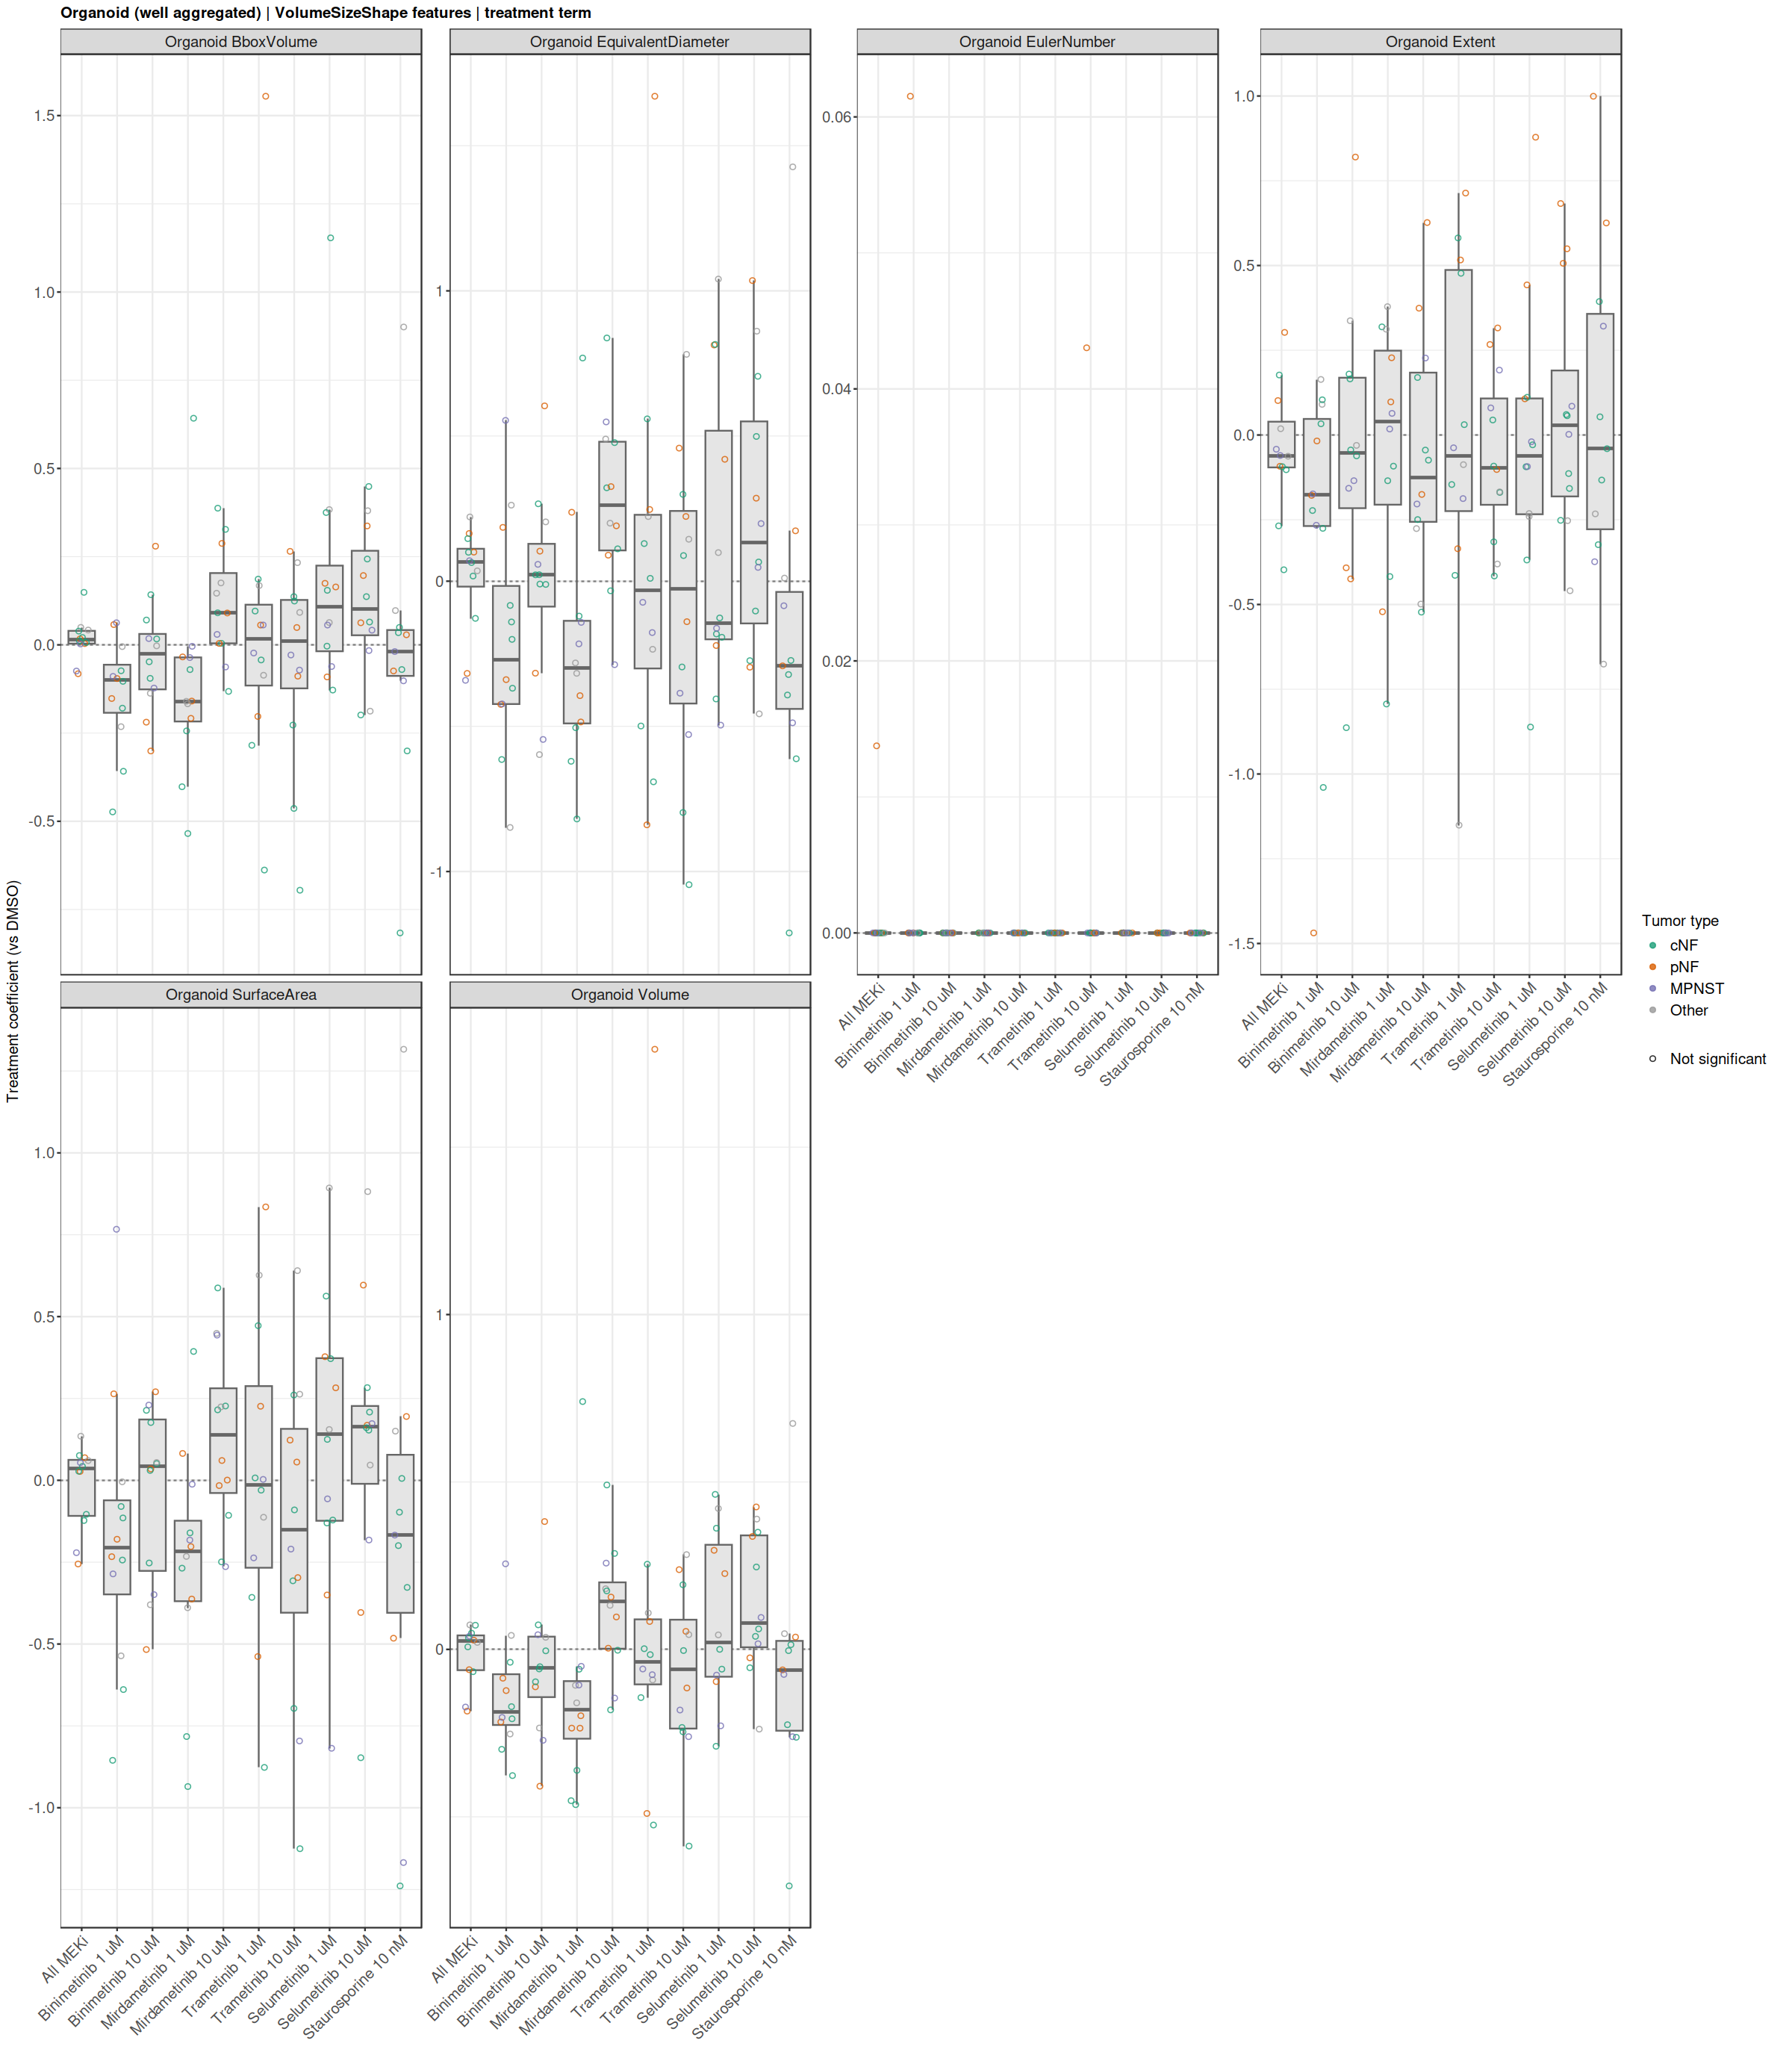

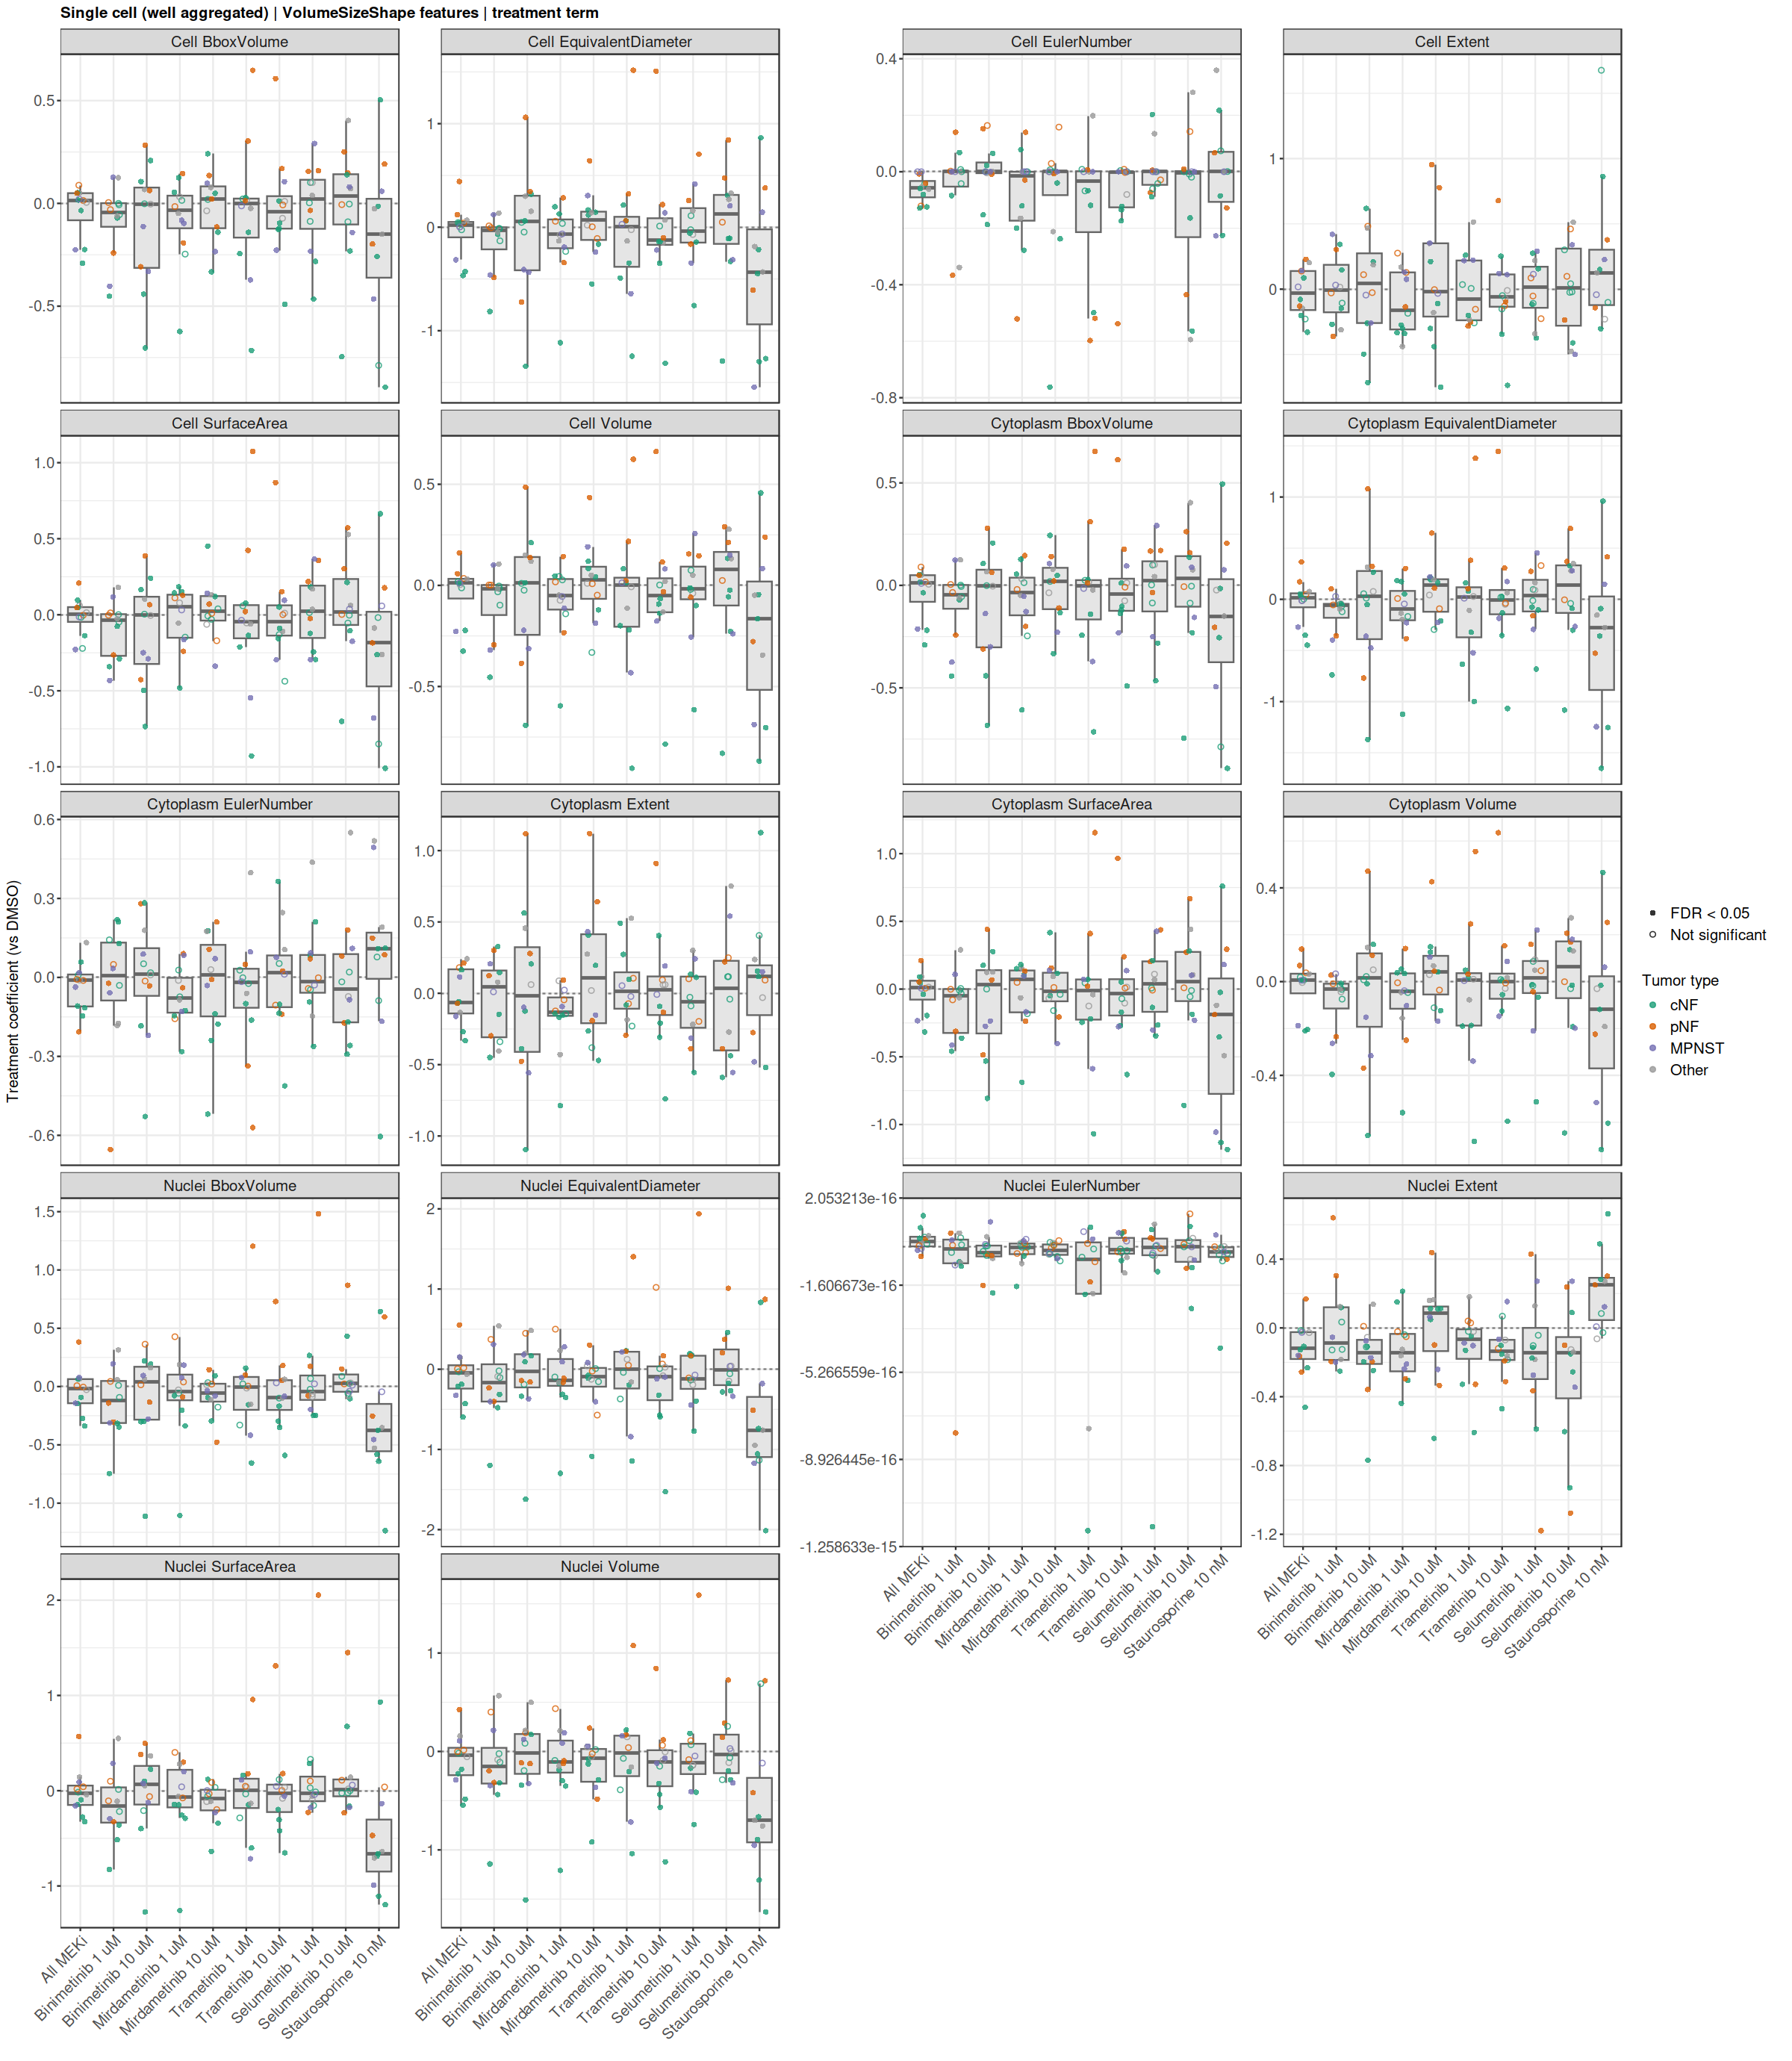

In [8]:
VOLUME_SIZE_SHAPE_NCOL <- 4
# only the well-aggregated models: one profile per well rather than per object
VOLUME_SIZE_SHAPE_PROFILES <- c("Organoid (well aggregated)", "Single cell (well aggregated)")
volume_size_shape_df <- treatment_df %>%
    filter(
        feature_category == "VolumeSizeShape",
        profile %in% VOLUME_SIZE_SHAPE_PROFILES,
        !is.na(coefficient)
    ) %>%
    mutate(
        # e.g. Cell_NoChannel_VolumeSizeShape_Volume -> Cell Volume
        feature_label = sub("_NoChannel_VolumeSizeShape_", " ", feature),
        significance = if_else(significant, paste0("FDR < ", FDR_MAX), "Not significant")
    )

volume_size_shape_plot <- function(profile_name) {
    plot_df <- volume_size_shape_df %>% filter(profile == profile_name)
    title <- paste0(profile_name, " | VolumeSizeShape features | treatment term")
    if (nrow(plot_df) == 0) {
        return(
            ggplot()
            + annotate("text", x = 0, y = 0, label = "No VolumeSizeShape features modeled", size = 6)
            + labs(title = title)
            + theme_manuscript_void(base_size = 12)
        )
    }
    (
        ggplot(plot_df, aes(x = mek_group, y = coefficient))
        + geom_hline(yintercept = 0, linetype = "dashed", color = "grey50")
        + geom_boxplot(outlier.shape = NA, fill = "grey90", color = "grey40")
        + geom_point(
            aes(color = tumor_type, shape = significance),
            position = position_jitter(width = 0.2, height = 0, seed = 0),
            size = 1.5,
            alpha = 0.8
        )
        + scale_x_discrete(limits = mek_group_levels, drop = FALSE)
        + scale_color_manual(values = tumor_type_palette)
        + scale_shape_manual(
            values = setNames(c(16, 1), c(paste0("FDR < ", FDR_MAX), "Not significant"))
        )
        + facet_wrap(~feature_label, scales = "free_y", ncol = VOLUME_SIZE_SHAPE_NCOL)
        + labs(
            title = title,
            x = NULL,
            y = "Treatment coefficient (vs DMSO)",
            color = "Tumor type",
            shape = NULL
        )
        + theme_manuscript(base_size = 12, x_text = "angled")
    )
}

volume_size_shape_plots <- lapply(VOLUME_SIZE_SHAPE_PROFILES, volume_size_shape_plot)
# one row of panels per VOLUME_SIZE_SHAPE_NCOL features
volume_size_shape_heights <- sapply(VOLUME_SIZE_SHAPE_PROFILES, function(profile_name) {
    n_features <- n_distinct(volume_size_shape_df$feature[volume_size_shape_df$profile == profile_name])
    3 + 4 * max(1, ceiling(n_features / VOLUME_SIZE_SHAPE_NCOL))
})
save_plots_pdf(volume_size_shape_plots, volume_size_shape_path, width = 20, height = volume_size_shape_heights)
options(repr.plot.width = 20, repr.plot.height = max(volume_size_shape_heights))
for (volume_size_shape_page in volume_size_shape_plots) print(volume_size_shape_page)

#### Selected VolumeSizeShape features
Two pages each for nuclei extent, nuclei volume, and cell volume, split by tumor type:
1. the same treatment coefficients as above;
2. the feature values the model was fit on: one point per well, colored by patient, with a violin per treatment group across the patients of that tumor type. DMSO is included as the reference; "All MEKi" is left out because it pools the same wells as the individual MEKi groups.
Only the single-cell profile measures nuclei and cell compartments, so these pages show the single cell (well aggregated) model.

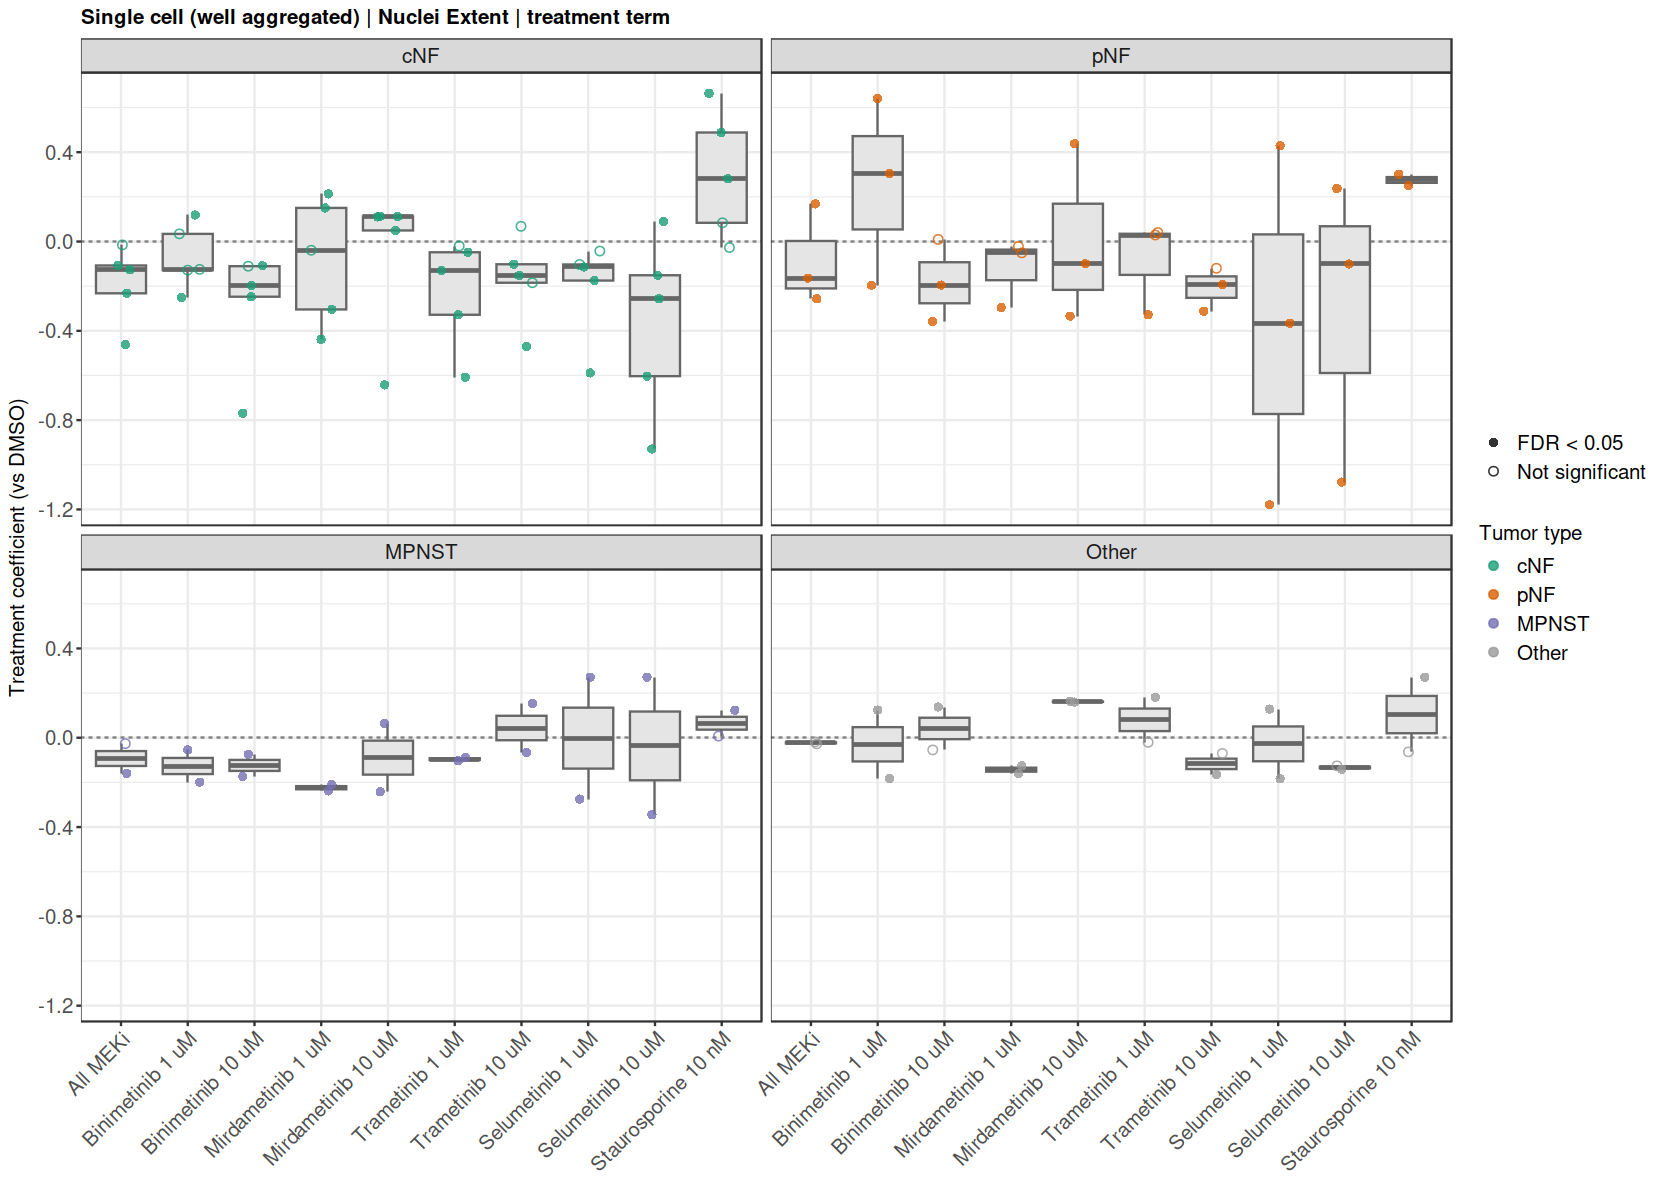

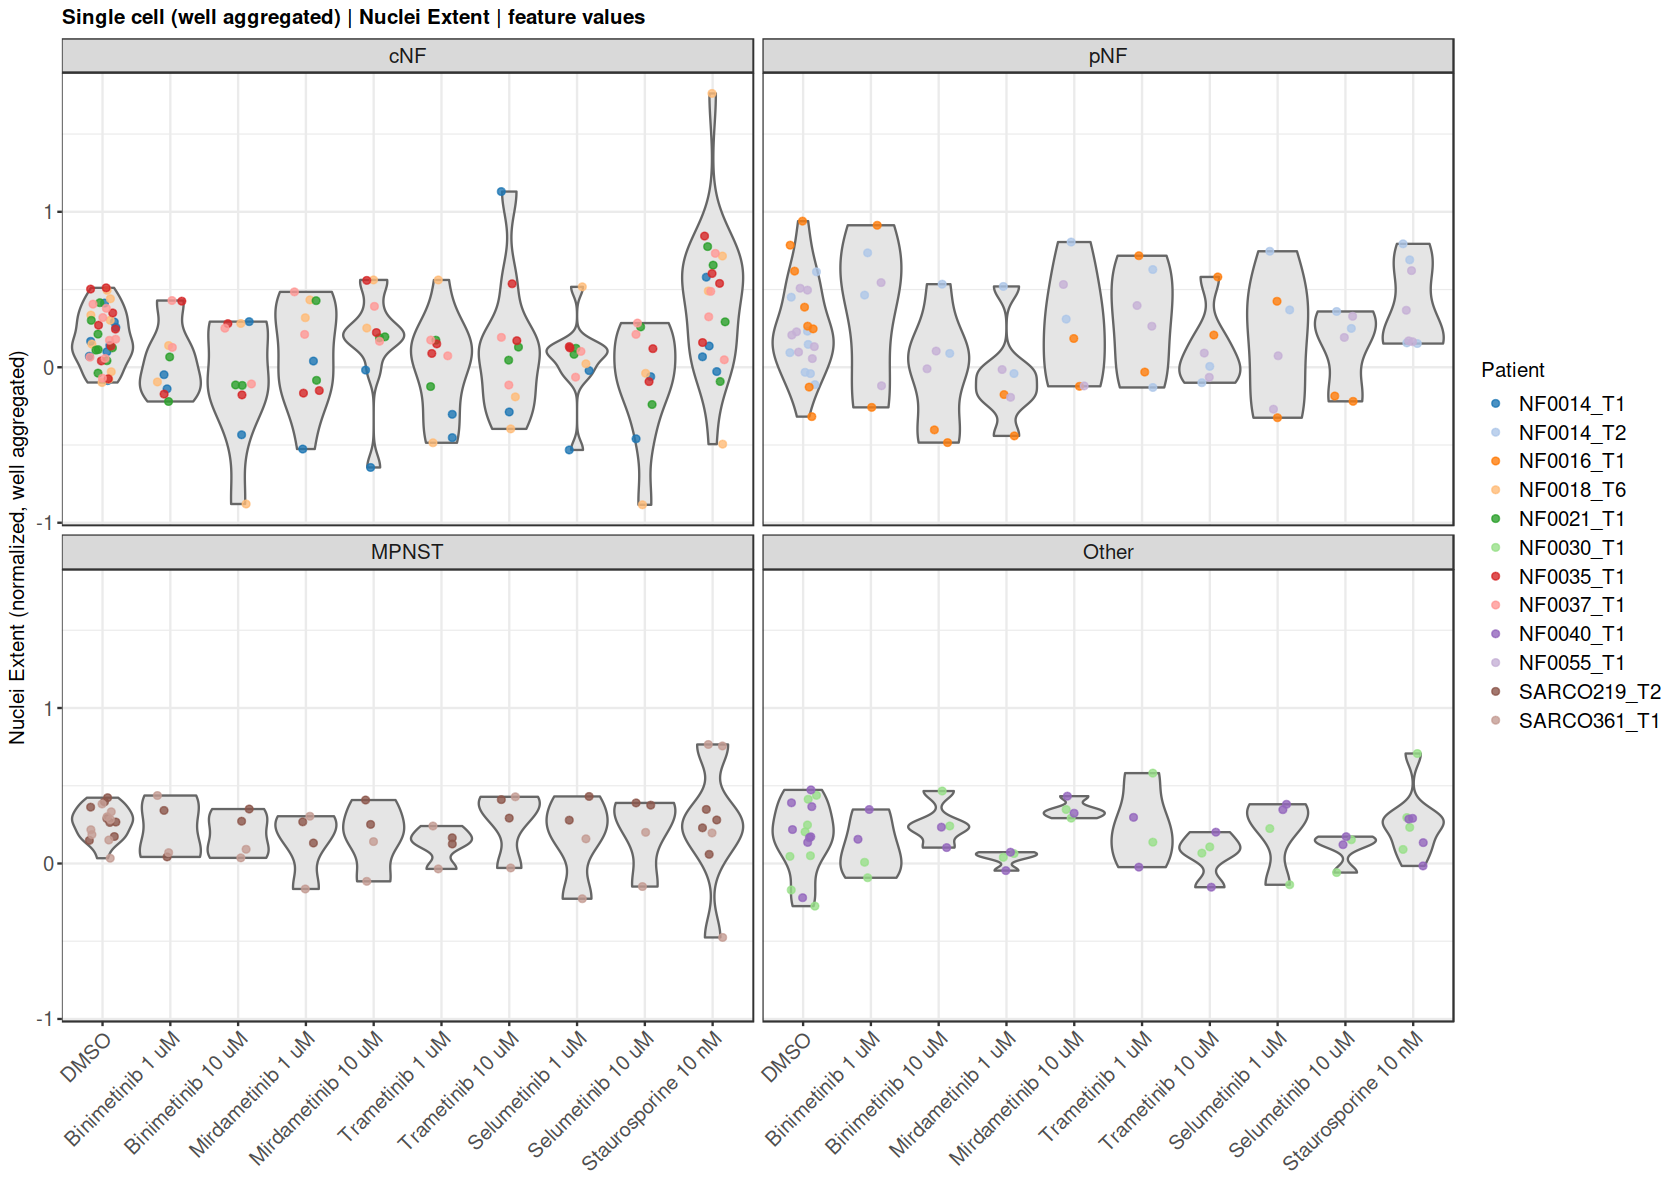

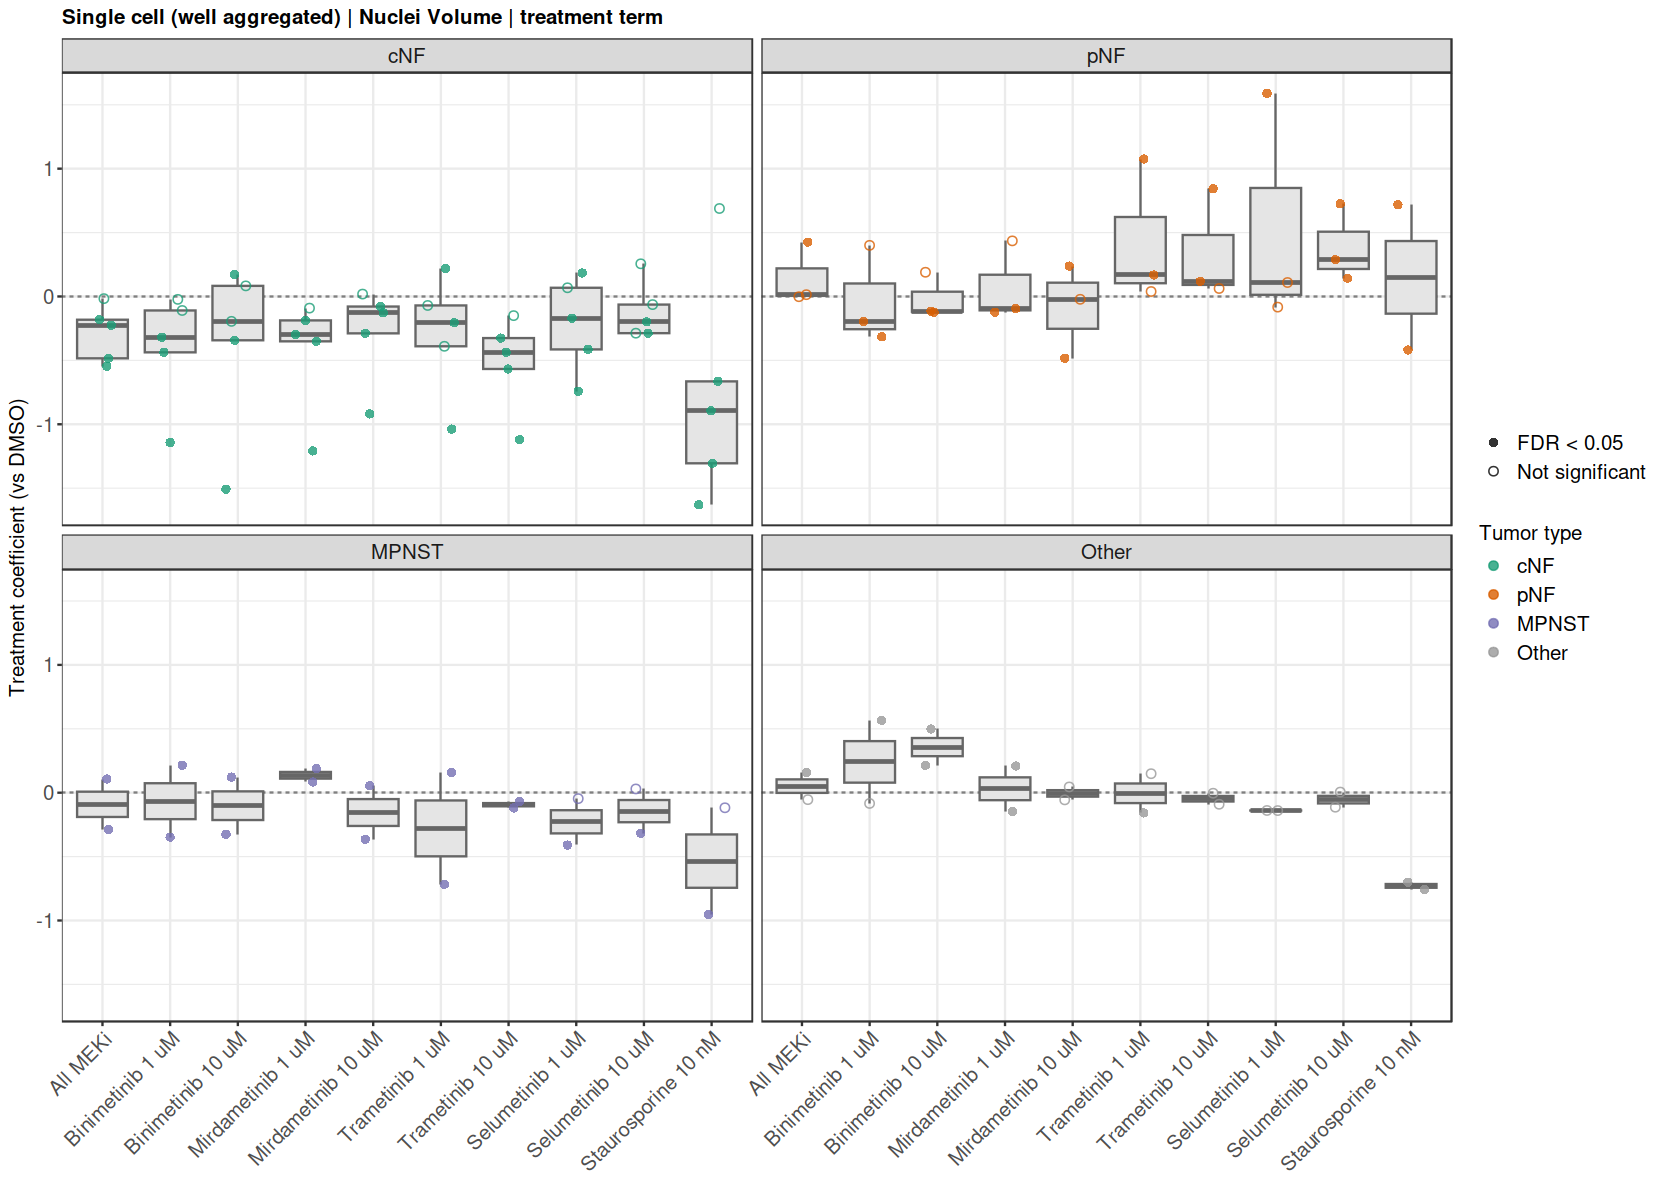

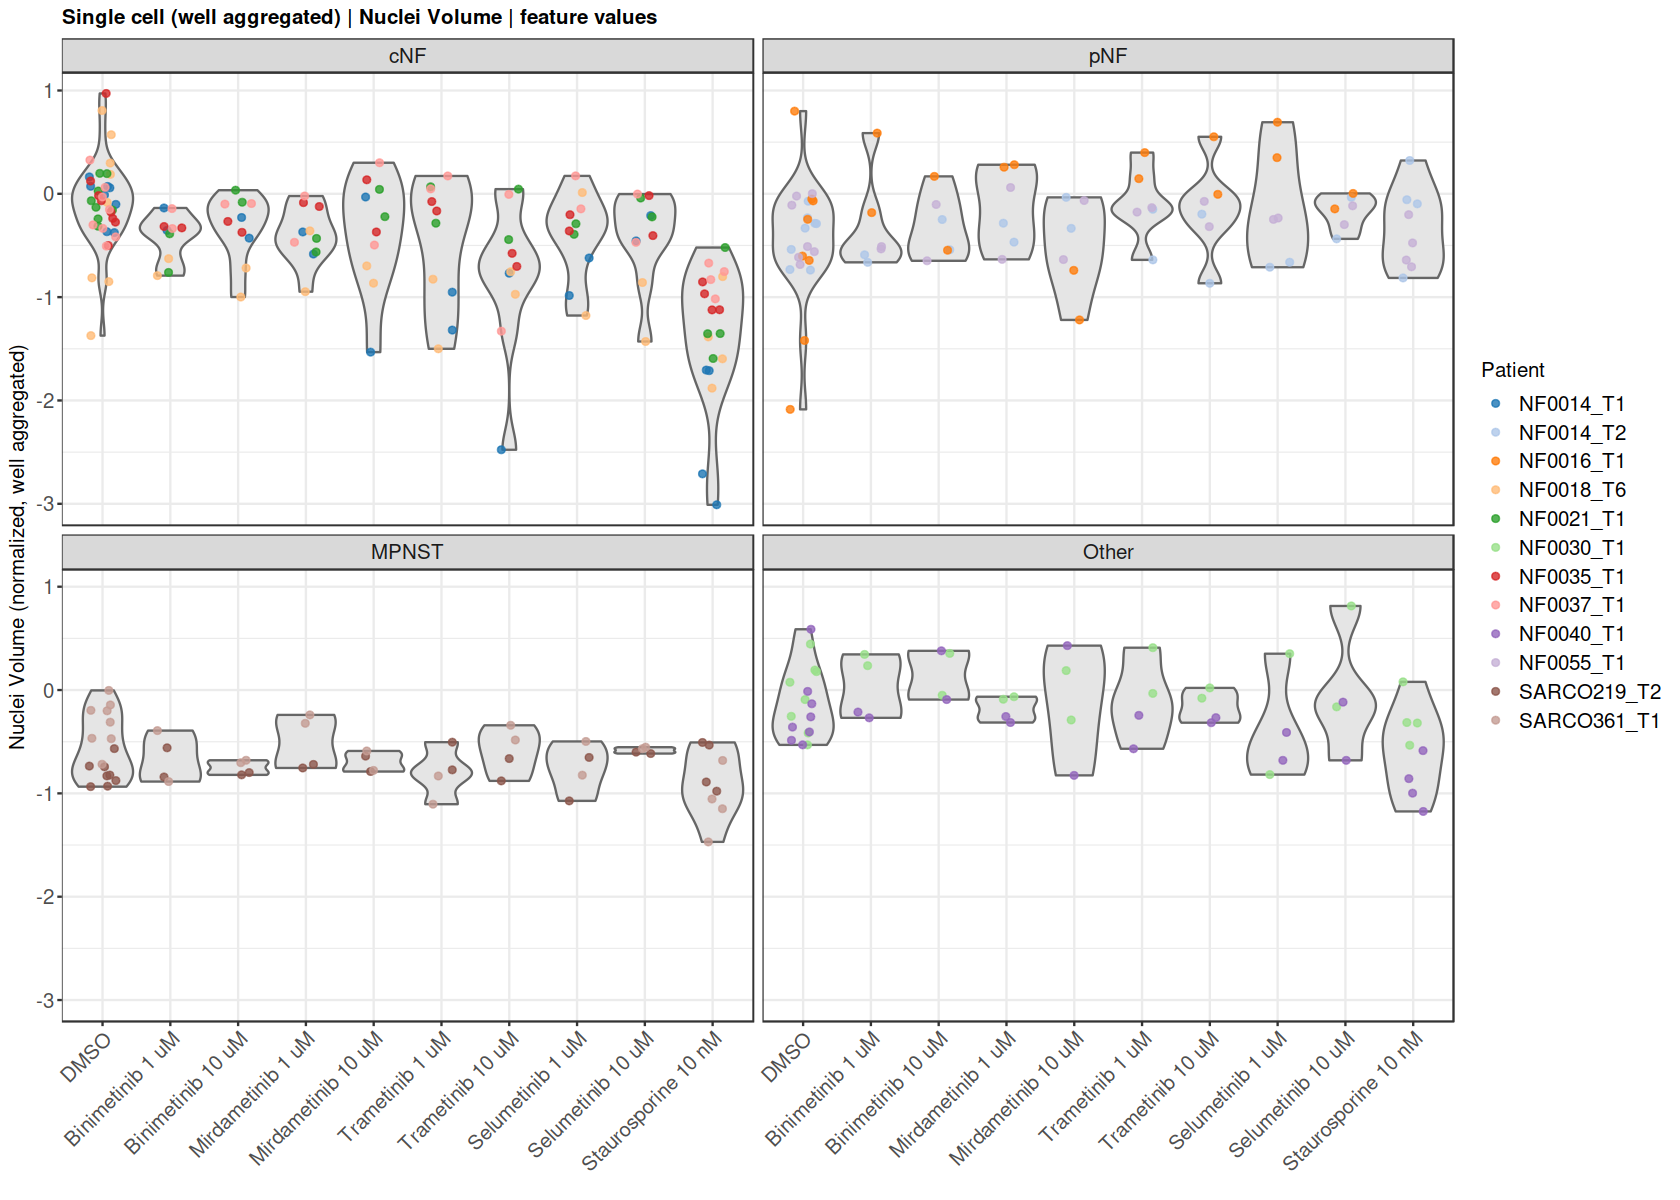

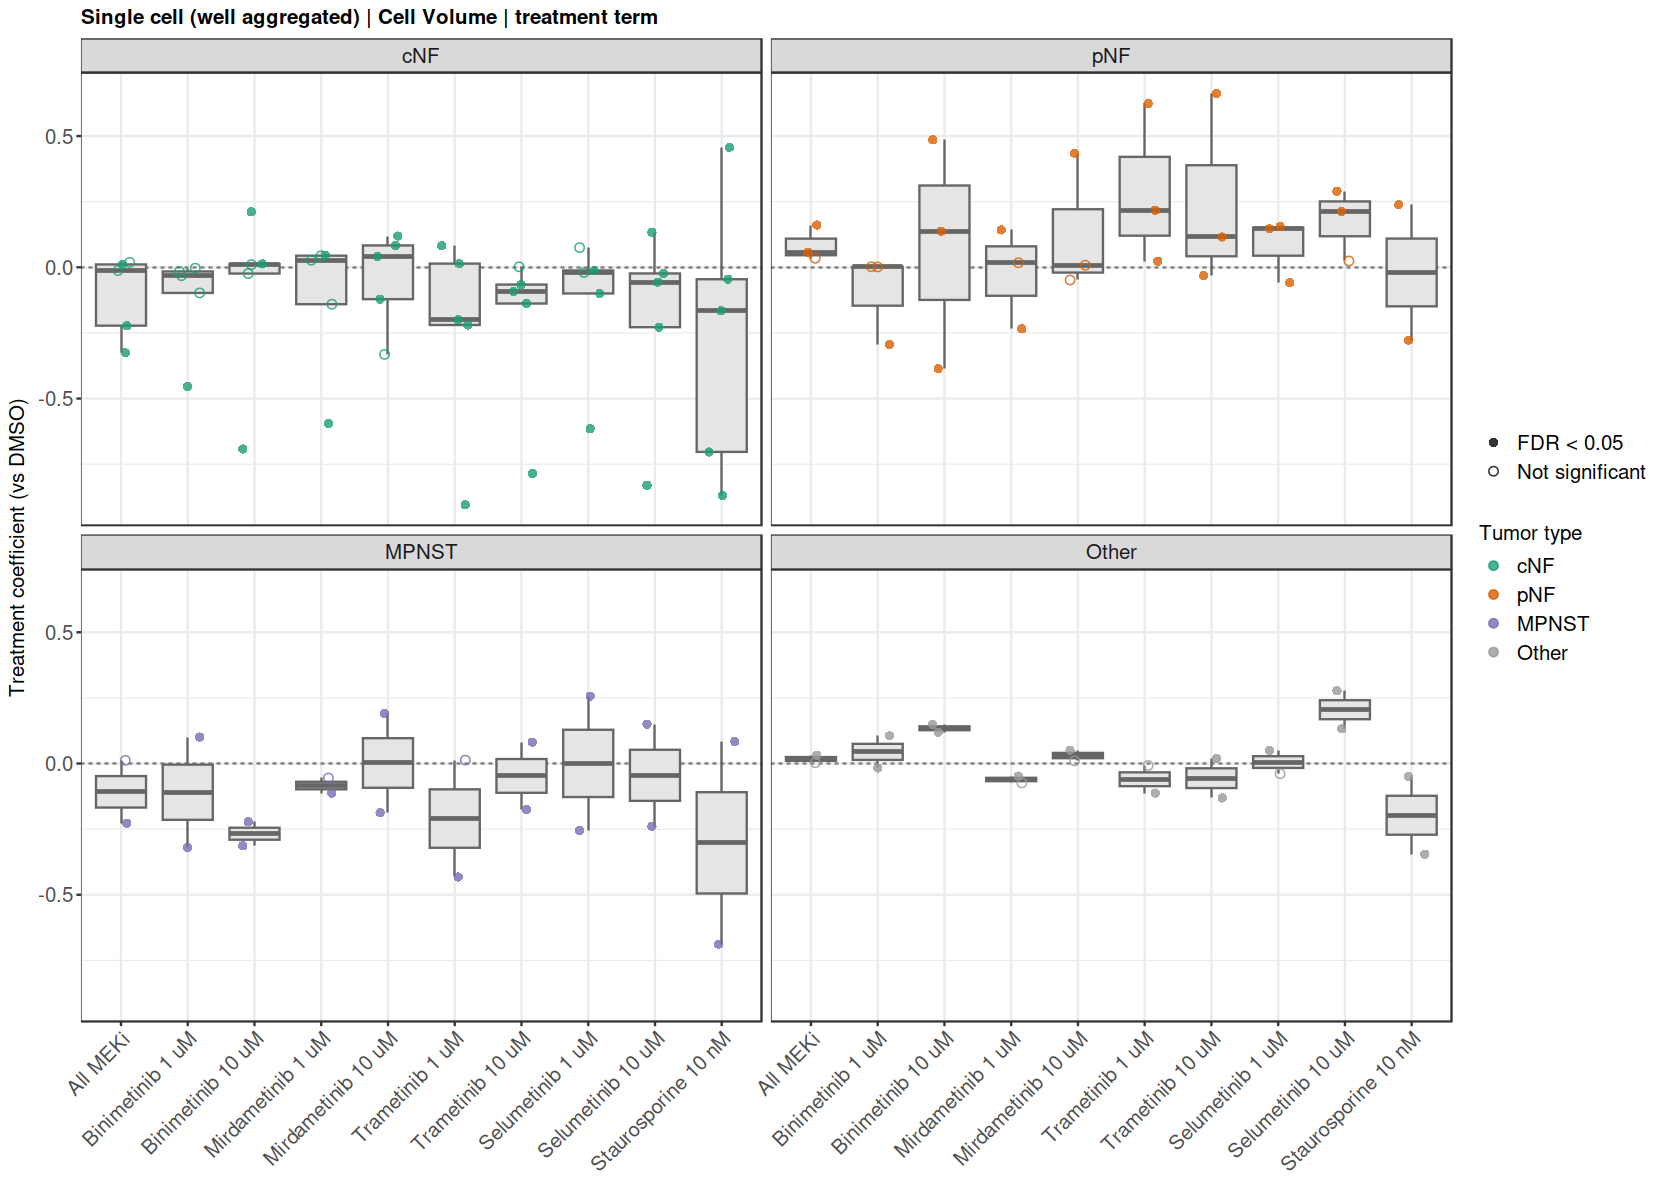

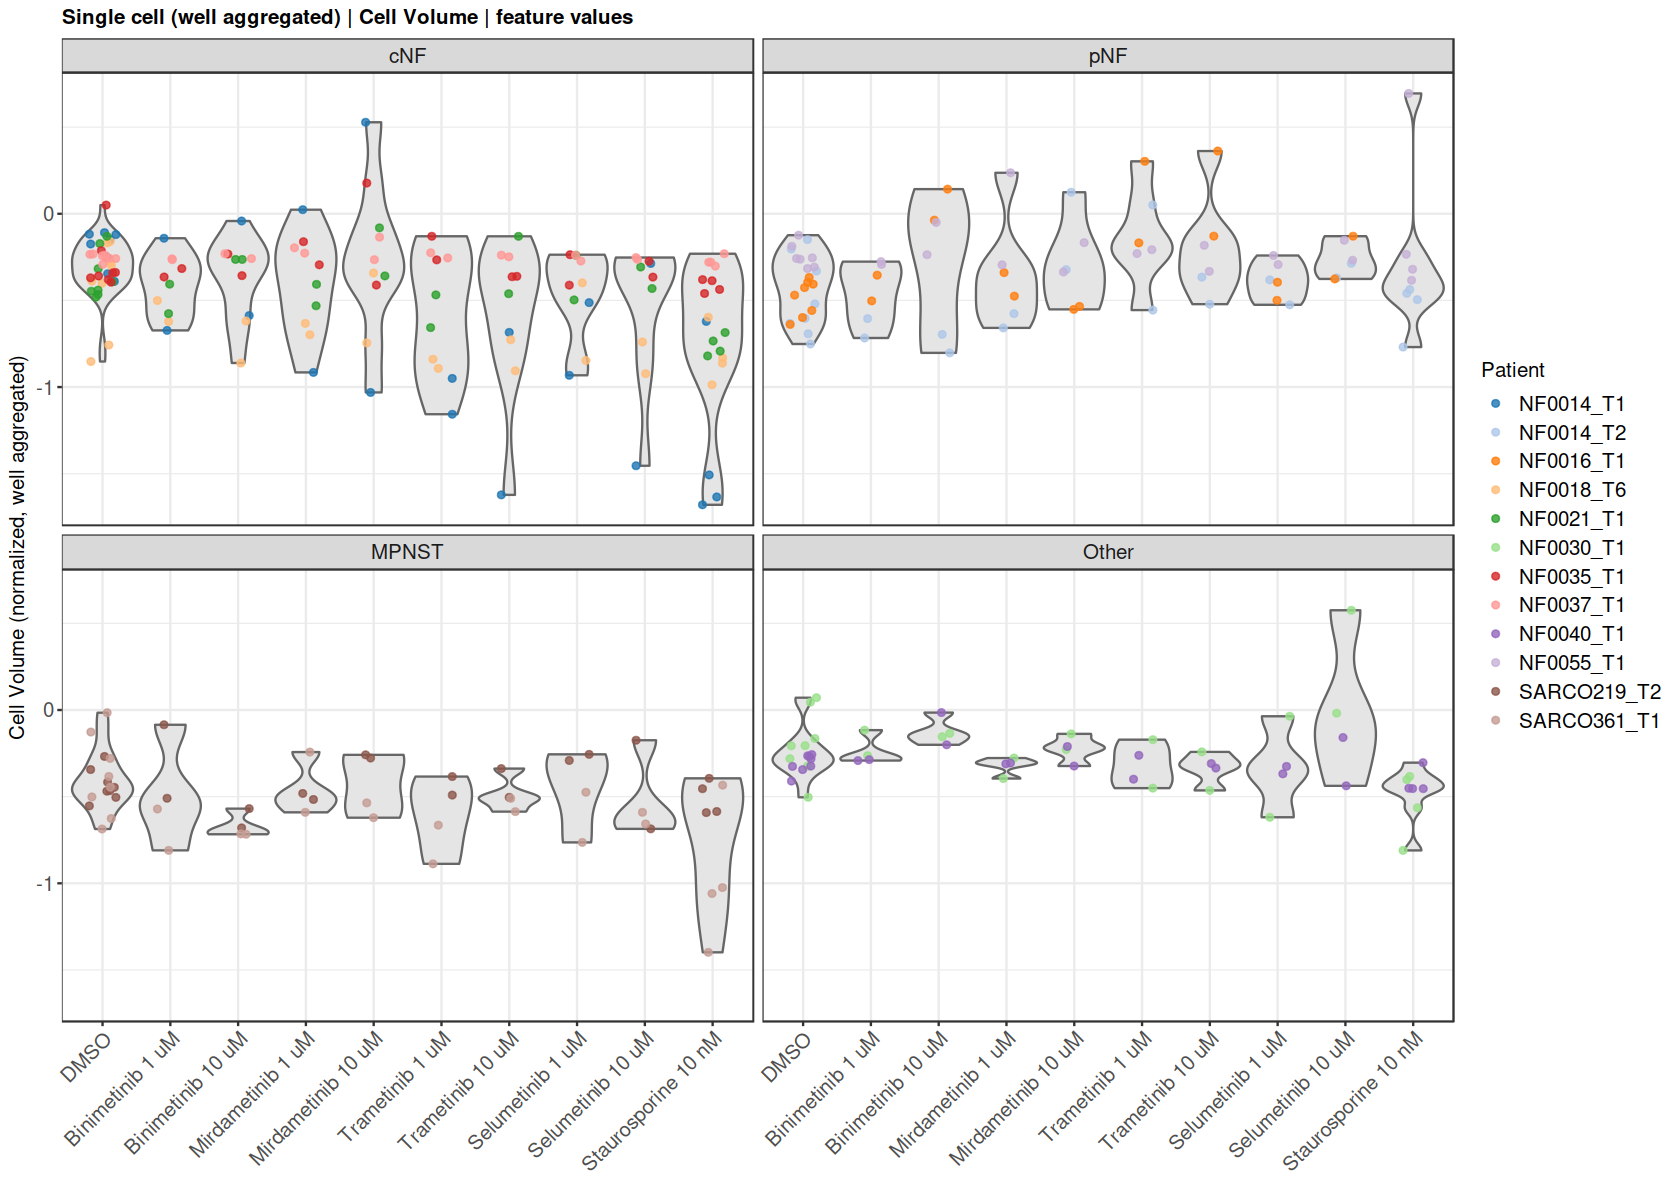

In [9]:
SELECTED_VOLUME_SIZE_SHAPE_FEATURES <- c(
    "Nuclei_NoChannel_VolumeSizeShape_Extent",
    "Nuclei_NoChannel_VolumeSizeShape_Volume",
    "Cell_NoChannel_VolumeSizeShape_Volume"
)

selected_volume_size_shape_plot <- function(feature_name) {
    plot_df <- volume_size_shape_df %>%
        filter(feature == feature_name) %>%
        droplevels()
    (
        ggplot(plot_df, aes(x = mek_group, y = coefficient))
        + geom_hline(yintercept = 0, linetype = "dashed", color = "grey50")
        + geom_boxplot(outlier.shape = NA, fill = "grey90", color = "grey40")
        + geom_point(
            aes(color = tumor_type, shape = significance),
            position = position_jitter(width = 0.2, height = 0, seed = 0),
            size = 2,
            alpha = 0.8
        )
        + scale_x_discrete(limits = mek_group_levels, drop = FALSE)
        + scale_color_manual(values = tumor_type_palette)
        + scale_shape_manual(
            values = setNames(c(16, 1), c(paste0("FDR < ", FDR_MAX), "Not significant"))
        )
        + facet_wrap(~tumor_type, nrow = 2, drop = FALSE)
        + labs(
            title = paste0(
                unique(plot_df$profile), " | ", unique(plot_df$feature_label), " | treatment term"
            ),
            x = NULL,
            y = "Treatment coefficient (vs DMSO)",
            color = "Tumor type",
            shape = NULL
        )
        + theme_manuscript(base_size = 12, x_text = "angled")
        + theme(strip.text.y = element_text(angle = 0))
    )
}

# well-level values of the selected features from the single cell (well aggregated) profile
value_group_levels <- c("DMSO", setdiff(mek_group_levels, POOLED_MEK_GROUP))
selected_values_df <- read_parquet(
    sc_agg_profile_path,
    col_select = c(
        "Metadata_Biology_PatientTumor", "Metadata_Experiment_Treatment", "Metadata_Experiment_Dose",
        all_of(SELECTED_VOLUME_SIZE_SHAPE_FEATURES)
    )
) %>%
    mutate(
        value_group = case_when(
            Metadata_Experiment_Treatment == "DMSO" ~ "DMSO",
            Metadata_Experiment_Treatment == "Staurosporine" ~ STAUROSPORINE_GROUP,
            Metadata_Experiment_Treatment %in% mek_drug_order ~ paste0(
                Metadata_Experiment_Treatment, " ", Metadata_Experiment_Dose, " uM"
            )
        )
    ) %>%
    filter(!is.na(value_group)) %>%
    # only the patients step 3 modeled, so the values match the coefficient pages
    # (e.g. the NF0037_T1_CQ1 re-imaging is in the profile but was not modeled)
    inner_join(patient_tumor_type_df, by = "Metadata_Biology_PatientTumor") %>%
    mutate(
        value_group = factor(value_group, levels = value_group_levels),
        tumor_type = factor(Metadata_Biology_TumorType, levels = tumor_type_levels)
    ) %>%
    pivot_longer(
        all_of(SELECTED_VOLUME_SIZE_SHAPE_FEATURES), names_to = "feature", values_to = "value"
    ) %>%
    filter(!is.na(value))
stopifnot(!anyNA(selected_values_df$tumor_type), !anyNA(selected_values_df$value_group))
# patient colors come from patient_palette in utils/r_plot_themes.r, shared with the heatmaps
stopifnot(all(selected_values_df$Metadata_Biology_PatientTumor %in% names(patient_palette)))

selected_value_plot <- function(feature_name) {
    plot_df <- selected_values_df %>% filter(feature == feature_name)
    feature_label <- sub("_NoChannel_VolumeSizeShape_", " ", feature_name)
    (
        ggplot(plot_df, aes(x = value_group, y = value))
        + geom_violin(fill = "grey90", color = "grey40", scale = "width")
        + geom_point(
            aes(color = Metadata_Biology_PatientTumor),
            position = position_jitter(width = 0.2, height = 0, seed = 0),
            size = 1.5,
            alpha = 0.8
        )
        + scale_x_discrete(limits = value_group_levels, drop = FALSE)
        + scale_color_manual(values = patient_palette)
        + facet_wrap(~tumor_type, nrow = 2, drop = FALSE)
        + labs(
            title = paste0("Single cell (well aggregated) | ", feature_label, " | feature values"),
            x = NULL,
            y = paste0(feature_label, " (normalized, well aggregated)"),
            color = "Patient"
        )
        + theme_manuscript(base_size = 12, x_text = "angled")
    )
}

# each feature's coefficient page followed by its feature value page
selected_volume_size_shape_plots <- unlist(
    lapply(SELECTED_VOLUME_SIZE_SHAPE_FEATURES, function(feature_name) {
        list(selected_volume_size_shape_plot(feature_name), selected_value_plot(feature_name))
    }),
    recursive = FALSE
)
options(repr.plot.width = 14, repr.plot.height = 10)
save_plots_pdf(
    selected_volume_size_shape_plots, selected_volume_size_shape_path,
    width = 14, height = 10
)
for (selected_page in selected_volume_size_shape_plots) print(selected_page)

## Shared treatment features across MEKi groups
Each element is a patient x feature pair that is significant for treatment; the sets are the MEKi groups, so each bar counts the pairs found by exactly that combination of groups.
The first page per profile pools all patients; the following pages show each tumor type.

Warning message:
“Removed 406 rows containing non-finite outside the scale range
(`stat_count()`).”
Warning message:
“Removed 406 rows containing non-finite outside the scale range
(`stat_count()`).”
Warning message:
“Using `size` aesthetic for lines was deprecated in ggplot2 3.4.0.
ℹ Please use `linewidth` instead.
ℹ The deprecated feature was likely used in the ggupset package.
  Please report the issue at <https://github.com/const-ae/ggupset/issues>.”
Warning message:
“Removed 35 rows containing non-finite outside the scale range (`stat_count()`).”
Warning message:
“Removed 35 rows containing non-finite outside the scale range (`stat_count()`).”
Warning message:
“Removed 13 rows containing non-finite outside the scale range (`stat_count()`).”
Warning message:
“Removed 13 rows containing non-finite outside the scale range (`stat_count()`).”
Warning message:
“Removed 124 rows containing non-finite outside the scale range
(`stat_count()`).”
Warning message:
“Removed 124 rows containing

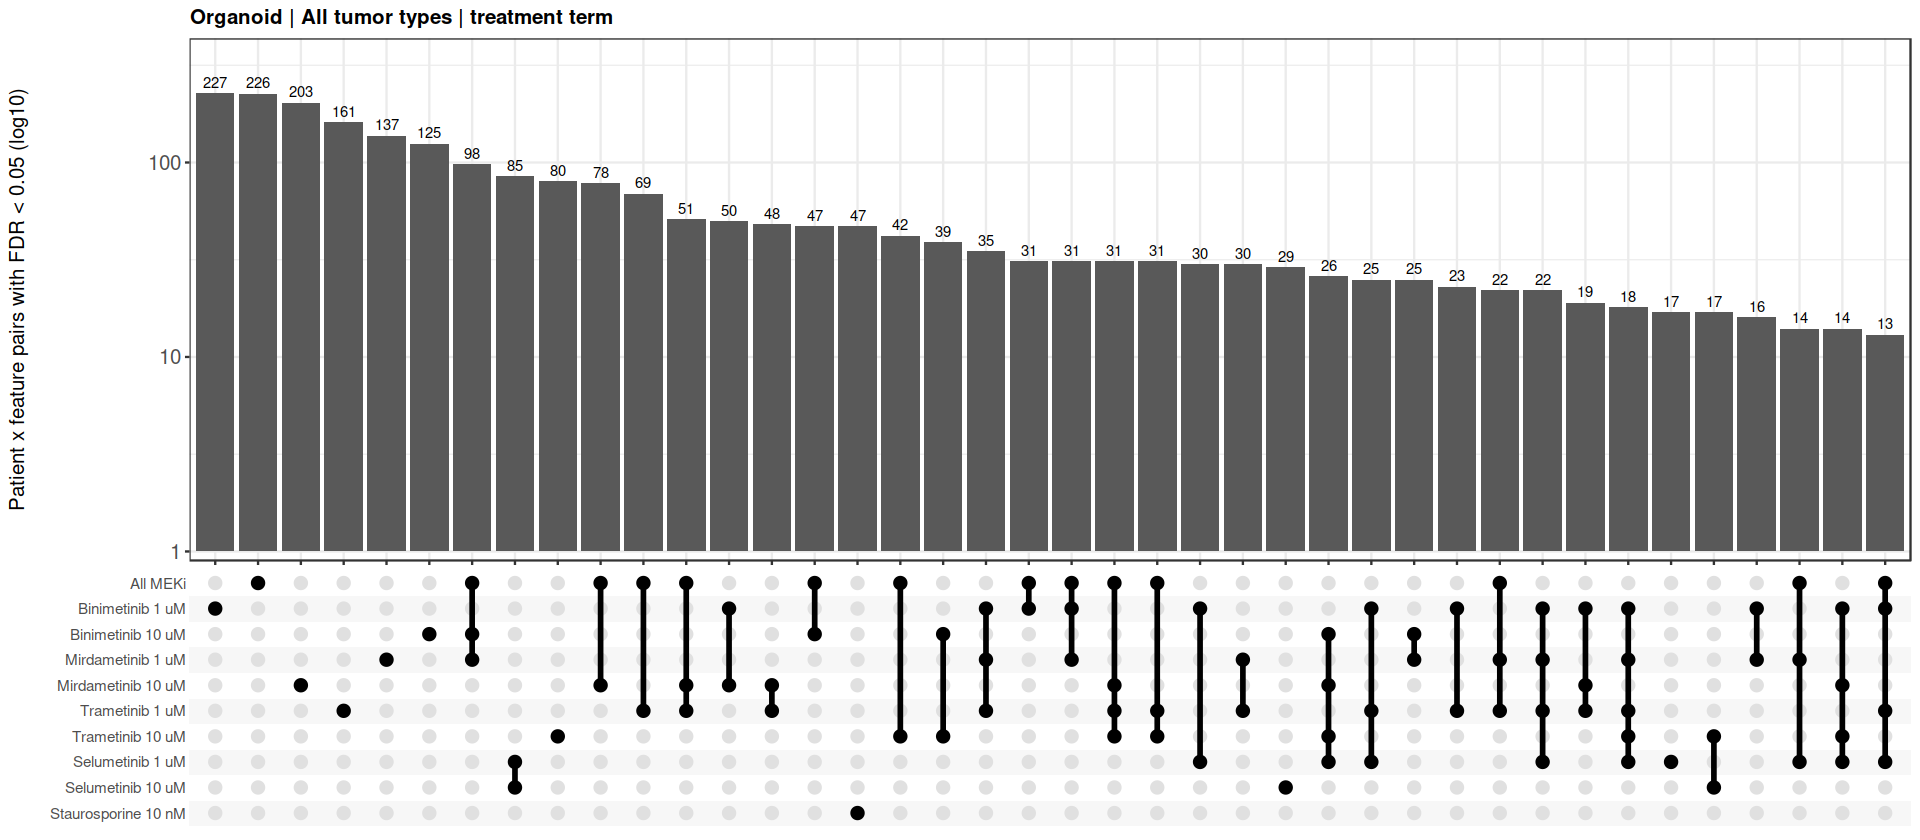

Warning message:
“Removed 13 rows containing non-finite outside the scale range (`stat_count()`).”
Warning message:
“Removed 13 rows containing non-finite outside the scale range (`stat_count()`).”


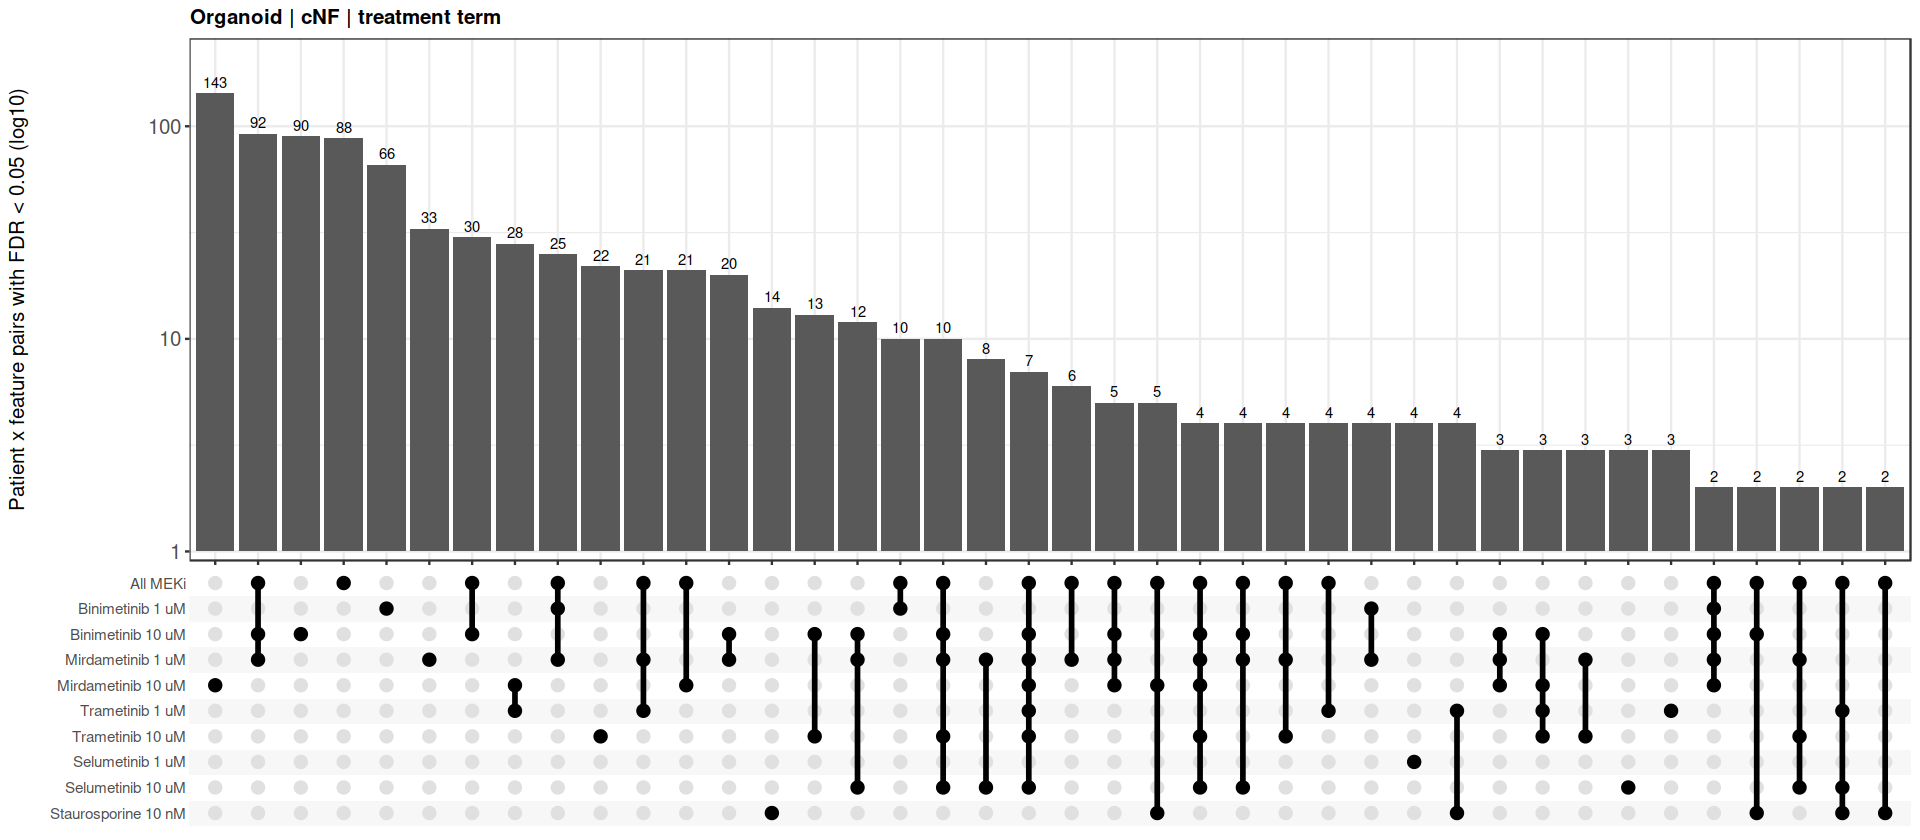

Warning message:
“Removed 124 rows containing non-finite outside the scale range
(`stat_count()`).”
Warning message:
“Removed 124 rows containing non-finite outside the scale range
(`stat_count()`).”


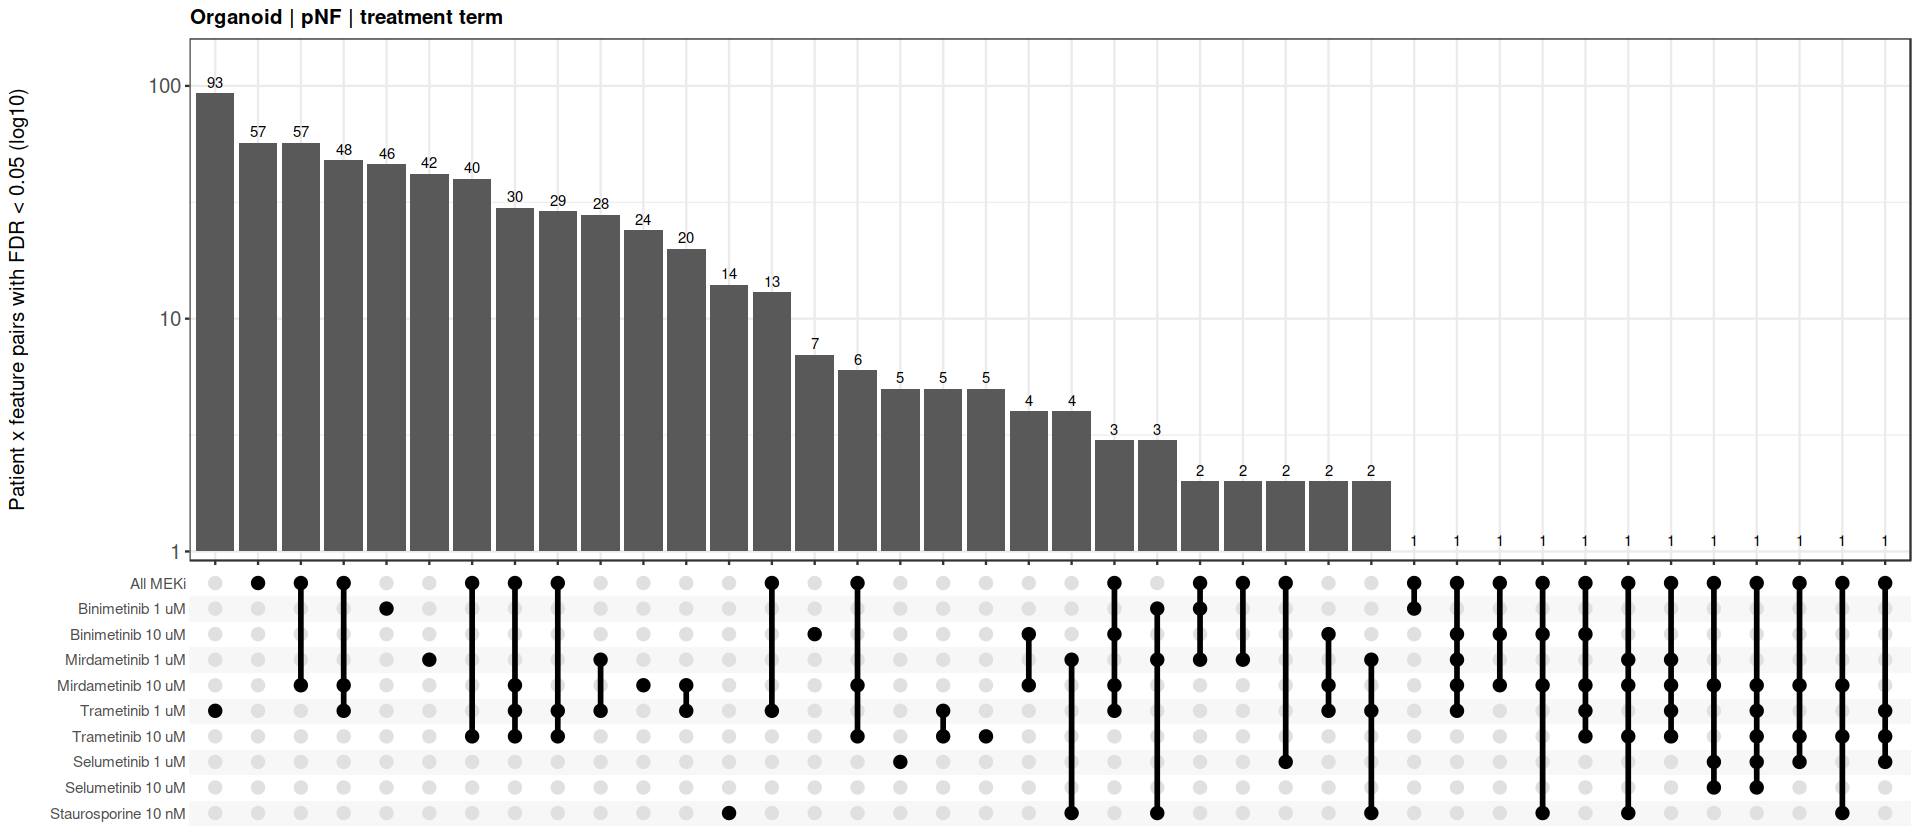

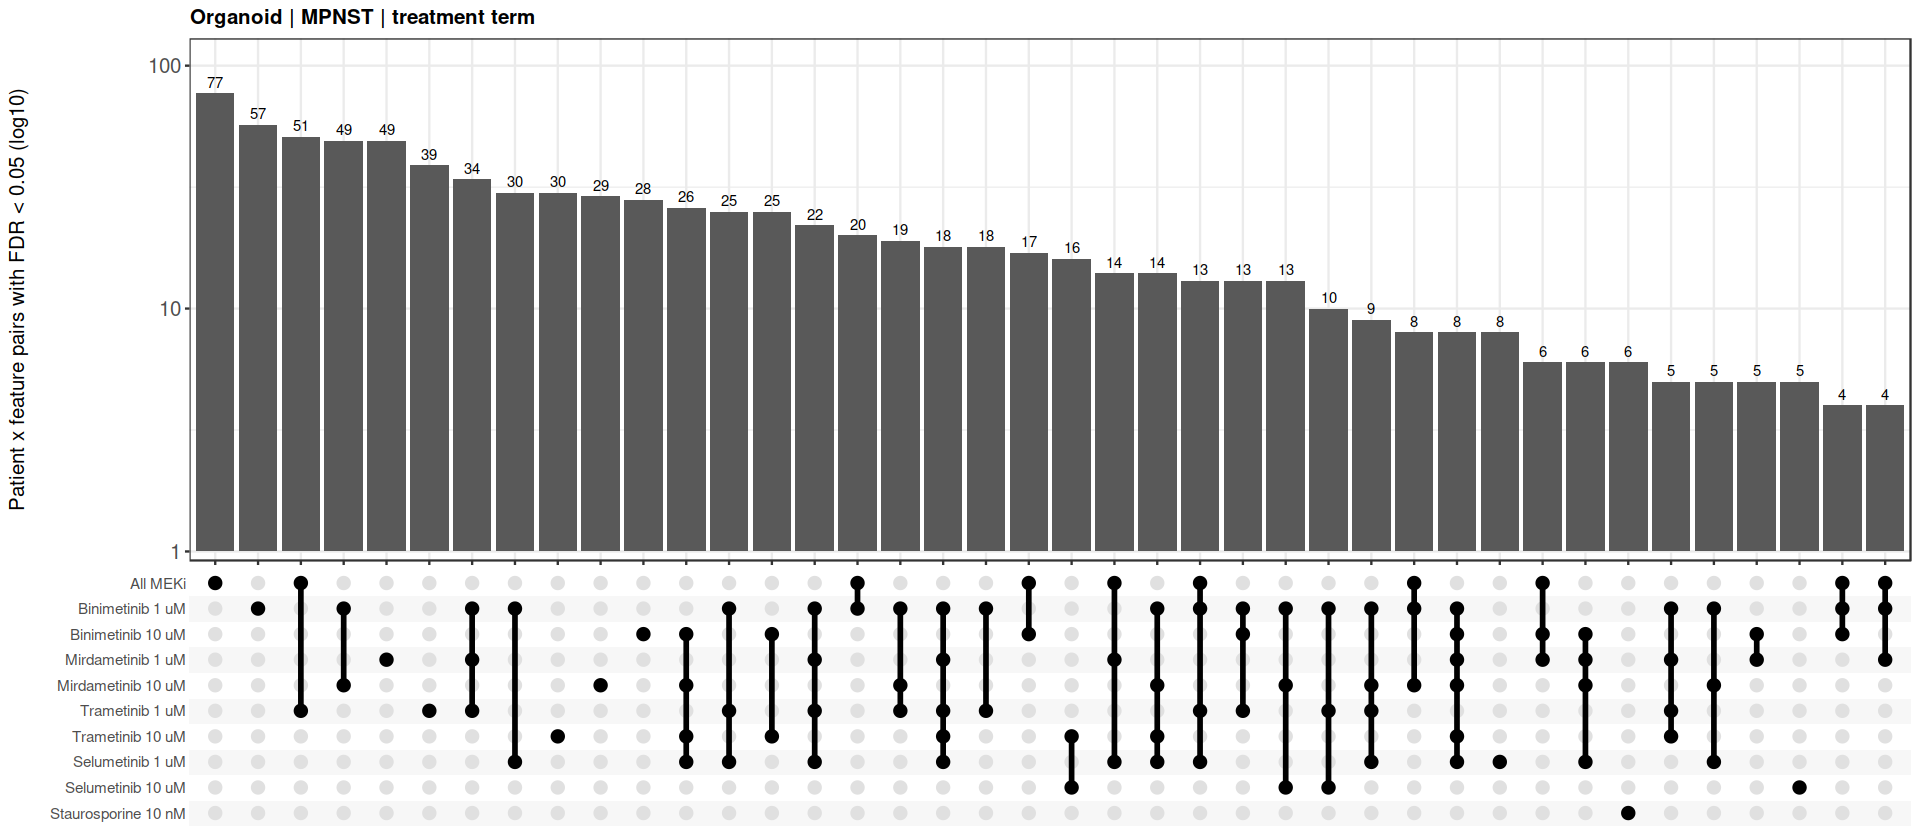

Warning message:
“Removed 21874 rows containing non-finite outside the scale range
(`stat_count()`).”
Warning message:
“Removed 21874 rows containing non-finite outside the scale range
(`stat_count()`).”


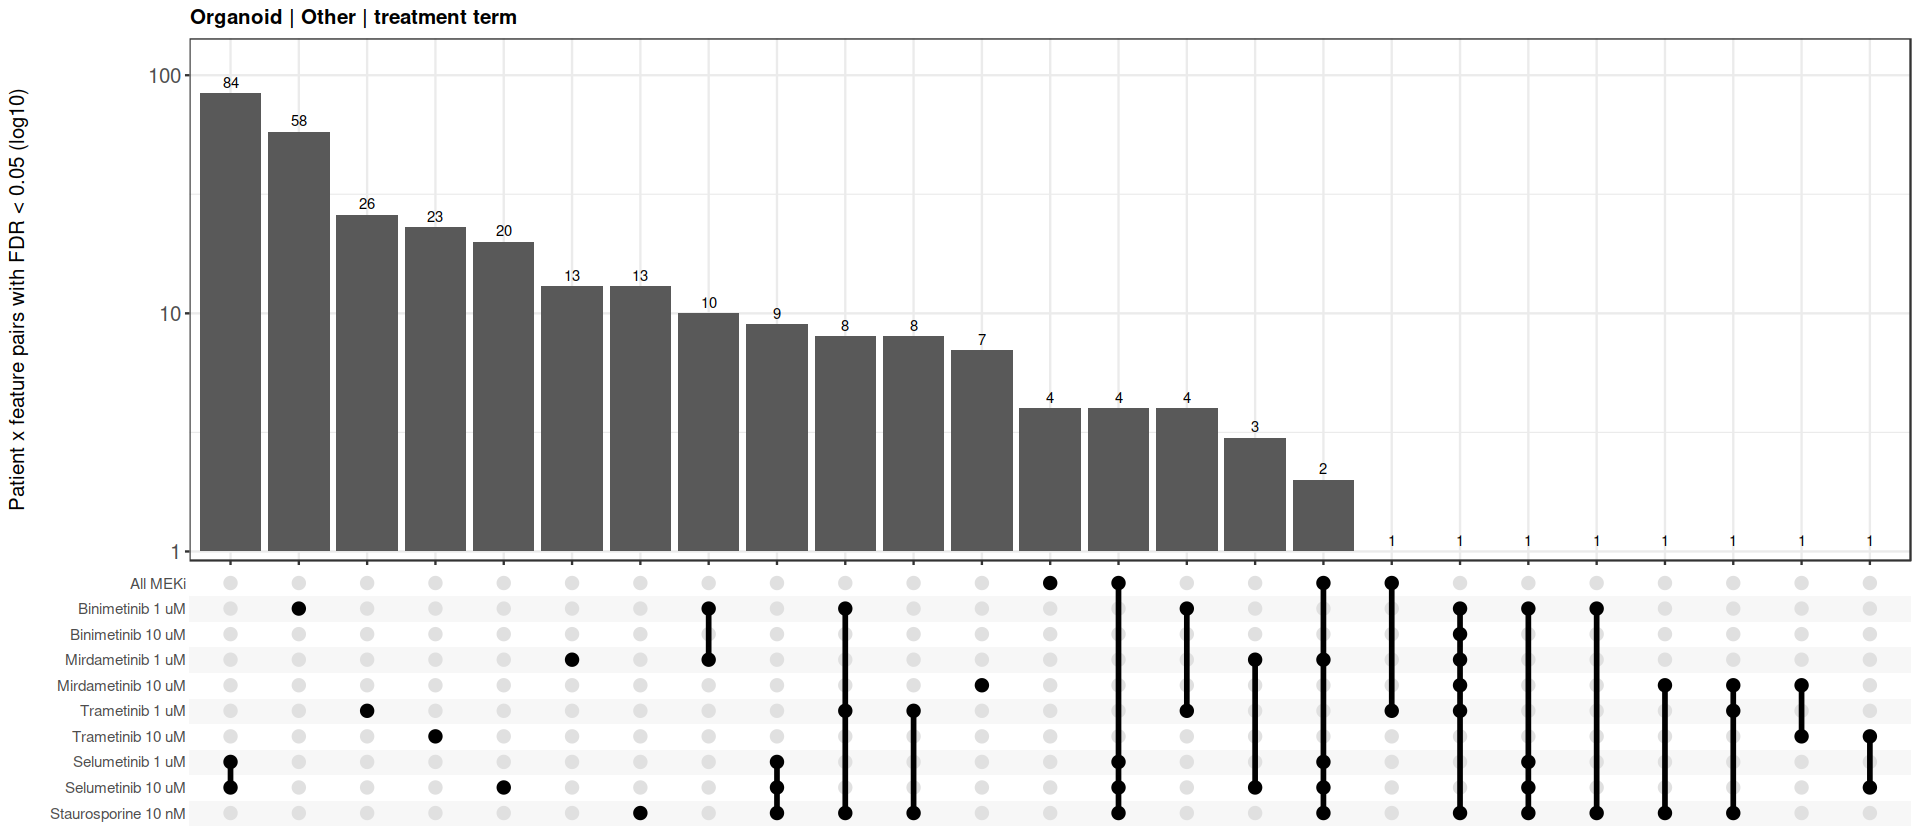

Warning message:
“Removed 8228 rows containing non-finite outside the scale range
(`stat_count()`).”
Warning message:
“Removed 8228 rows containing non-finite outside the scale range
(`stat_count()`).”


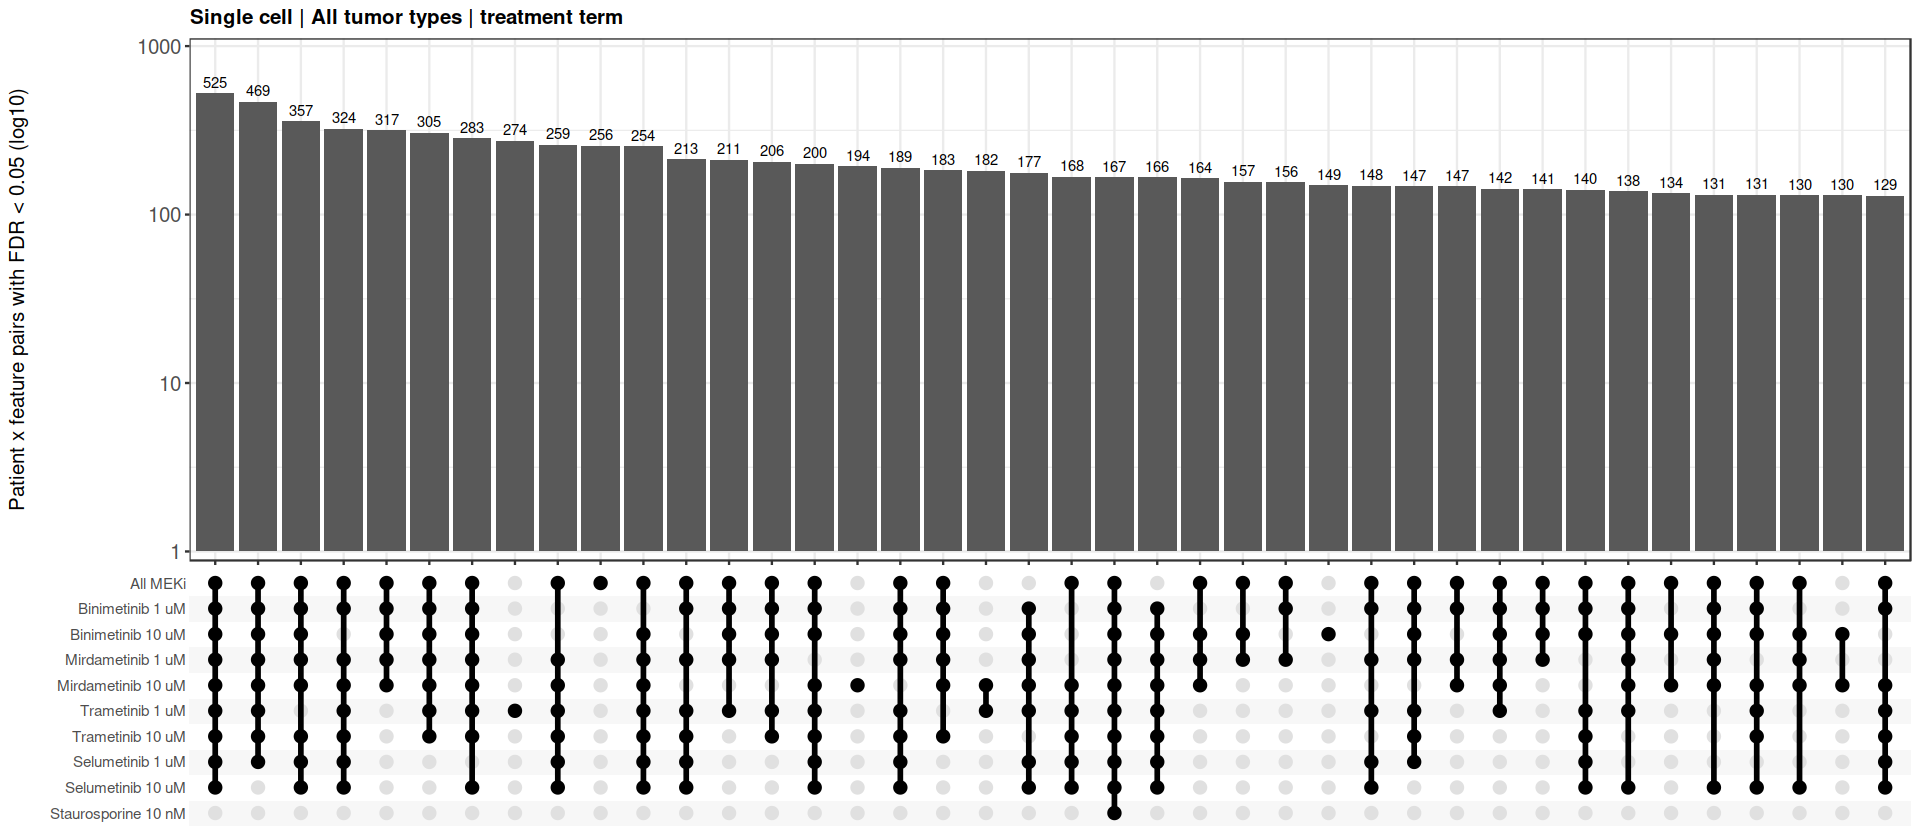

Warning message:
“Removed 4627 rows containing non-finite outside the scale range
(`stat_count()`).”
Warning message:
“Removed 4627 rows containing non-finite outside the scale range
(`stat_count()`).”


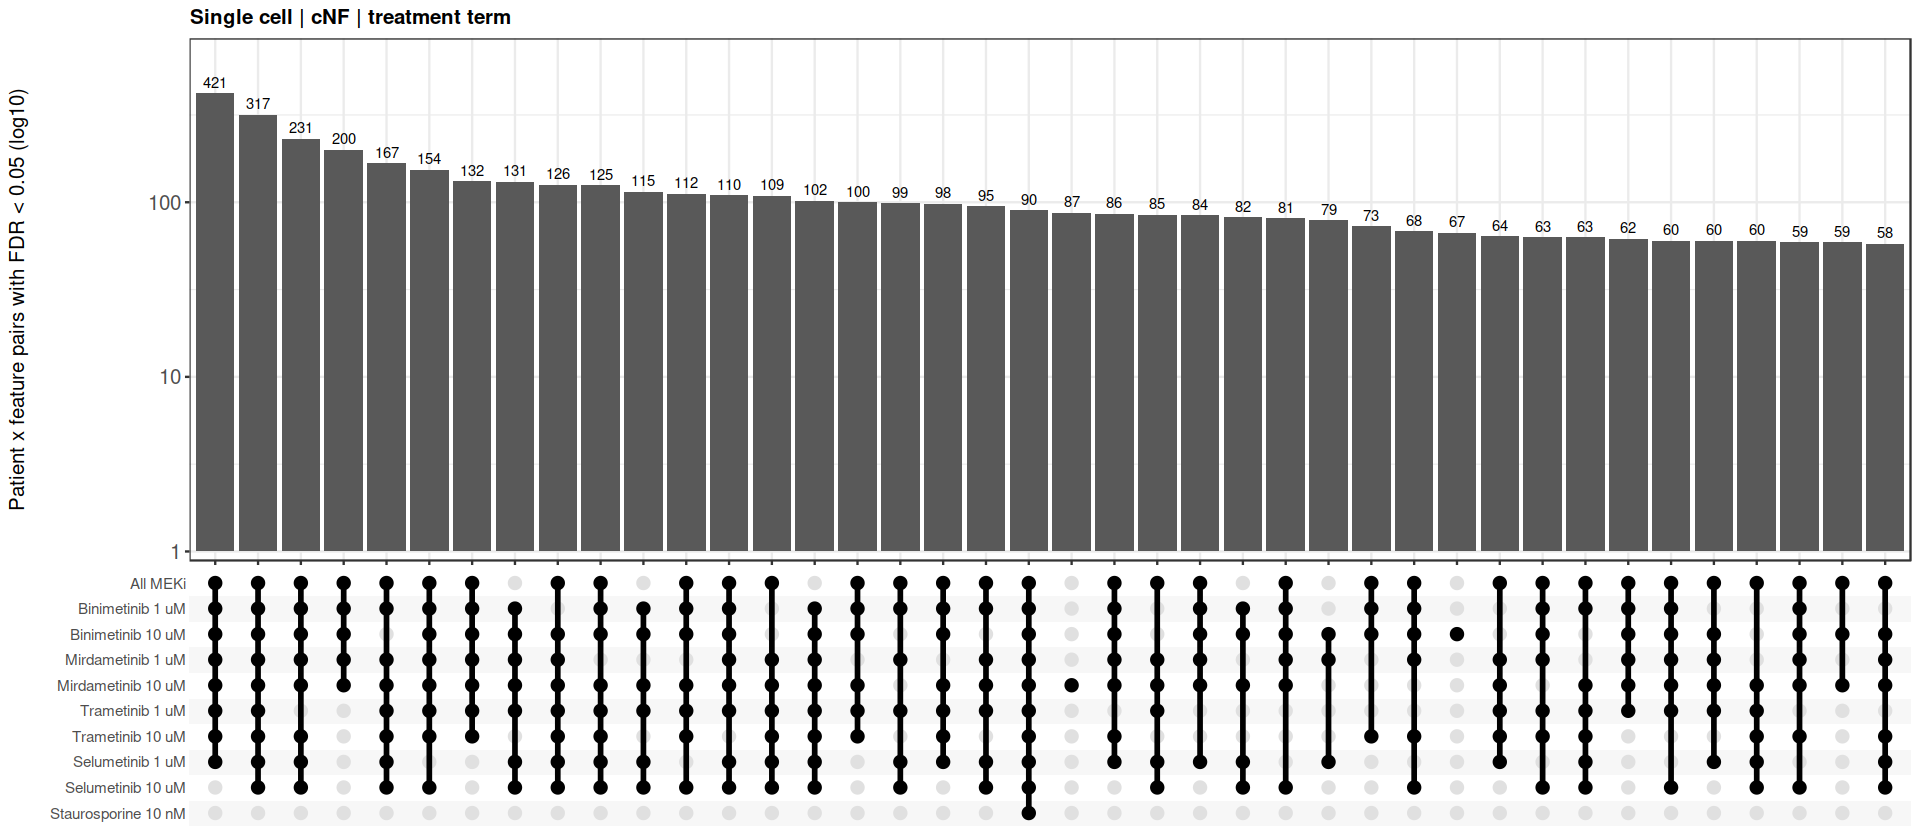

Warning message:
“Removed 3003 rows containing non-finite outside the scale range
(`stat_count()`).”
Warning message:
“Removed 3003 rows containing non-finite outside the scale range
(`stat_count()`).”


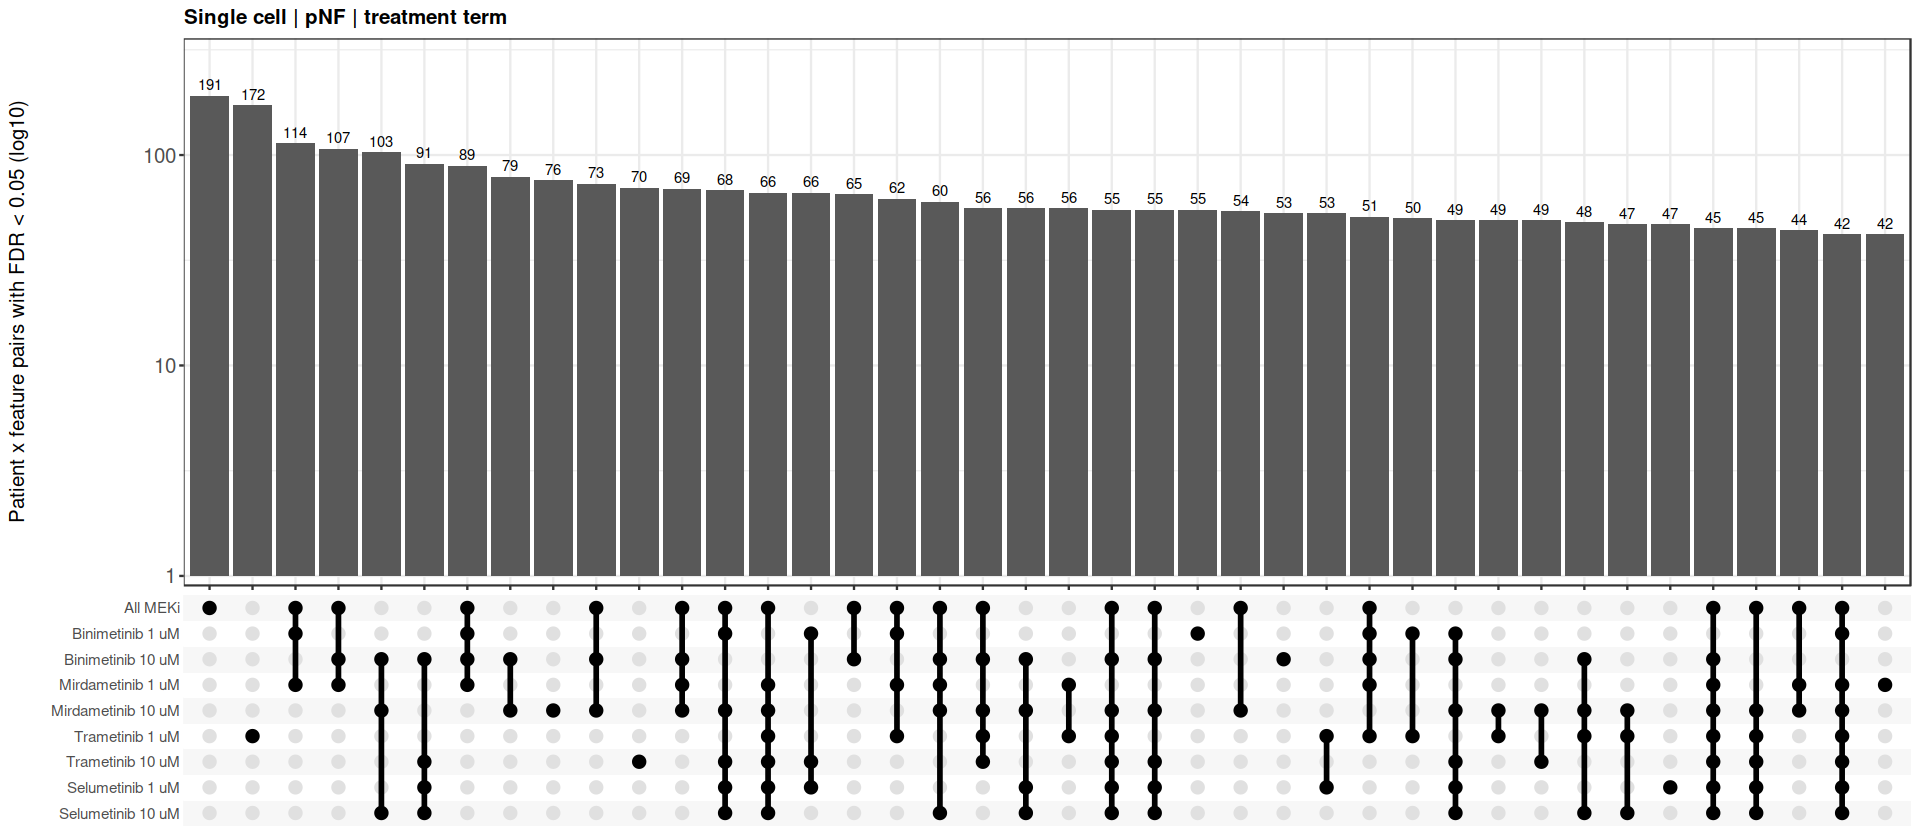

Warning message:
“Removed 3080 rows containing non-finite outside the scale range
(`stat_count()`).”
Warning message:
“Removed 3080 rows containing non-finite outside the scale range
(`stat_count()`).”


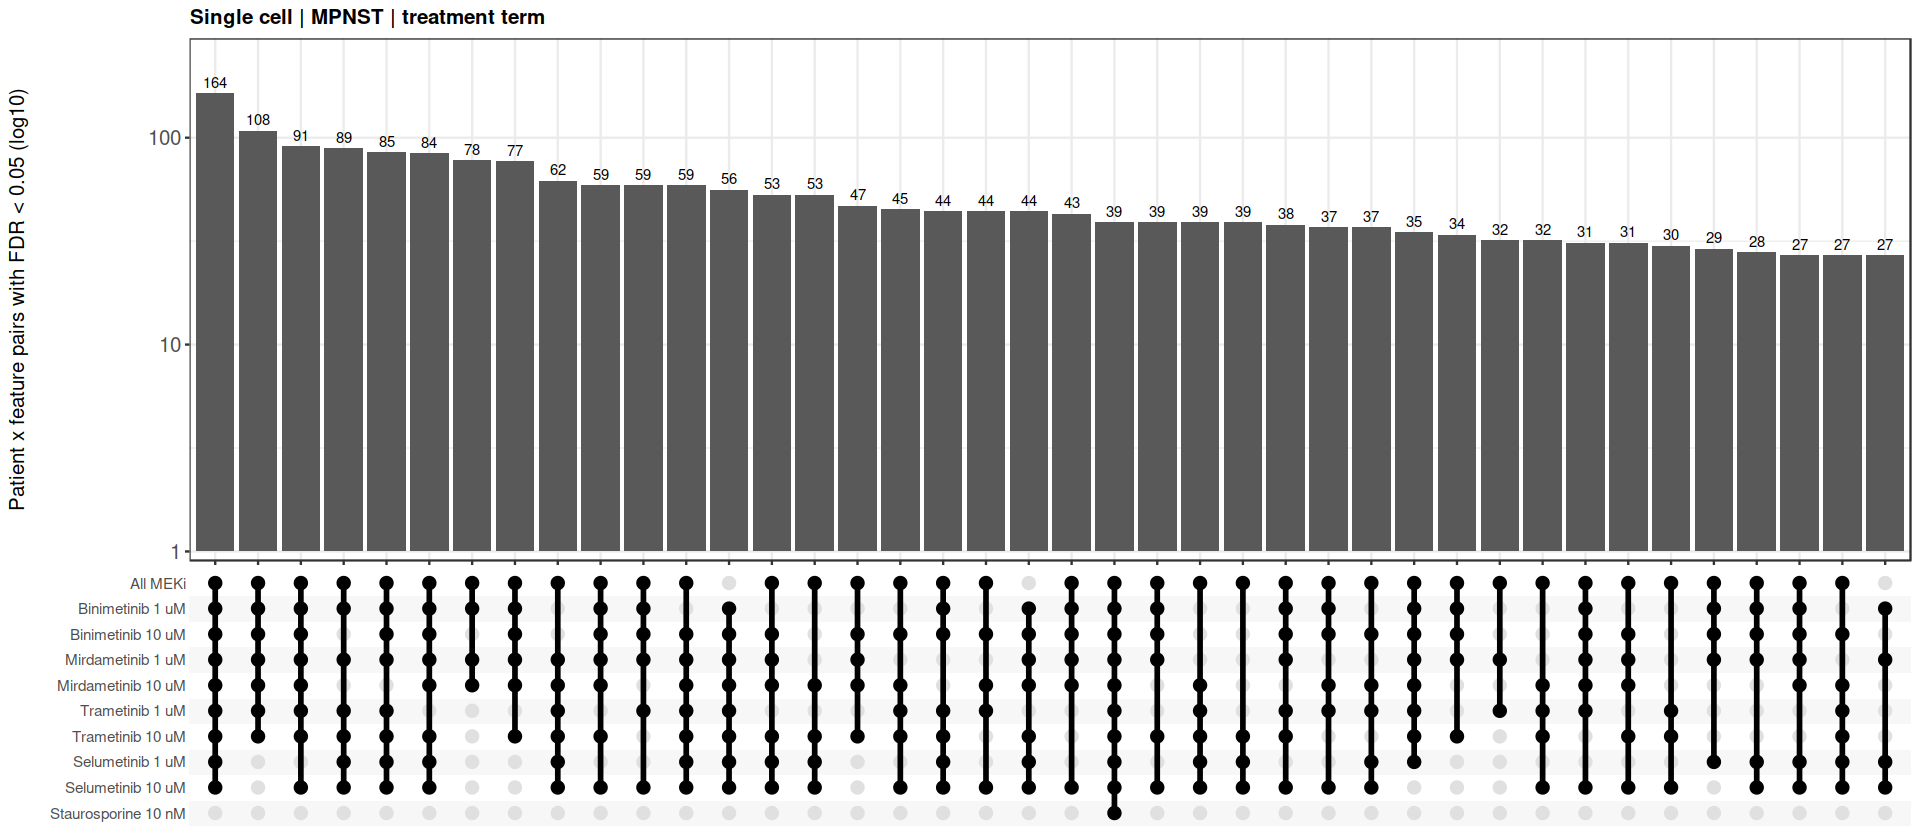

`geom_line()`: Each group consists of only one observation.
ℹ Do you need to adjust the group aesthetic?
`geom_line()`: Each group consists of only one observation.
ℹ Do you need to adjust the group aesthetic?


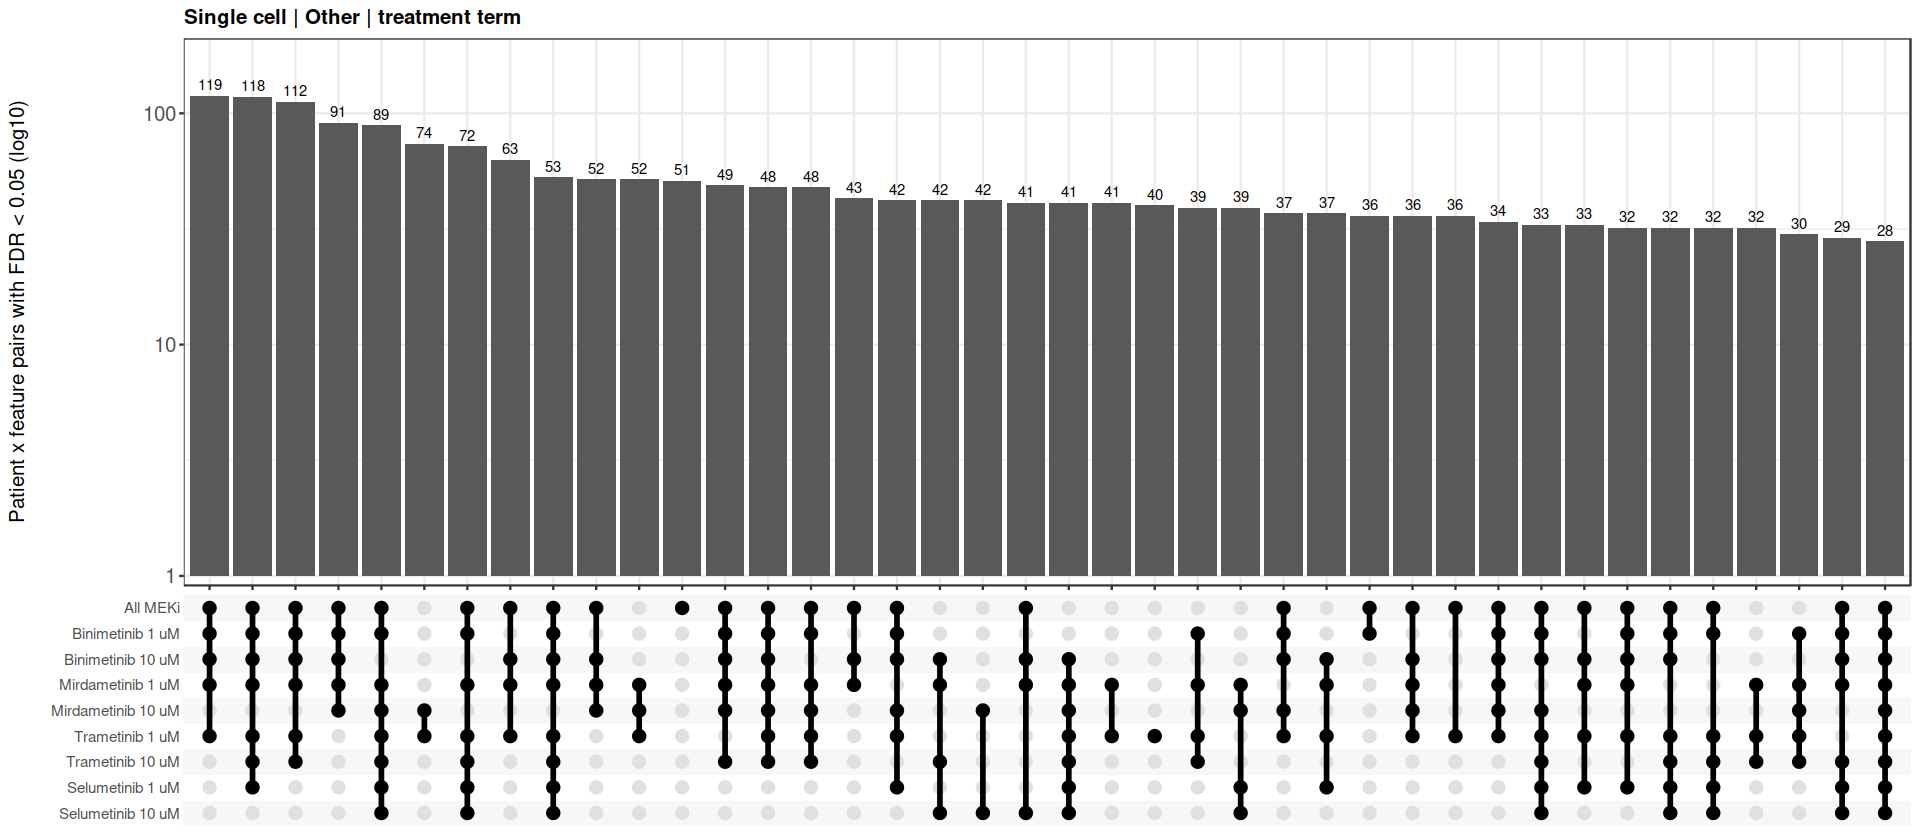

`geom_line()`: Each group consists of only one observation.
ℹ Do you need to adjust the group aesthetic?
`geom_line()`: Each group consists of only one observation.
ℹ Do you need to adjust the group aesthetic?


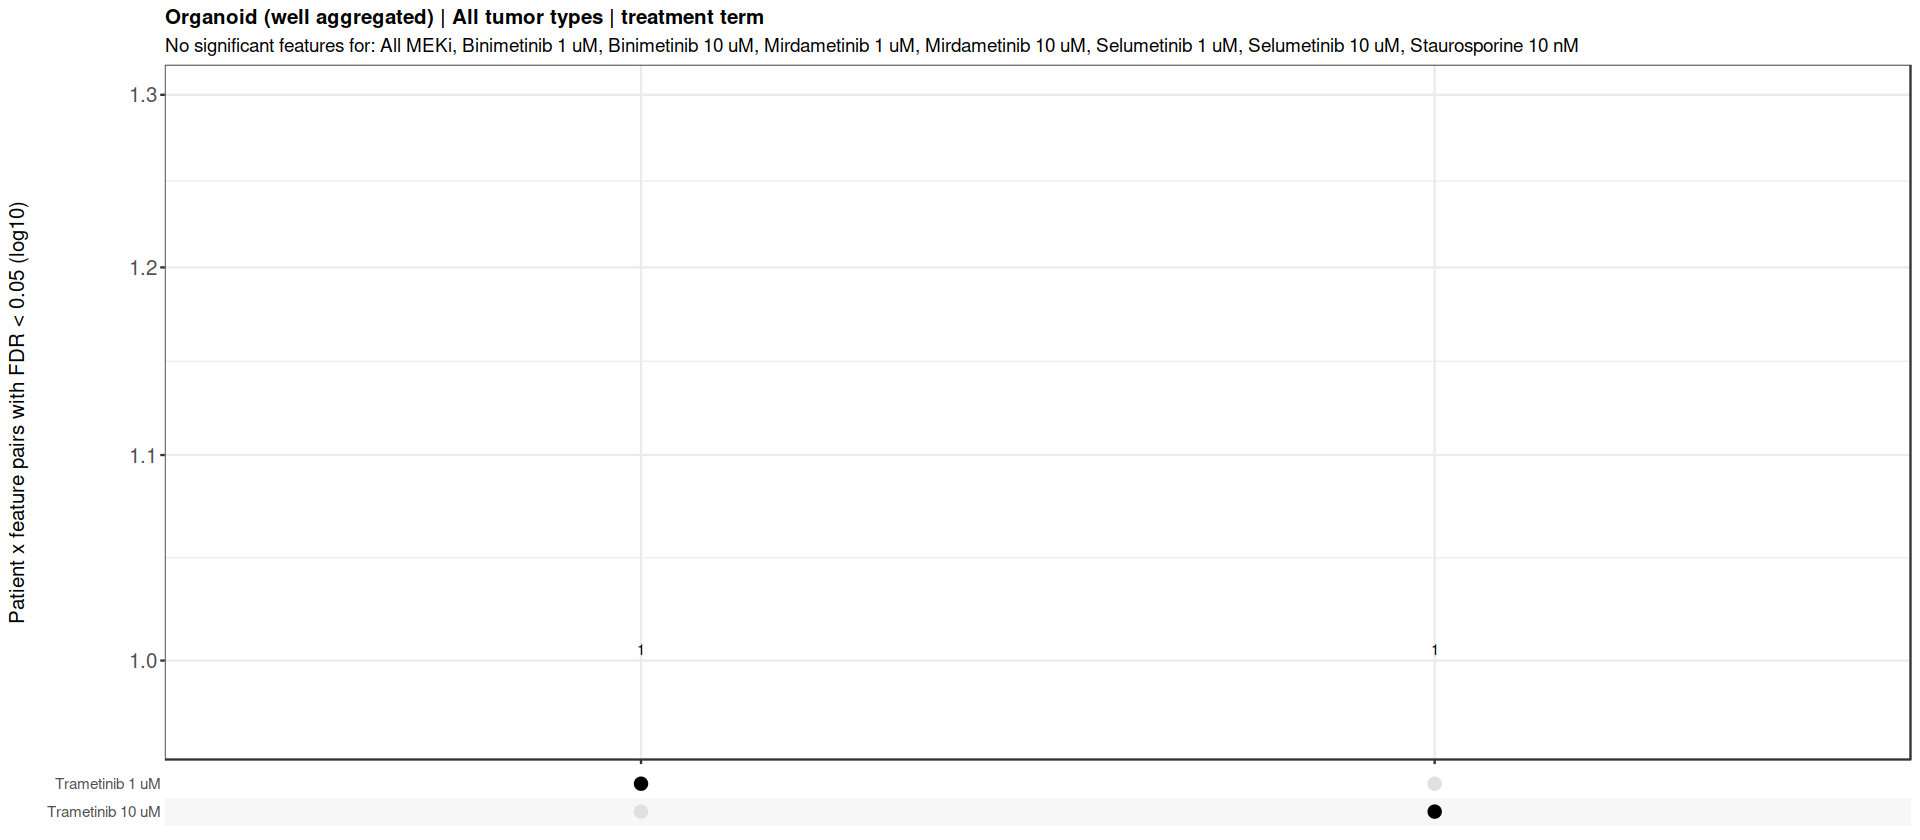

`geom_line()`: Each group consists of only one observation.
ℹ Do you need to adjust the group aesthetic?
`geom_line()`: Each group consists of only one observation.
ℹ Do you need to adjust the group aesthetic?


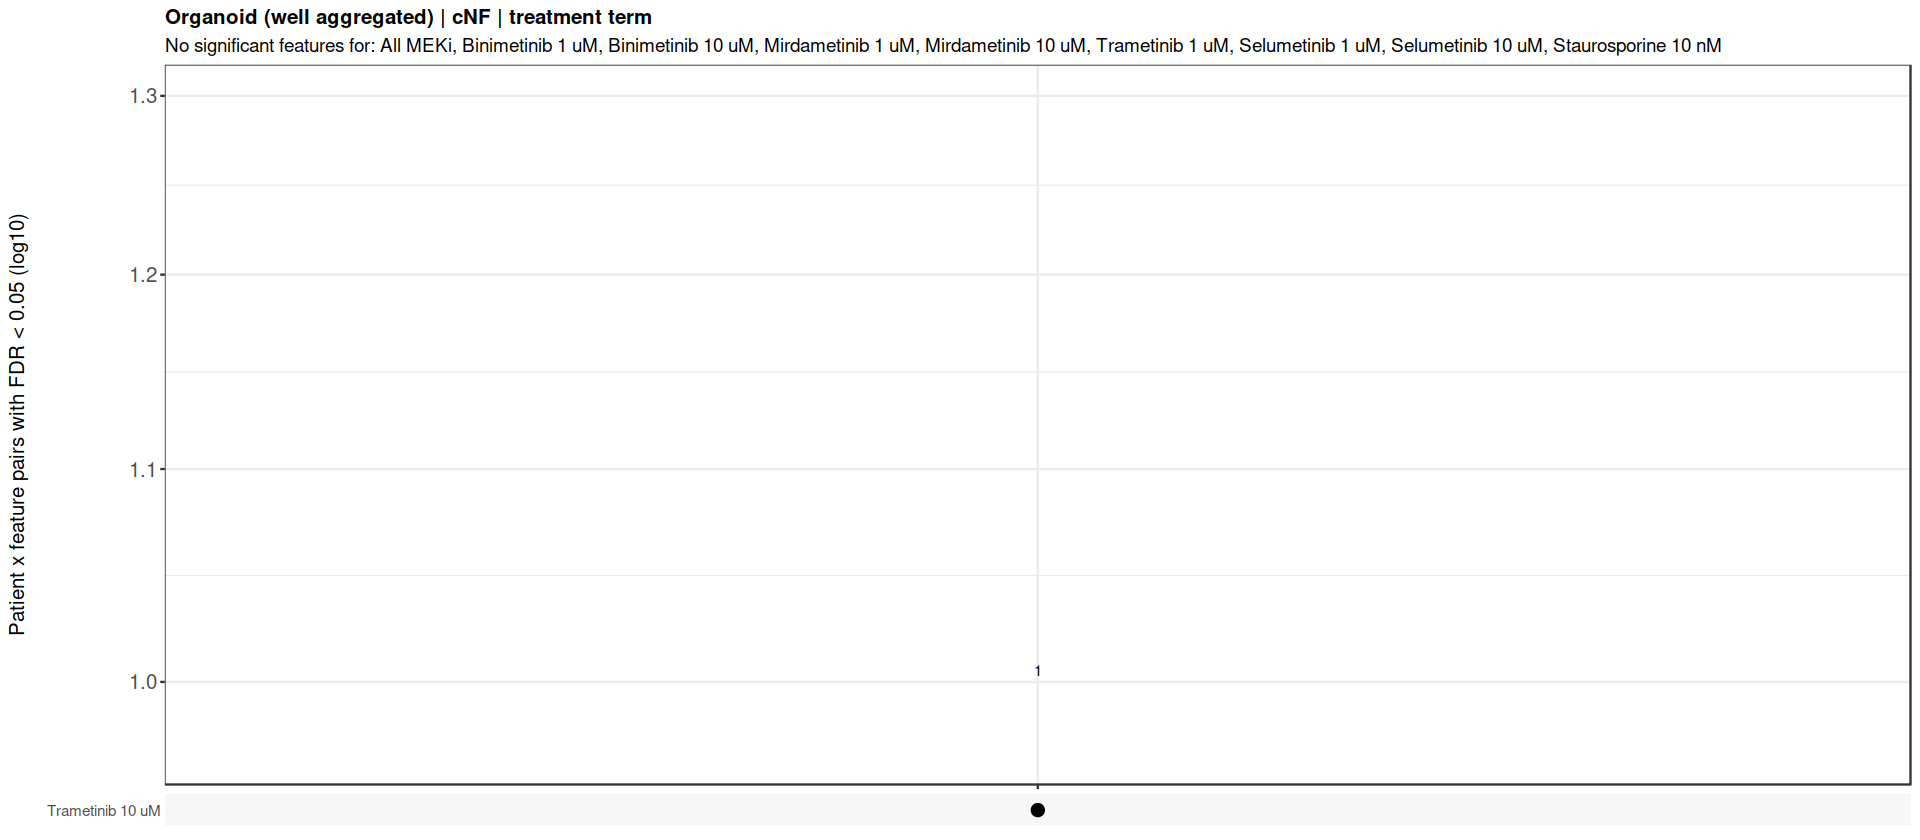

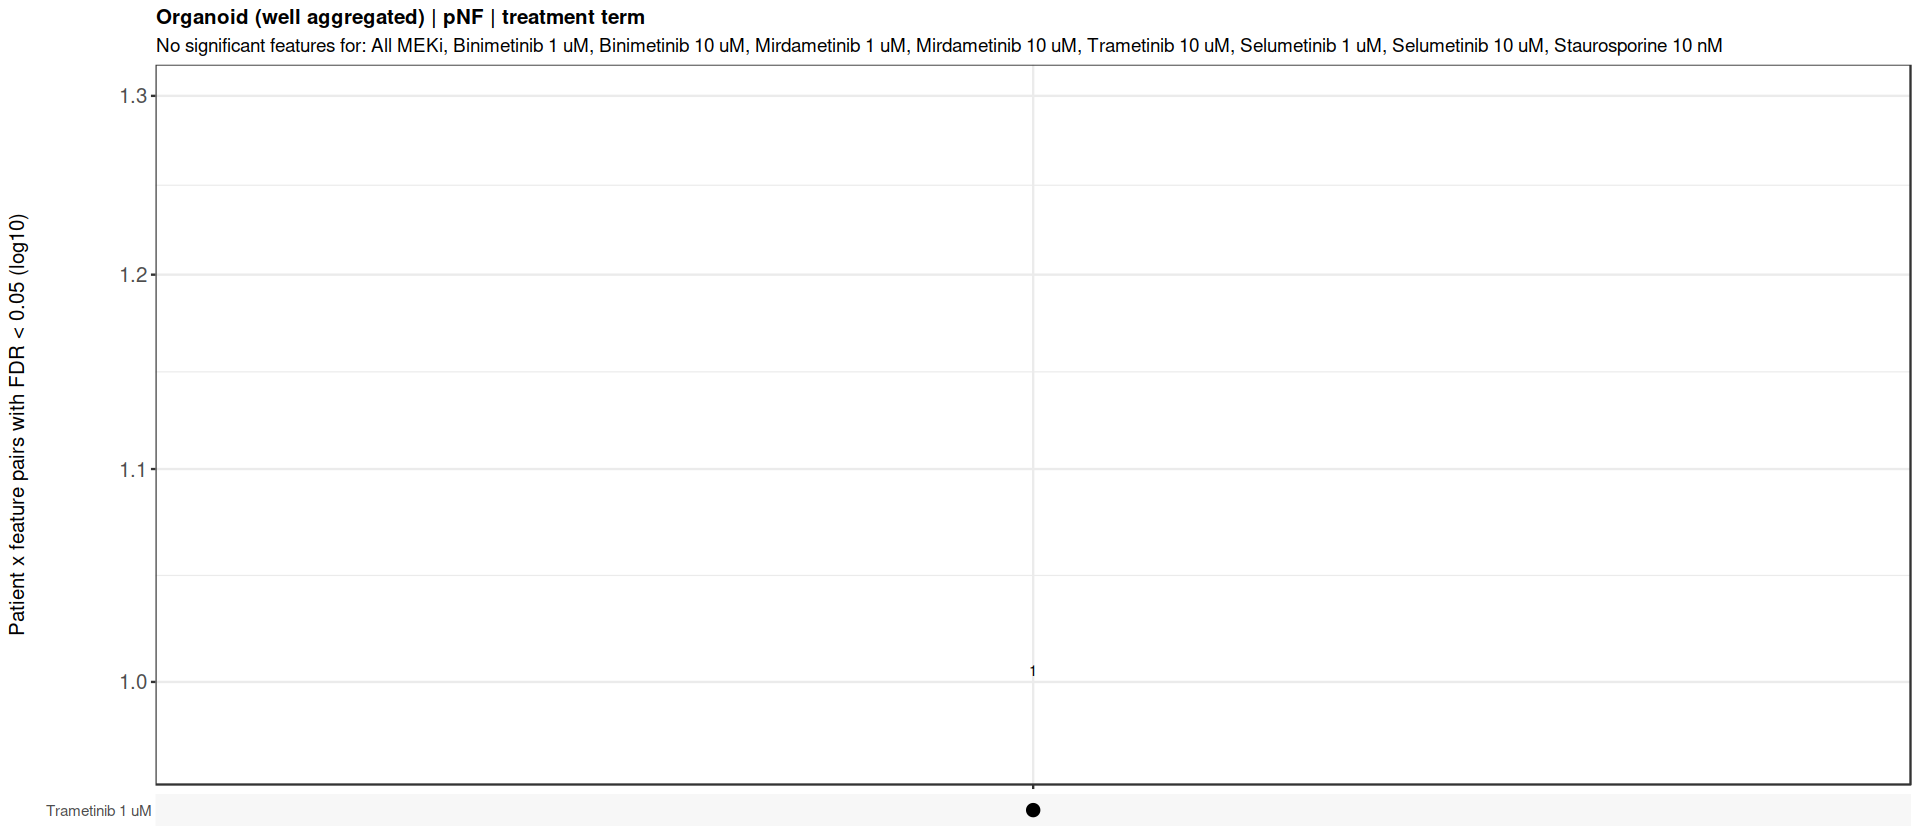

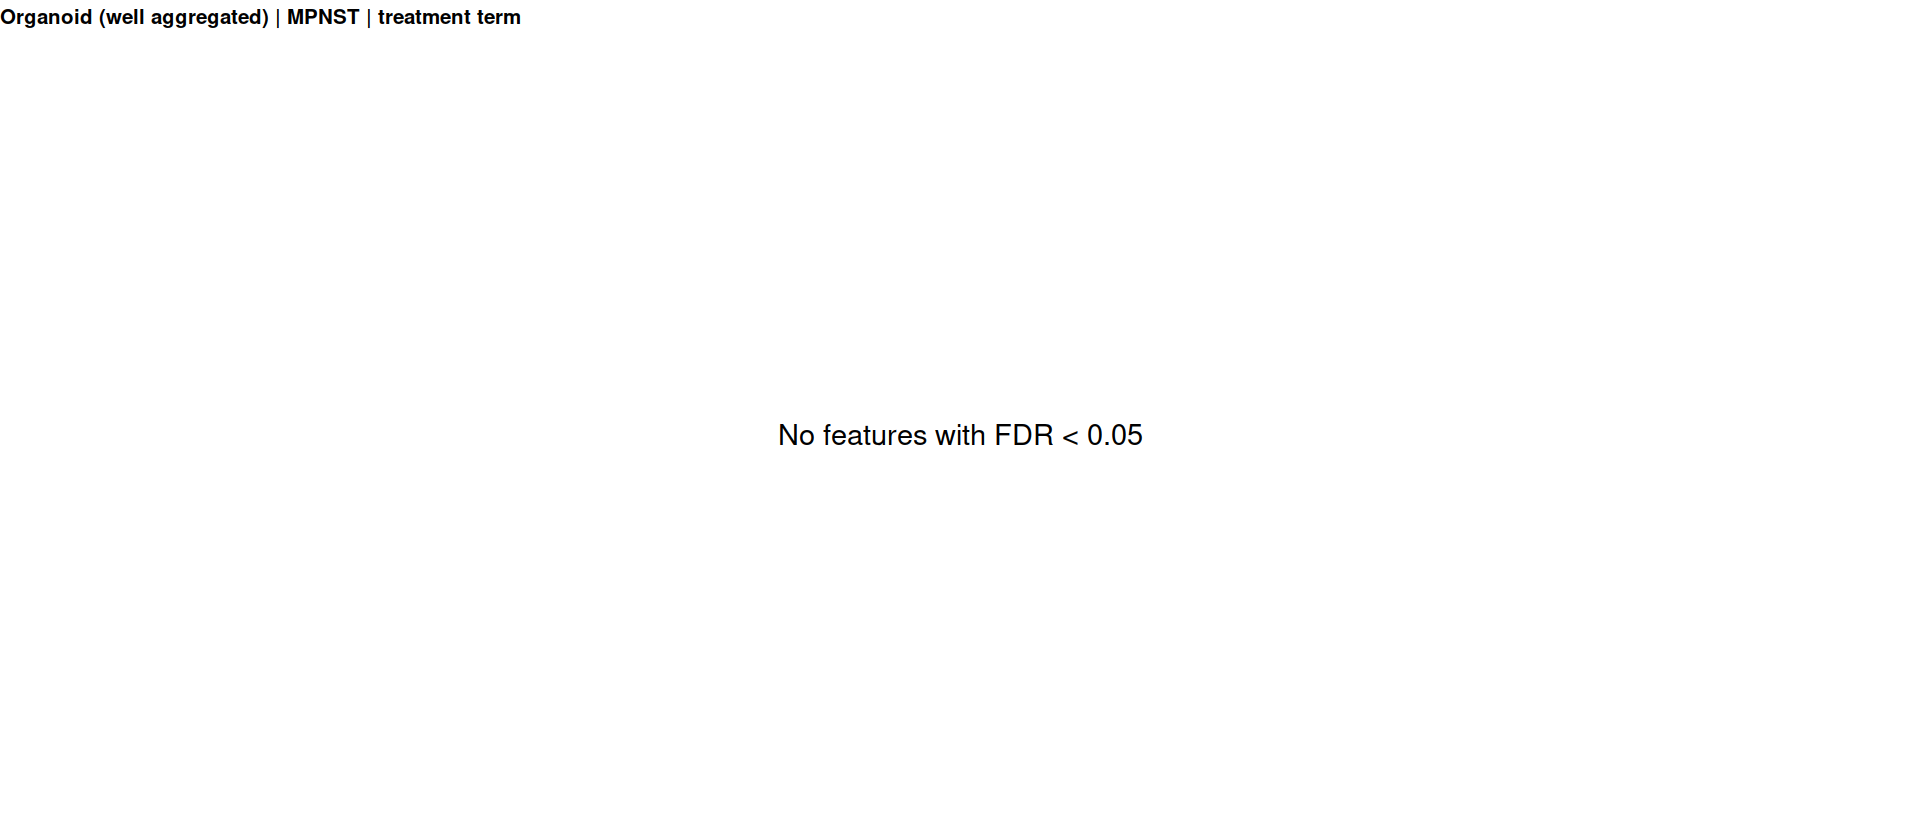

Warning message:
“Removed 18123 rows containing non-finite outside the scale range
(`stat_count()`).”
Warning message:
“Removed 18123 rows containing non-finite outside the scale range
(`stat_count()`).”


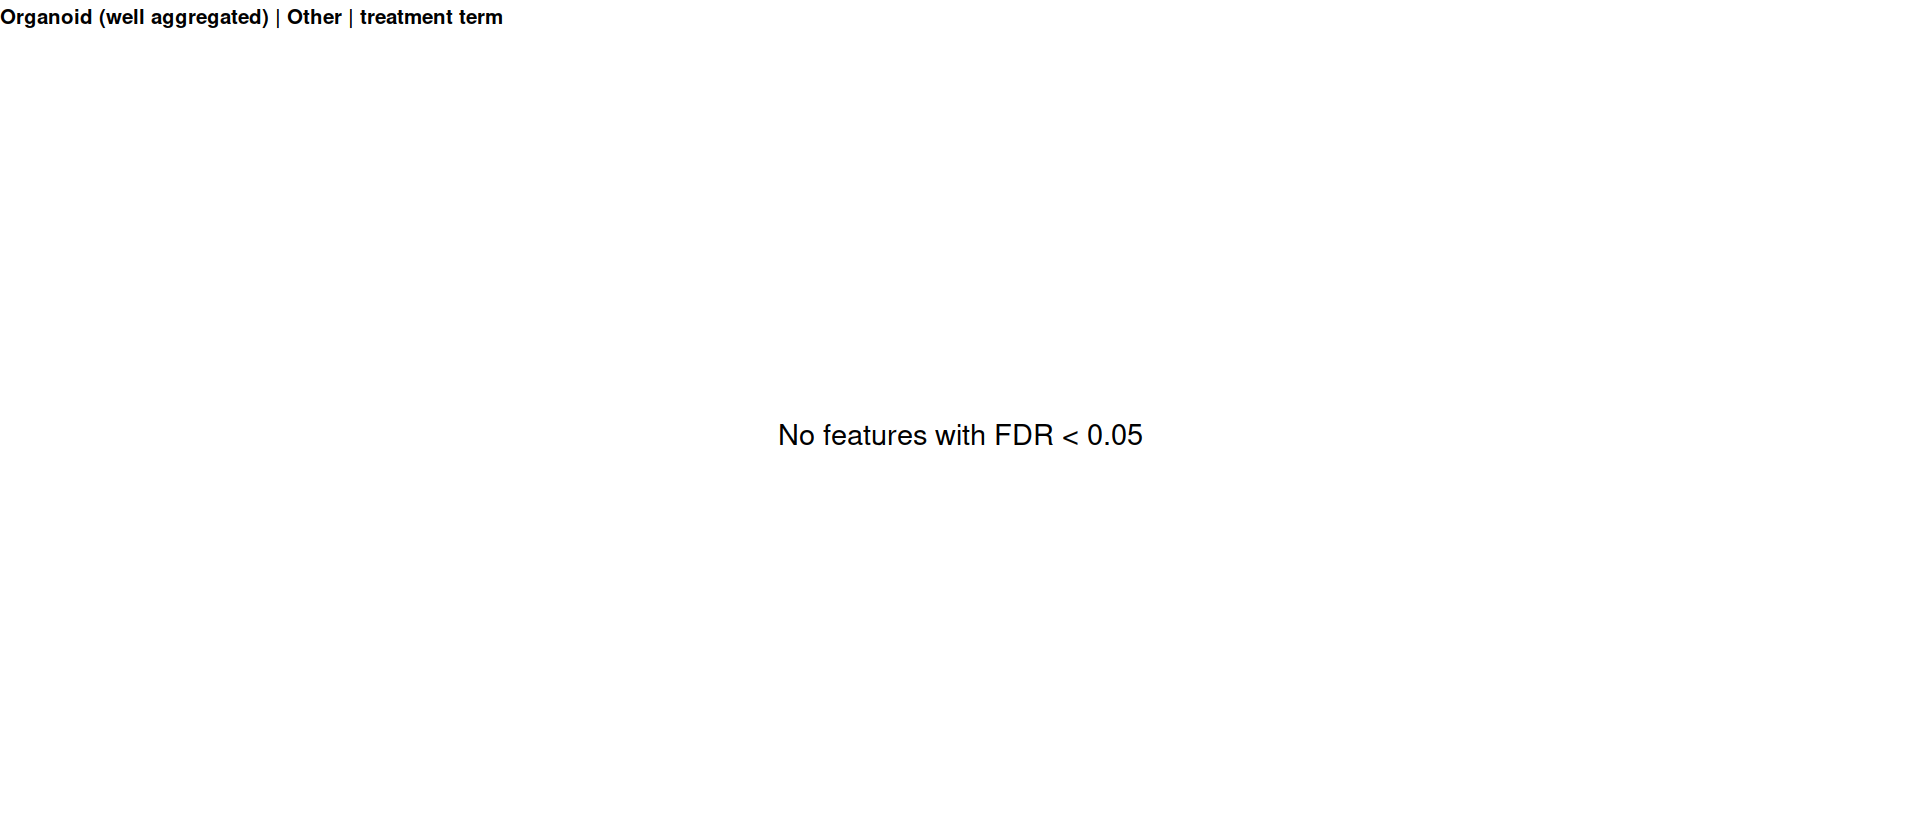

Warning message:
“Removed 7017 rows containing non-finite outside the scale range
(`stat_count()`).”
Warning message:
“Removed 7017 rows containing non-finite outside the scale range
(`stat_count()`).”


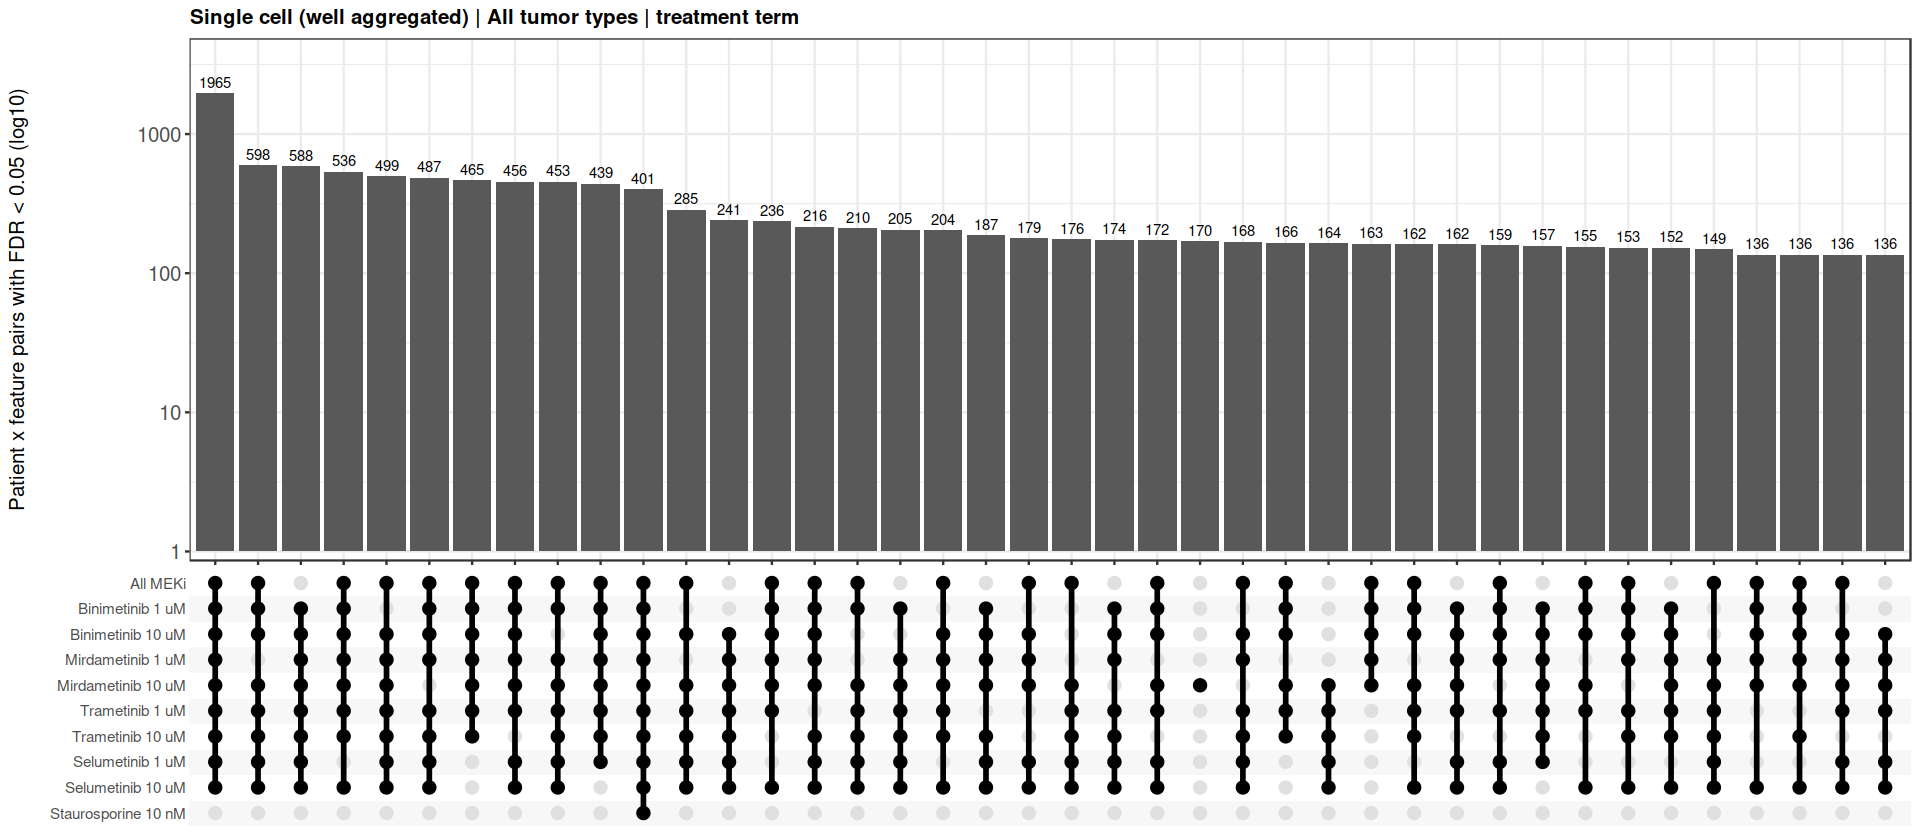

Warning message:
“Removed 4708 rows containing non-finite outside the scale range
(`stat_count()`).”
Warning message:
“Removed 4708 rows containing non-finite outside the scale range
(`stat_count()`).”


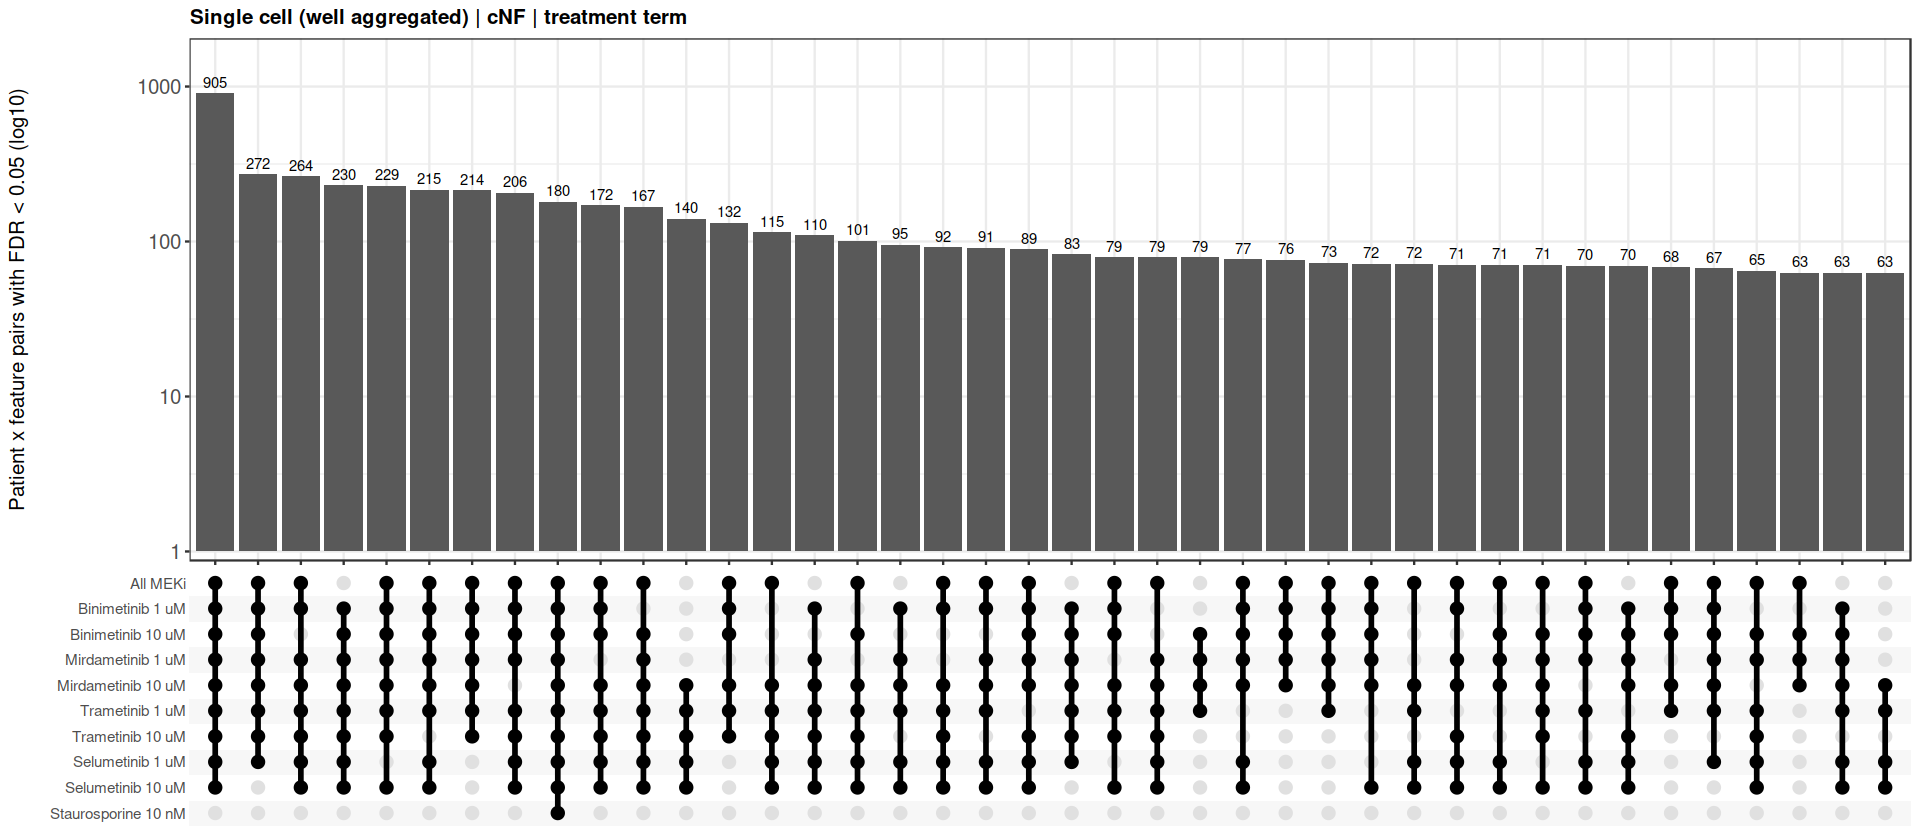

Warning message:
“Removed 2415 rows containing non-finite outside the scale range
(`stat_count()`).”
Warning message:
“Removed 2415 rows containing non-finite outside the scale range
(`stat_count()`).”


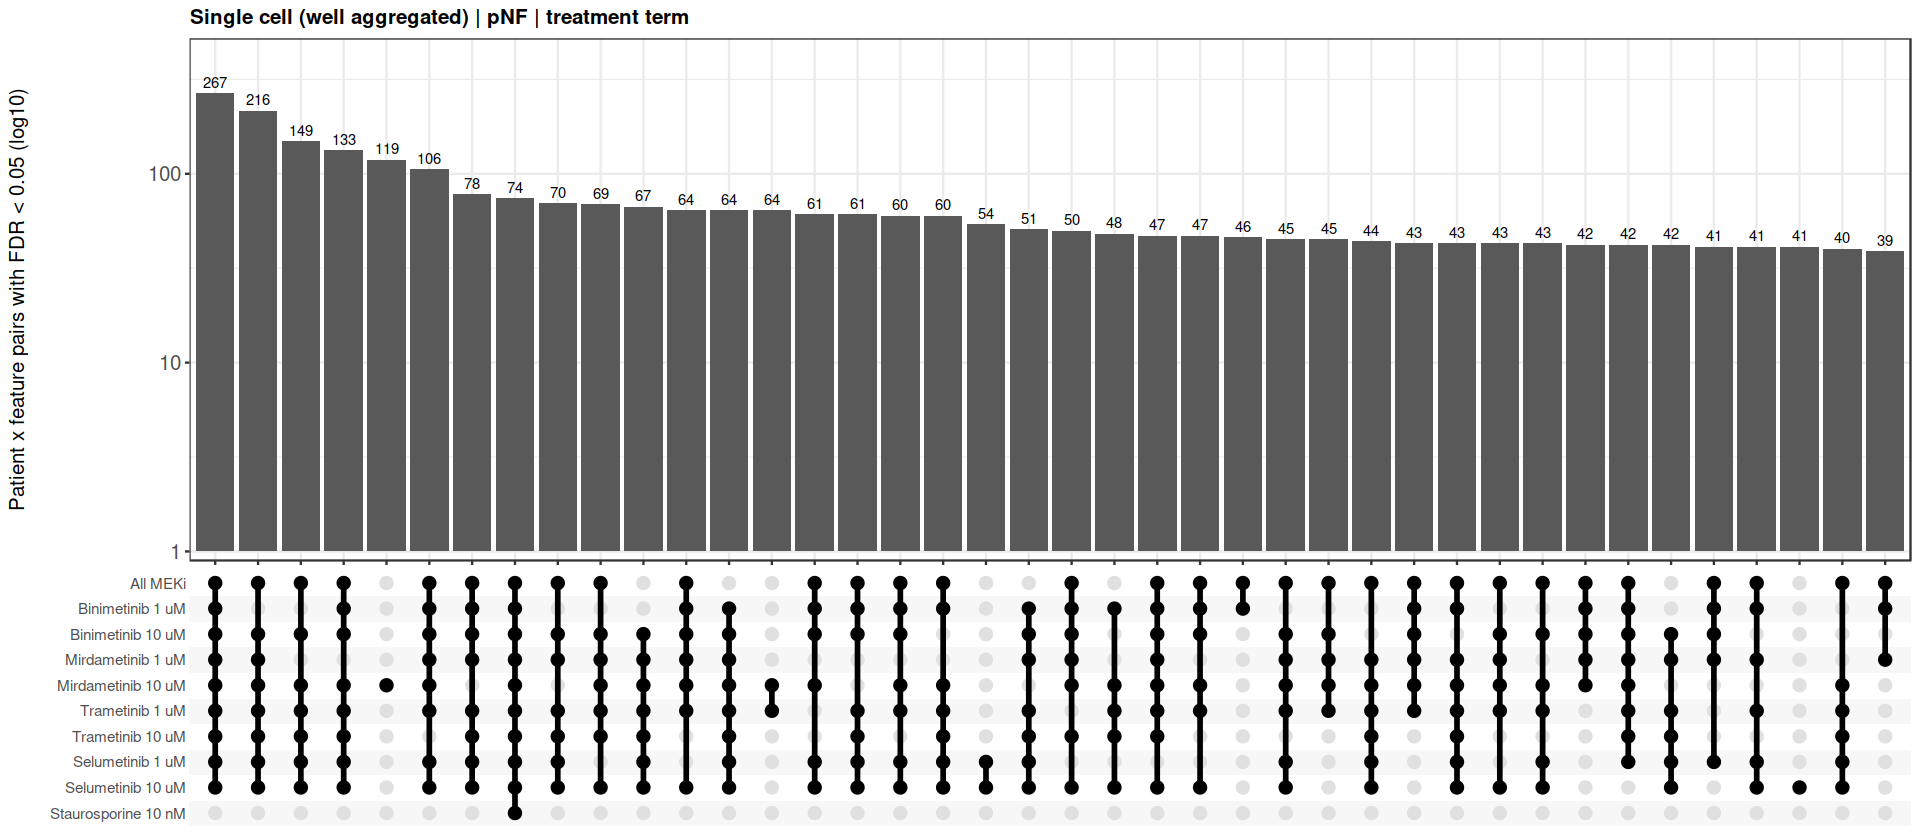

Warning message:
“Removed 2519 rows containing non-finite outside the scale range
(`stat_count()`).”
Warning message:
“Removed 2519 rows containing non-finite outside the scale range
(`stat_count()`).”


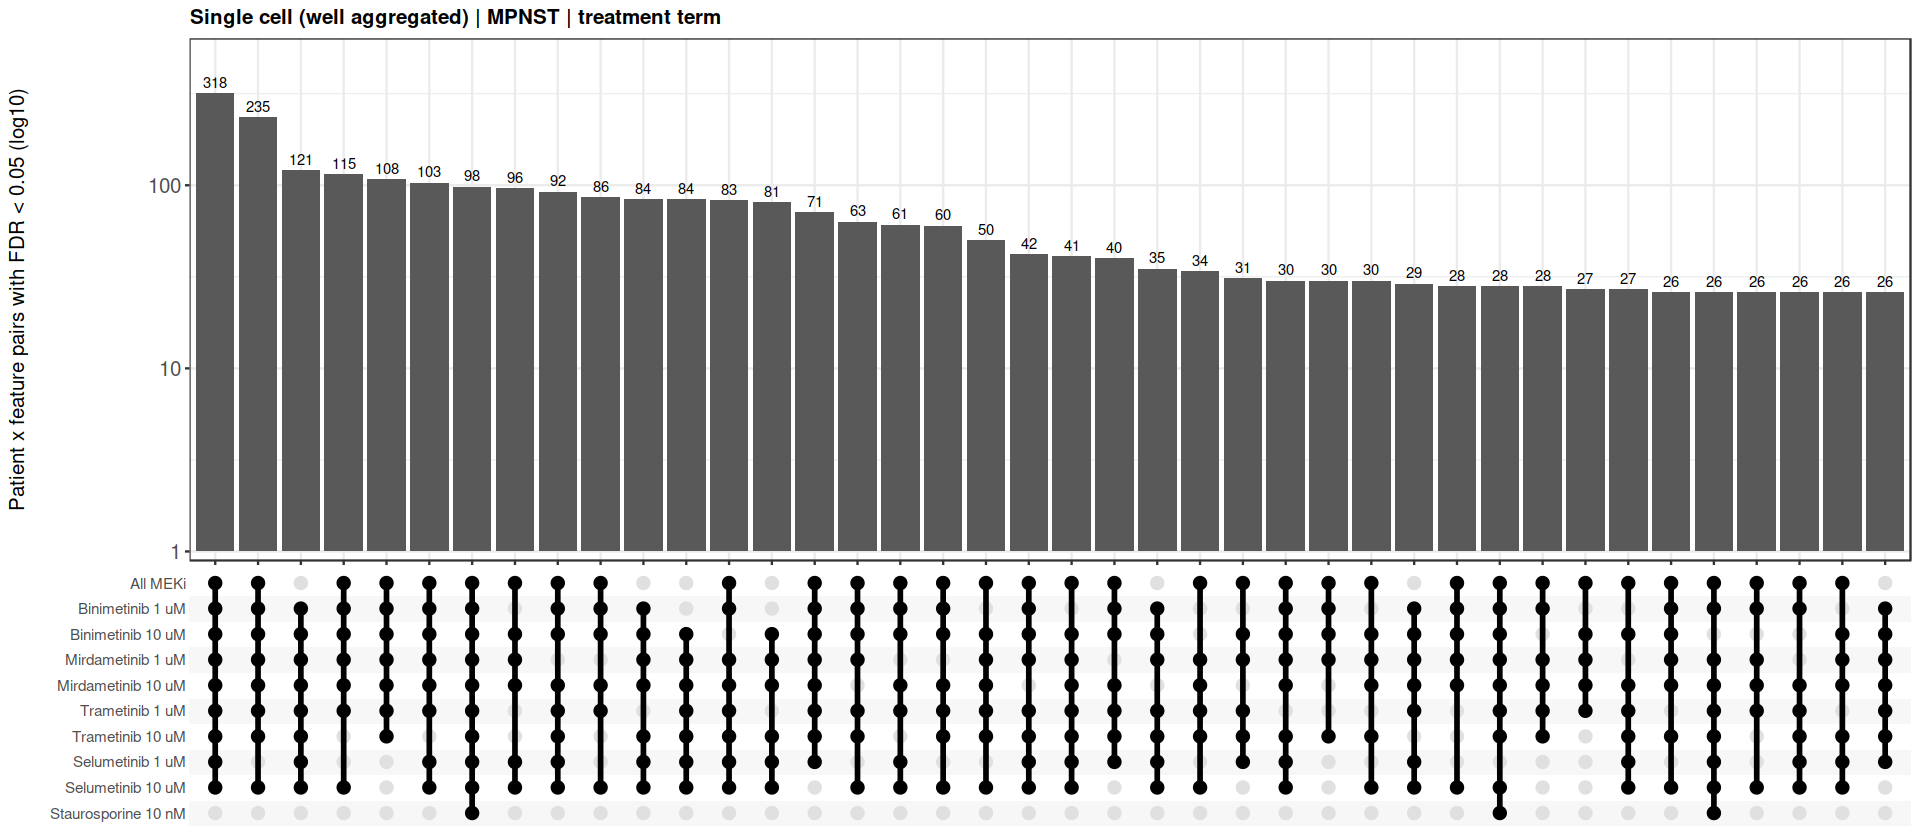

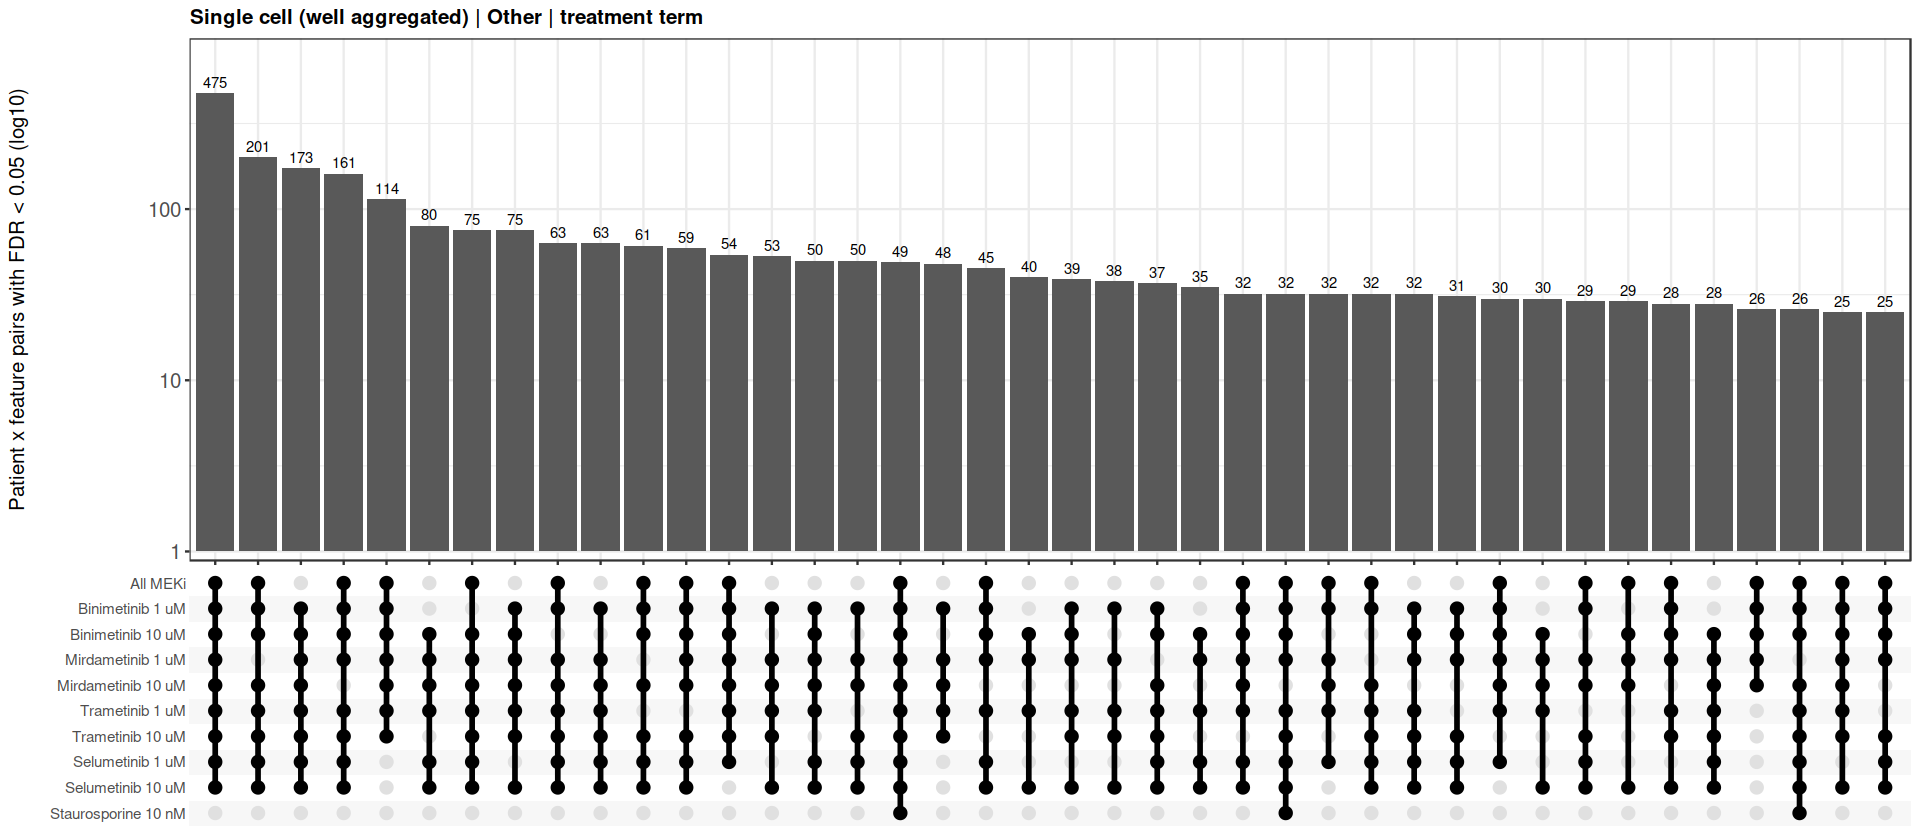

In [10]:
upset_df <- treatment_df %>%
    filter(significant) %>%
    mutate(element = paste(Metadata_Biology_PatientTumor, feature, sep = " | ")) %>%
    group_by(profile, tumor_type, element) %>%
    summarise(mek_groups = list(sort(unique(as.character(mek_group)))), .groups = "drop")

upset_plot <- function(profile_name, tumor_type_name) {
    plot_df <- upset_df %>% filter(profile == profile_name)
    if (tumor_type_name != "All tumor types") {
        plot_df <- plot_df %>% filter(tumor_type == tumor_type_name)
    }
    title <- paste0(profile_name, " | ", tumor_type_name, " | treatment term")
    if (nrow(plot_df) == 0) {
        return(
            ggplot()
            + annotate("text", x = 0, y = 0, label = paste0("No features with FDR < ", FDR_MAX), size = 6)
            + labs(title = title)
            + theme_manuscript_void(base_size = 12)
        )
    }
    missing_sets <- setdiff(mek_group_levels, unlist(plot_df$mek_groups))
    subtitle <- if (length(missing_sets) > 0) {
        paste0("No significant features for: ", paste(missing_sets, collapse = ", "))
    } else {
        NULL
    }
    (
        ggplot(plot_df, aes(x = mek_groups))
        + geom_bar()
        + scale_y_log10(expand = expansion(mult = c(0.02, 0.12)))
        + geom_text(stat = "count", aes(label = after_stat(count)), vjust = -0.5, size = 3)
        + scale_x_upset(sets = mek_group_levels, n_intersections = 40)
        + labs(
            title = title,
            subtitle = subtitle,
            x = NULL,
            y = paste0("Patient x feature pairs with FDR < ", FDR_MAX, " (log10)")
        )
        + theme_manuscript(base_size = 12)
    )
}

upset_pages <- expand.grid(
    tumor_type = c("All tumor types", tumor_type_levels),
    profile = levels(lm_df$profile),
    stringsAsFactors = FALSE
)
upset_plots <- mapply(upset_plot, upset_pages$profile, upset_pages$tumor_type, SIMPLIFY = FALSE)
options(repr.plot.width = 16, repr.plot.height = 7)
save_plots_pdf(upset_plots, upset_path, width = 16, height = 7)
for (upset_page in upset_plots) print(upset_page)

## Feature categories of the significant treatment features
One page per profile: the feature types of the features significant for treatment in each patient, split by the direction of the treatment coefficient.

Warning message in min(x):
“no non-missing arguments to min; returning Inf”
Warning message in max(x):
“no non-missing arguments to max; returning -Inf”
Warning message in min(x):
“no non-missing arguments to min; returning Inf”
Warning message in max(x):
“no non-missing arguments to max; returning -Inf”
Warning message in min(x):
“no non-missing arguments to min; returning Inf”
Warning message in max(x):
“no non-missing arguments to max; returning -Inf”
Warning message in min(x):
“no non-missing arguments to min; returning Inf”
Warning message in max(x):
“no non-missing arguments to max; returning -Inf”
Warning message in min(x):
“no non-missing arguments to min; returning Inf”
Warning message in max(x):
“no non-missing arguments to max; returning -Inf”
Warning message in min(x):
“no non-missing arguments to min; returning Inf”
Warning message in max(x):
“no non-missing arguments to max; returning -Inf”
Warning message in min(x):
“no non-missing arguments to min; returning Inf”
Warnin

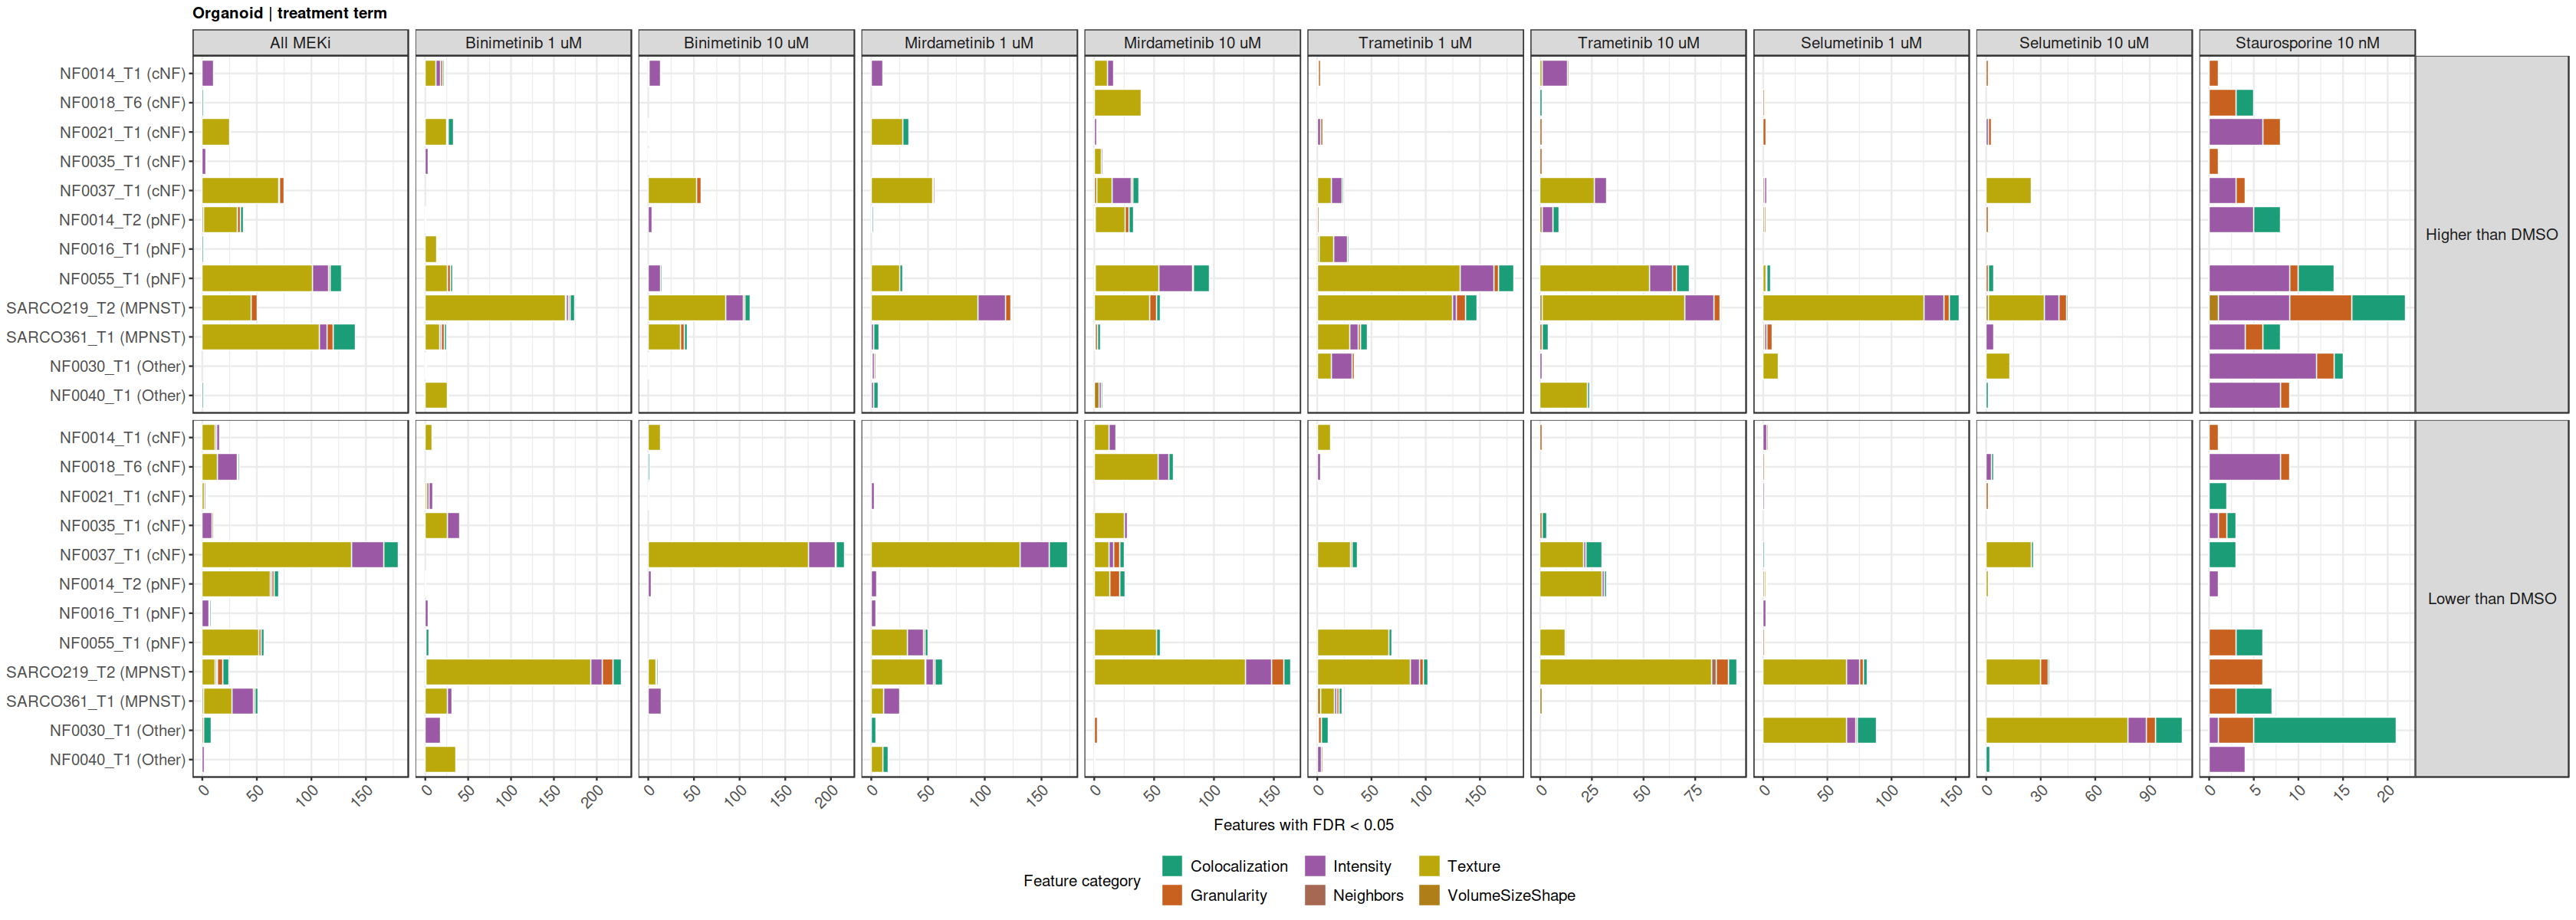

Warning message in min(x):
“no non-missing arguments to min; returning Inf”
Warning message in max(x):
“no non-missing arguments to max; returning -Inf”
Warning message in min(x):
“no non-missing arguments to min; returning Inf”
Warning message in max(x):
“no non-missing arguments to max; returning -Inf”
Warning message in min(x):
“no non-missing arguments to min; returning Inf”
Warning message in max(x):
“no non-missing arguments to max; returning -Inf”
Warning message in min(x):
“no non-missing arguments to min; returning Inf”
Warning message in max(x):
“no non-missing arguments to max; returning -Inf”
Warning message in min(x):
“no non-missing arguments to min; returning Inf”
Warning message in max(x):
“no non-missing arguments to max; returning -Inf”
Warning message in min(x):
“no non-missing arguments to min; returning Inf”
Warning message in max(x):
“no non-missing arguments to max; returning -Inf”
Warning message in min(x):
“no non-missing arguments to min; returning Inf”
Warnin

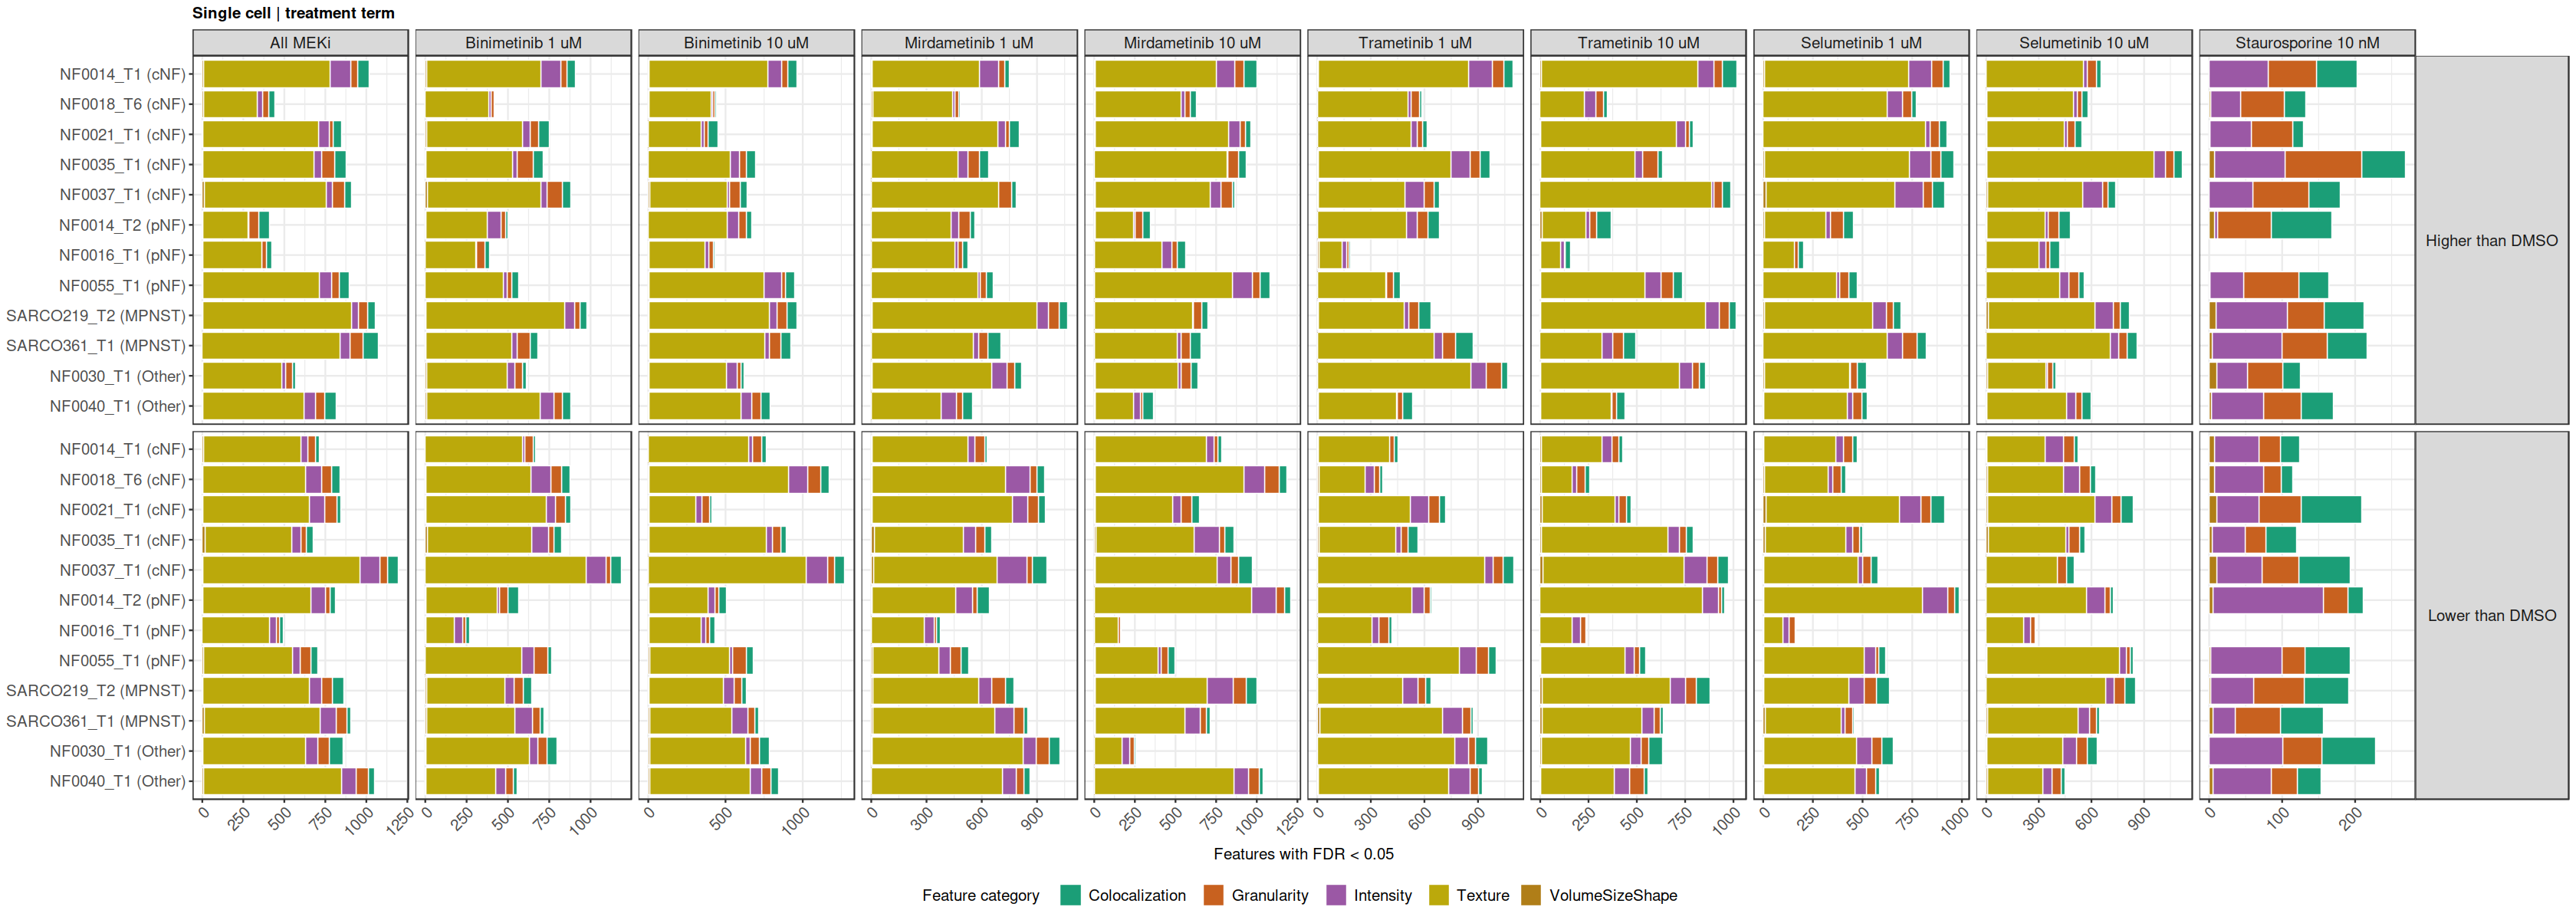

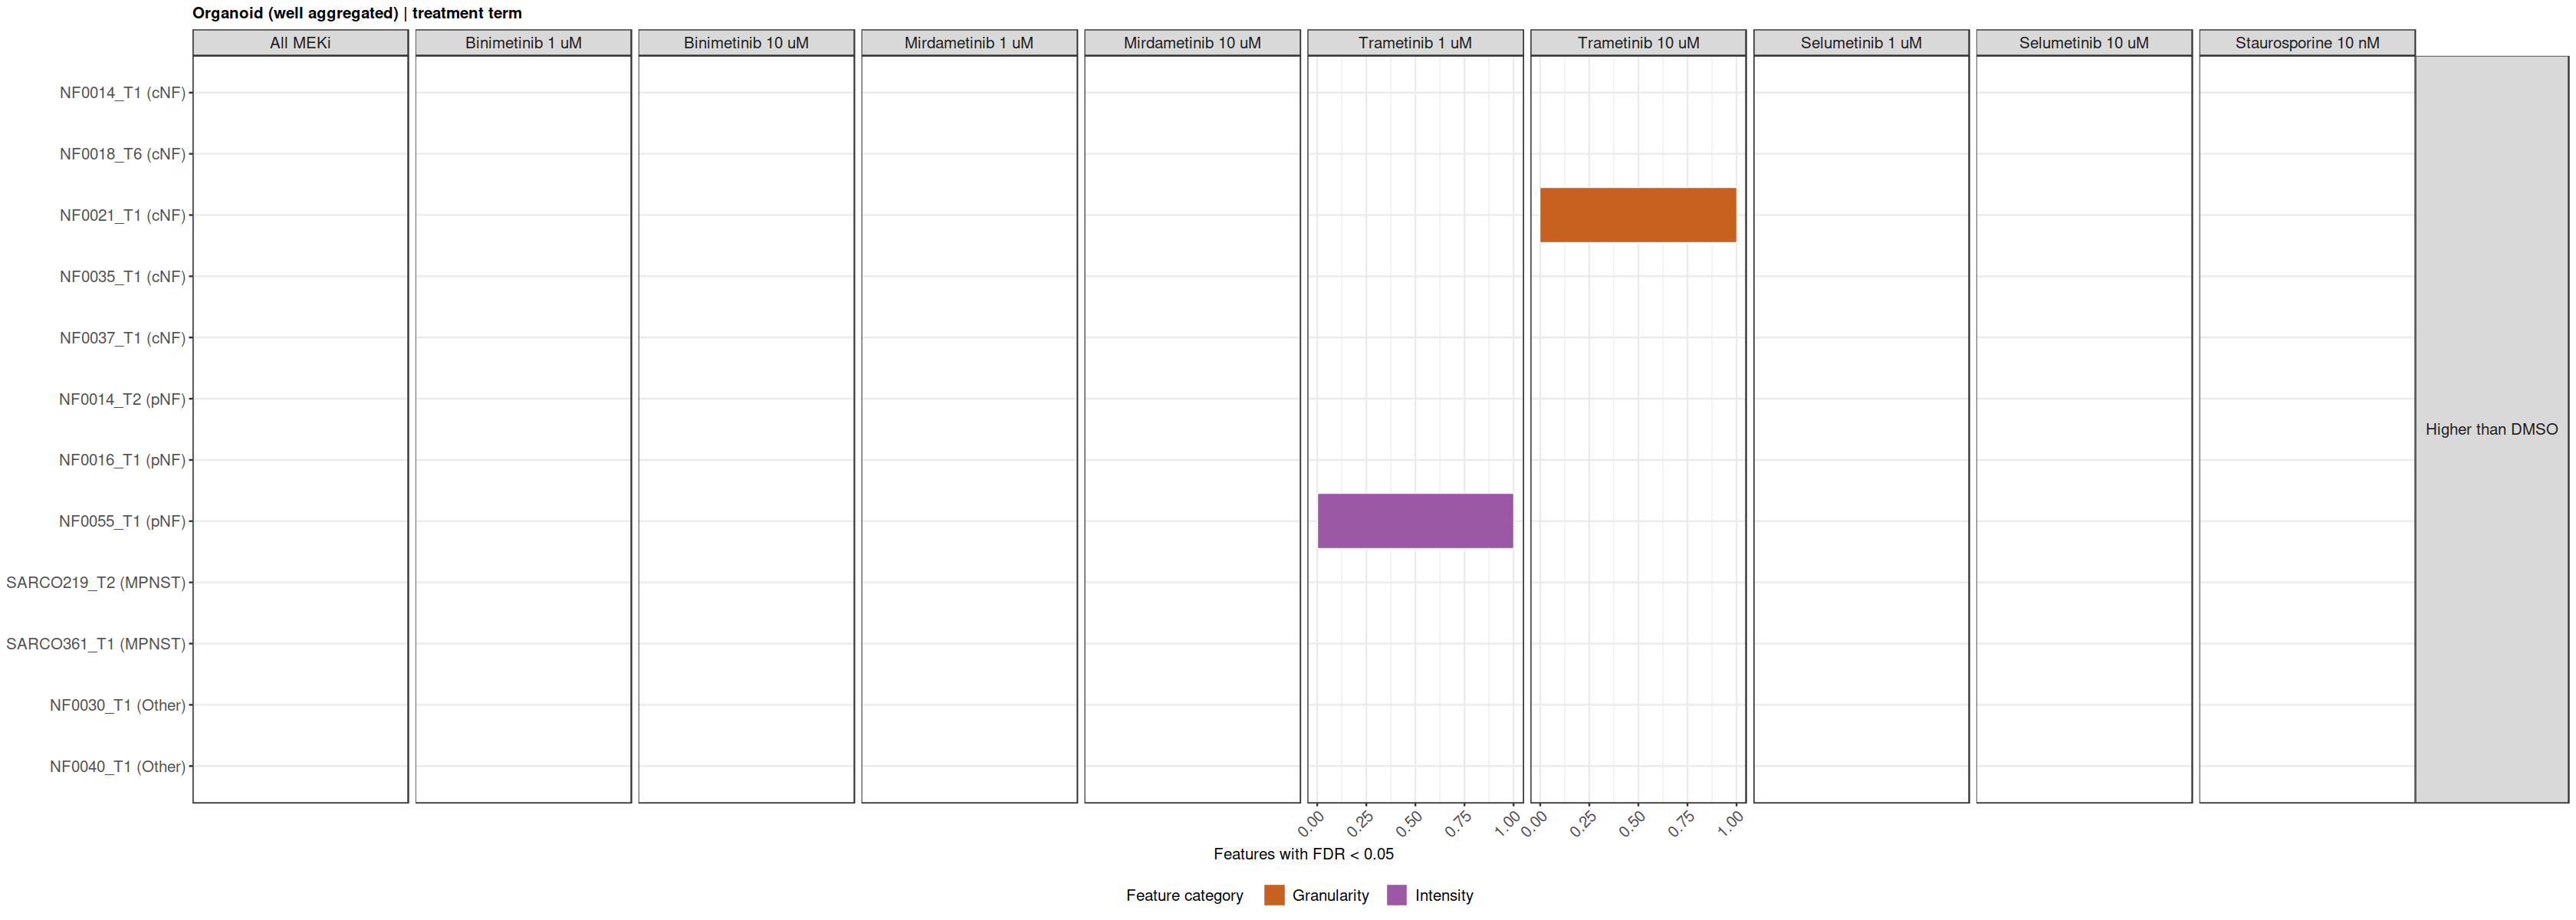

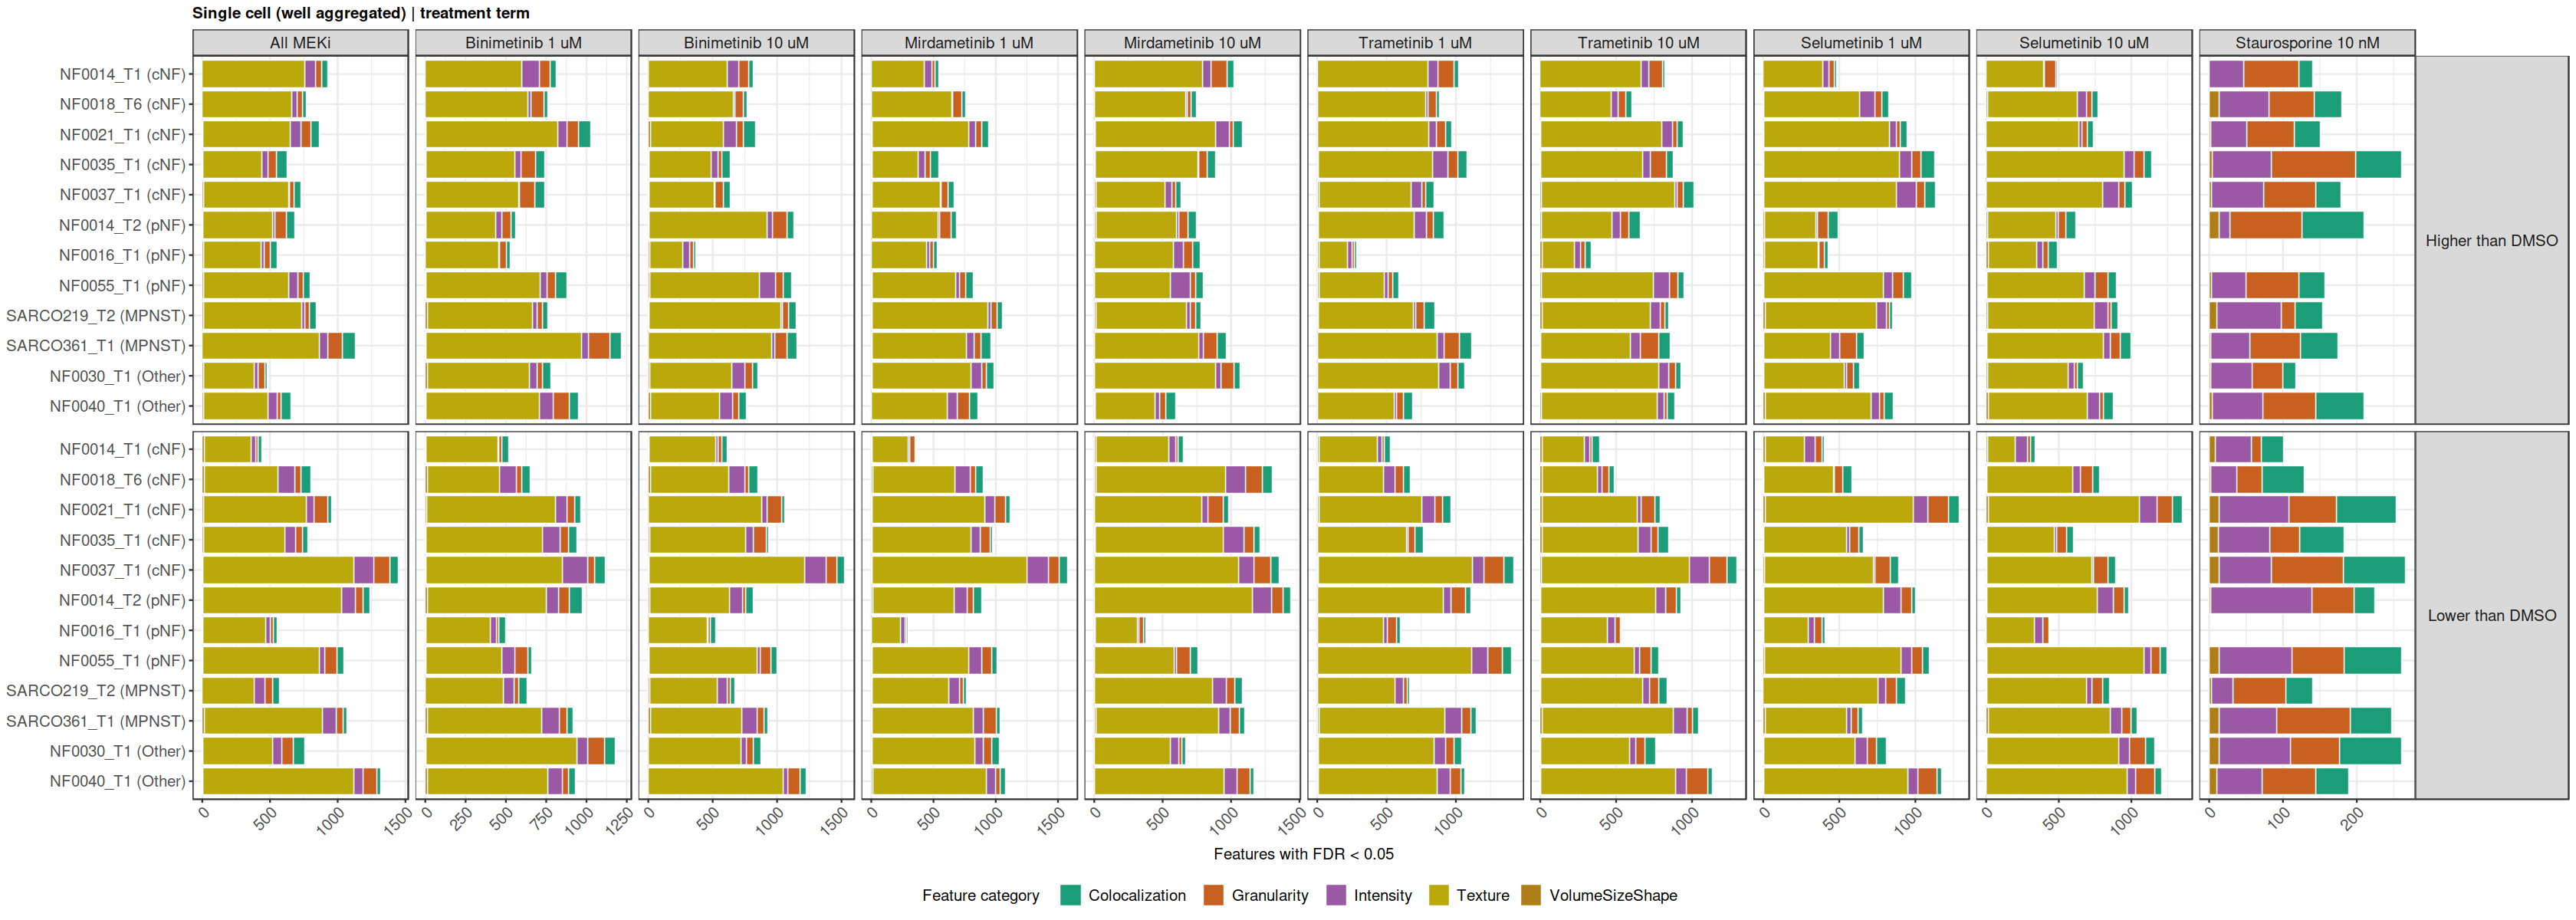

In [11]:
category_df <- treatment_df %>%
    filter(significant) %>%
    count(profile, mek_group, patient_label, feature_category, direction)

category_plot <- function(profile_name) {
    plot_df <- category_df %>% filter(profile == profile_name)
    title <- paste0(profile_name, " | treatment term")
    if (nrow(plot_df) == 0) {
        return(
            ggplot()
            + annotate("text", x = 0, y = 0, label = paste0("No features with FDR < ", FDR_MAX), size = 6)
            + labs(title = title)
            + theme_manuscript_void(base_size = 12)
        )
    }
    (
        ggplot(plot_df, aes(x = n, y = patient_label, fill = feature_category))
        + geom_col(color = "white", linewidth = 0.3)
        + scale_y_discrete(limits = rev, drop = FALSE)
        + scale_fill_manual(values = category_palette)
        + facet_grid(direction ~ mek_group, scales = "free_x", drop = FALSE)
        + labs(title = title, x = paste0("Features with FDR < ", FDR_MAX), y = NULL, fill = "Feature category")
        + theme_manuscript(base_size = 12, x_text = "angled")
        + theme(strip.text.y = element_text(angle = 0), legend.position = "bottom")
    )
}

category_plots <- lapply(levels(lm_df$profile), category_plot)
options(repr.plot.width = 28, repr.plot.height = 10)
save_plots_pdf(category_plots, category_path, width = 28, height = 10)
for (category_plot_page in category_plots) print(category_plot_page)

## Recurrence of significant treatment features across patients
For each MEKi group, a feature's x value is the number of patients in which it is significant for treatment (features significant in no patient are excluded).
Color shows whether the pooled `All MEKi` model also finds the feature in at least one patient, so the individual groups can be compared with the pooled one.

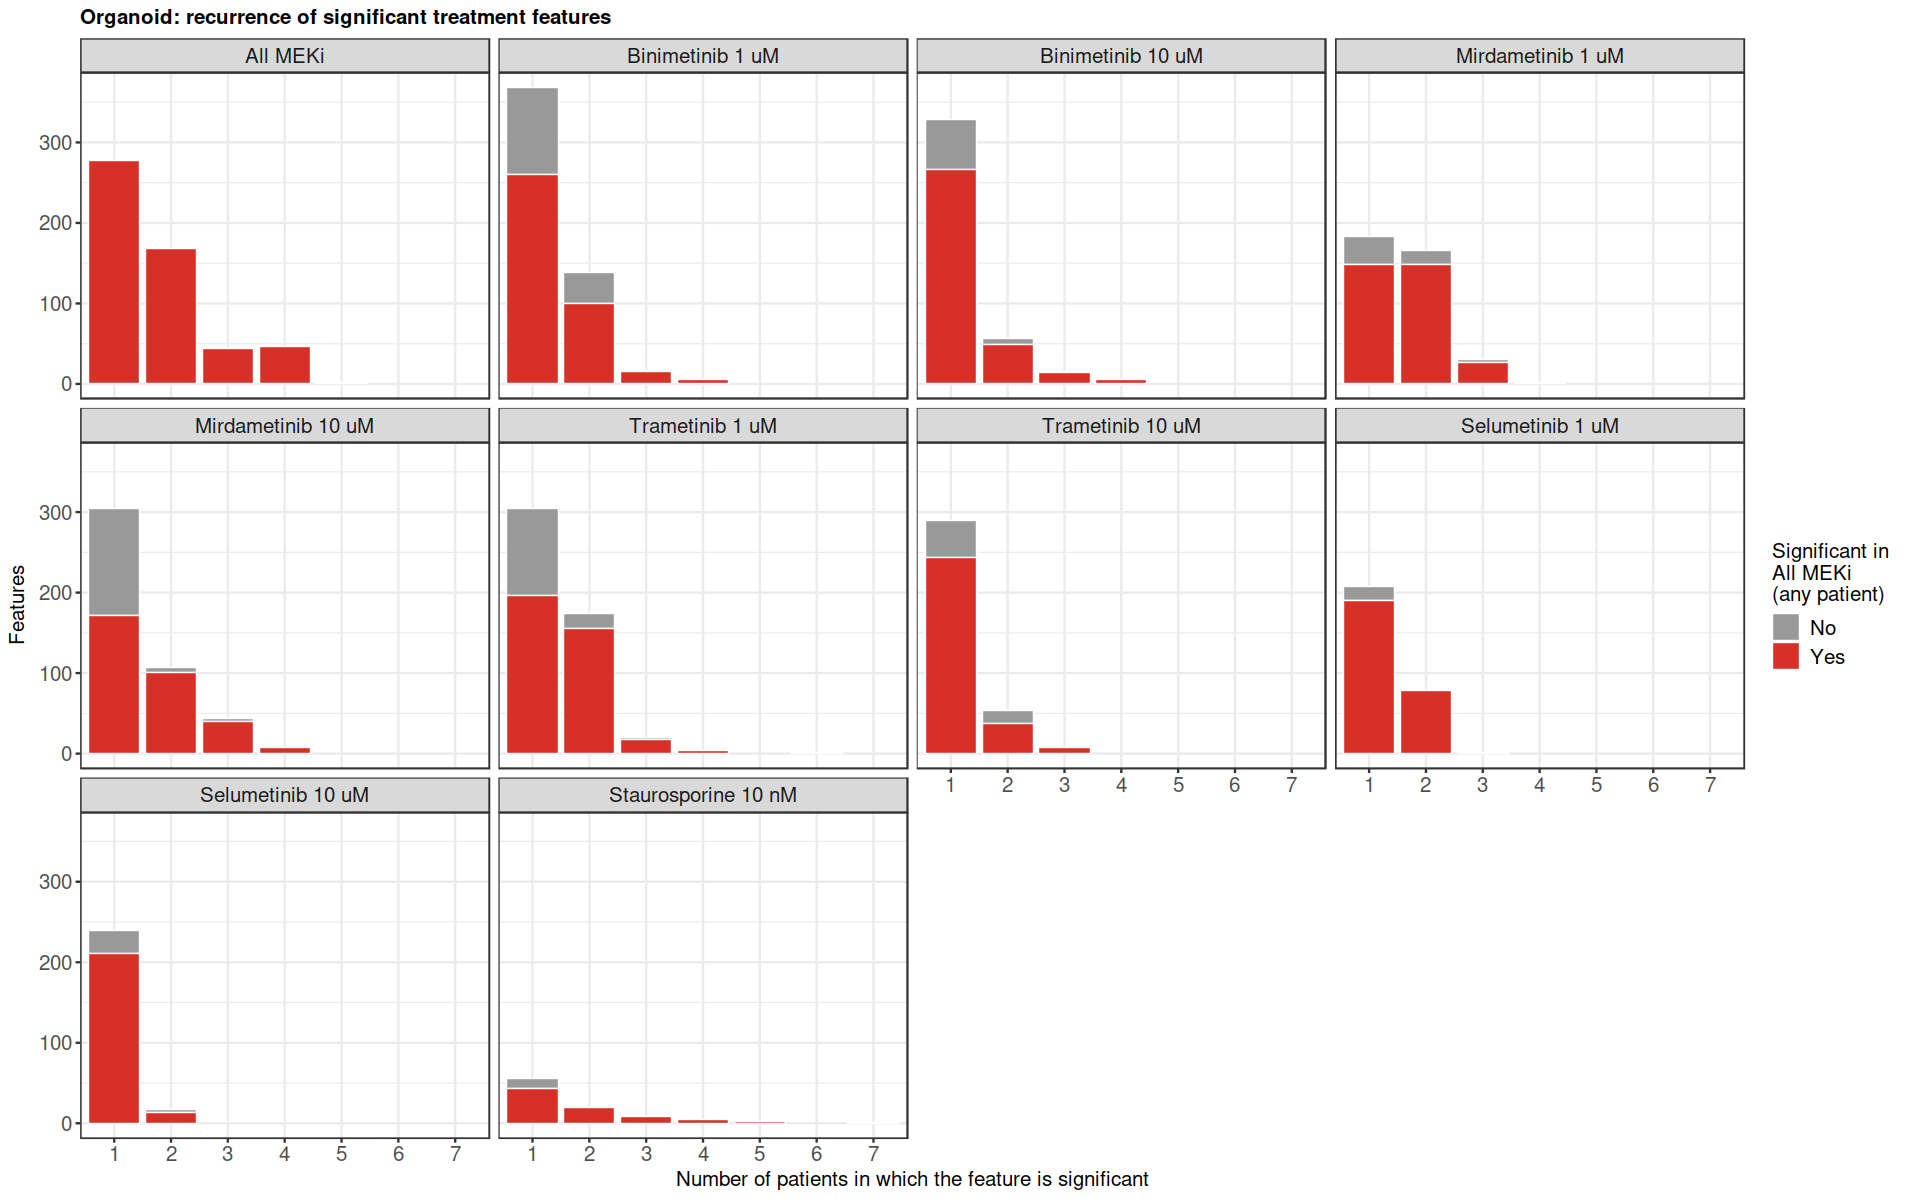

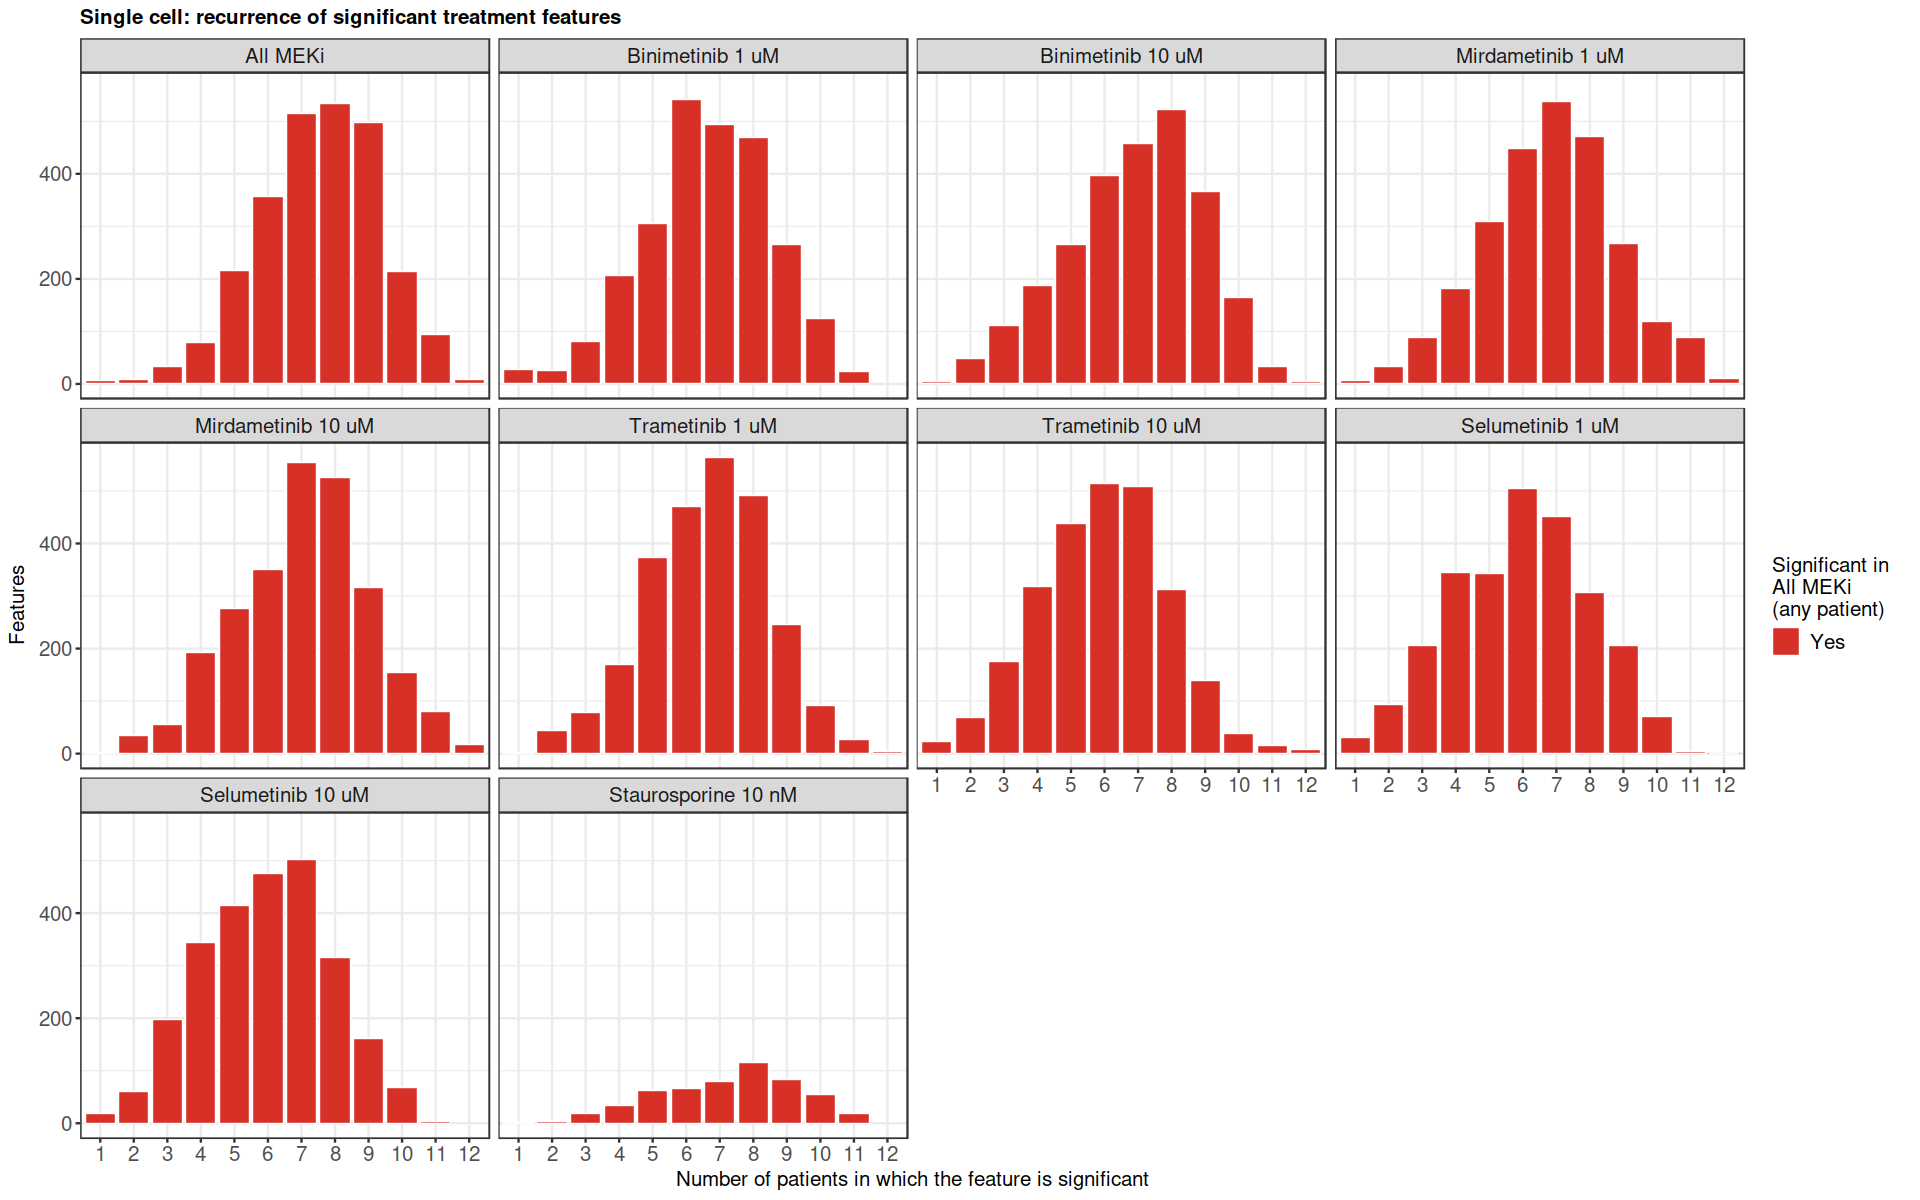

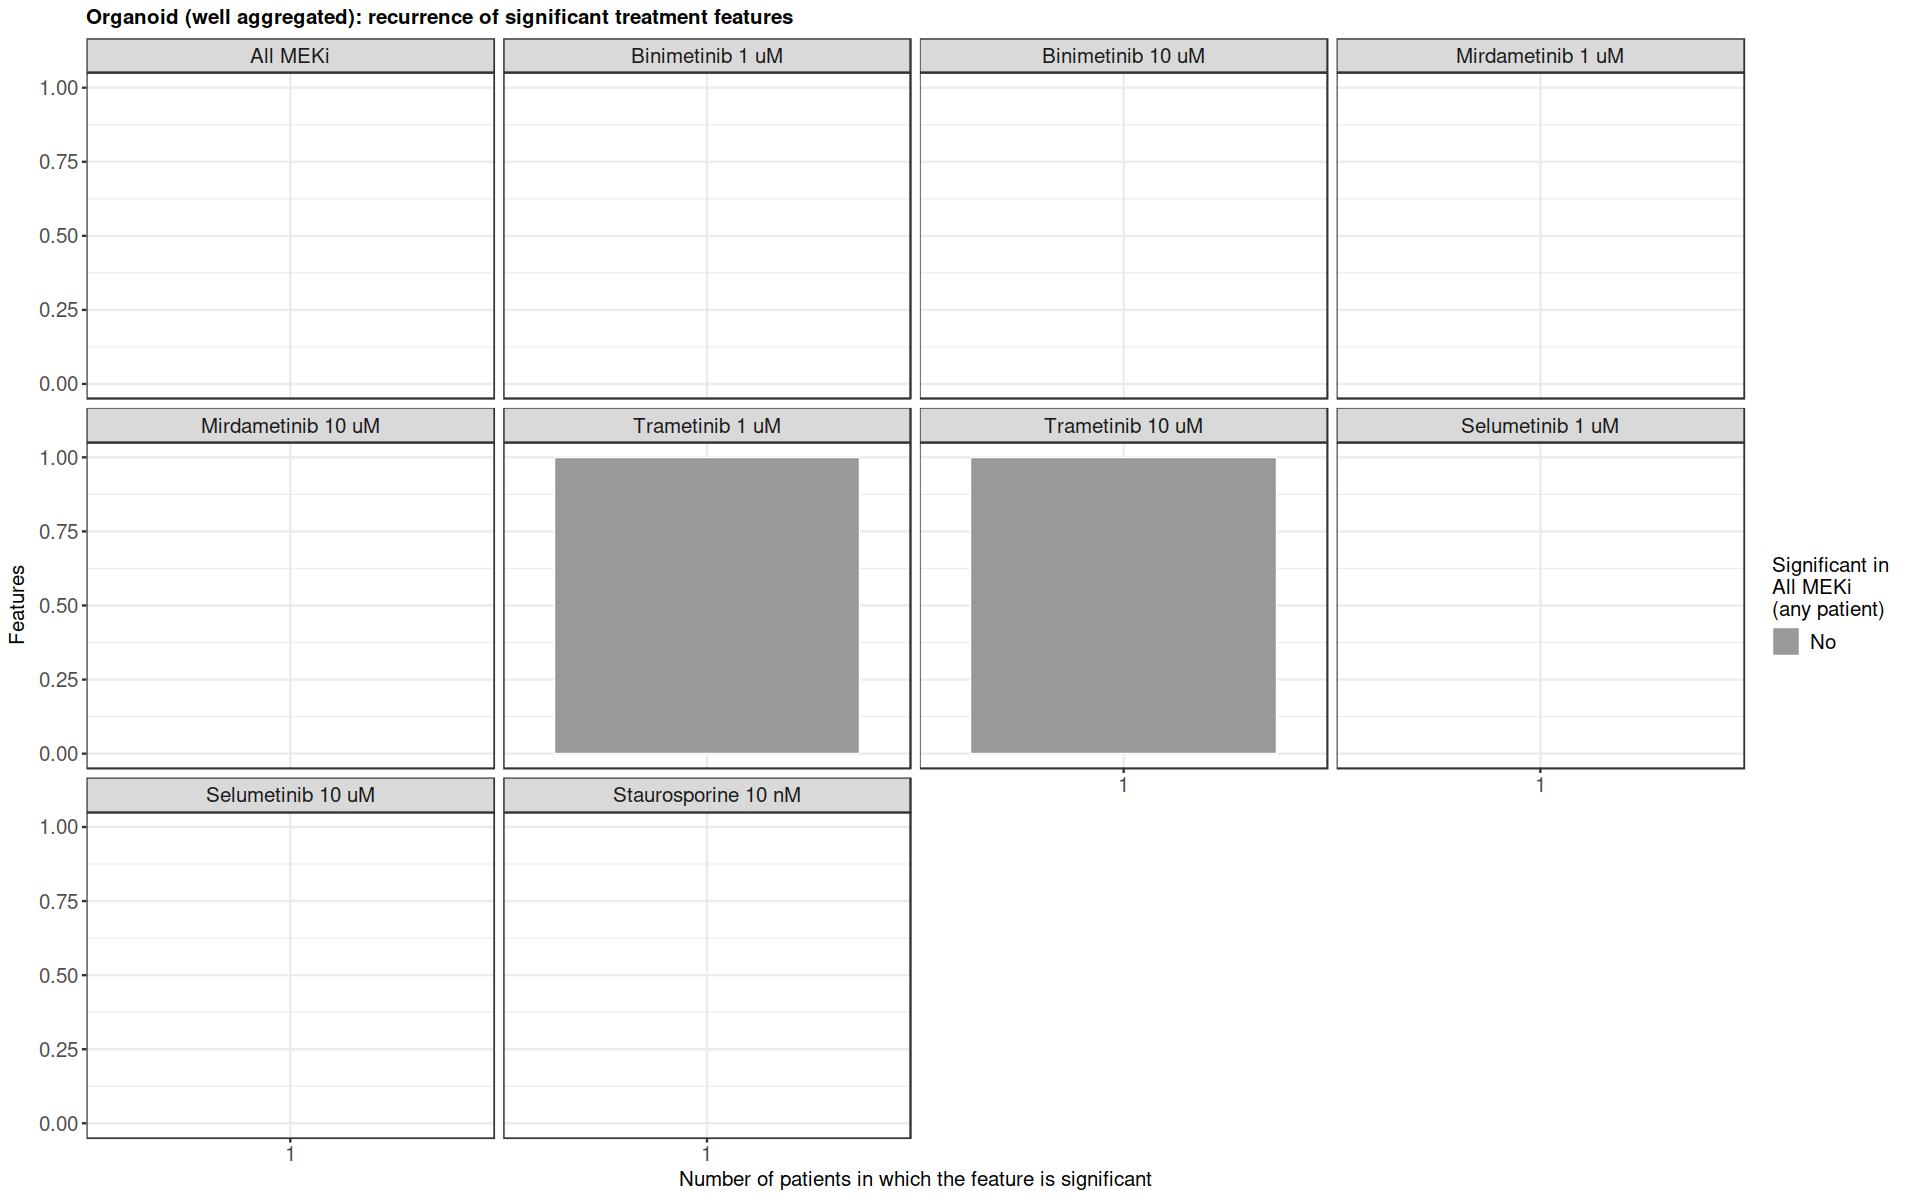

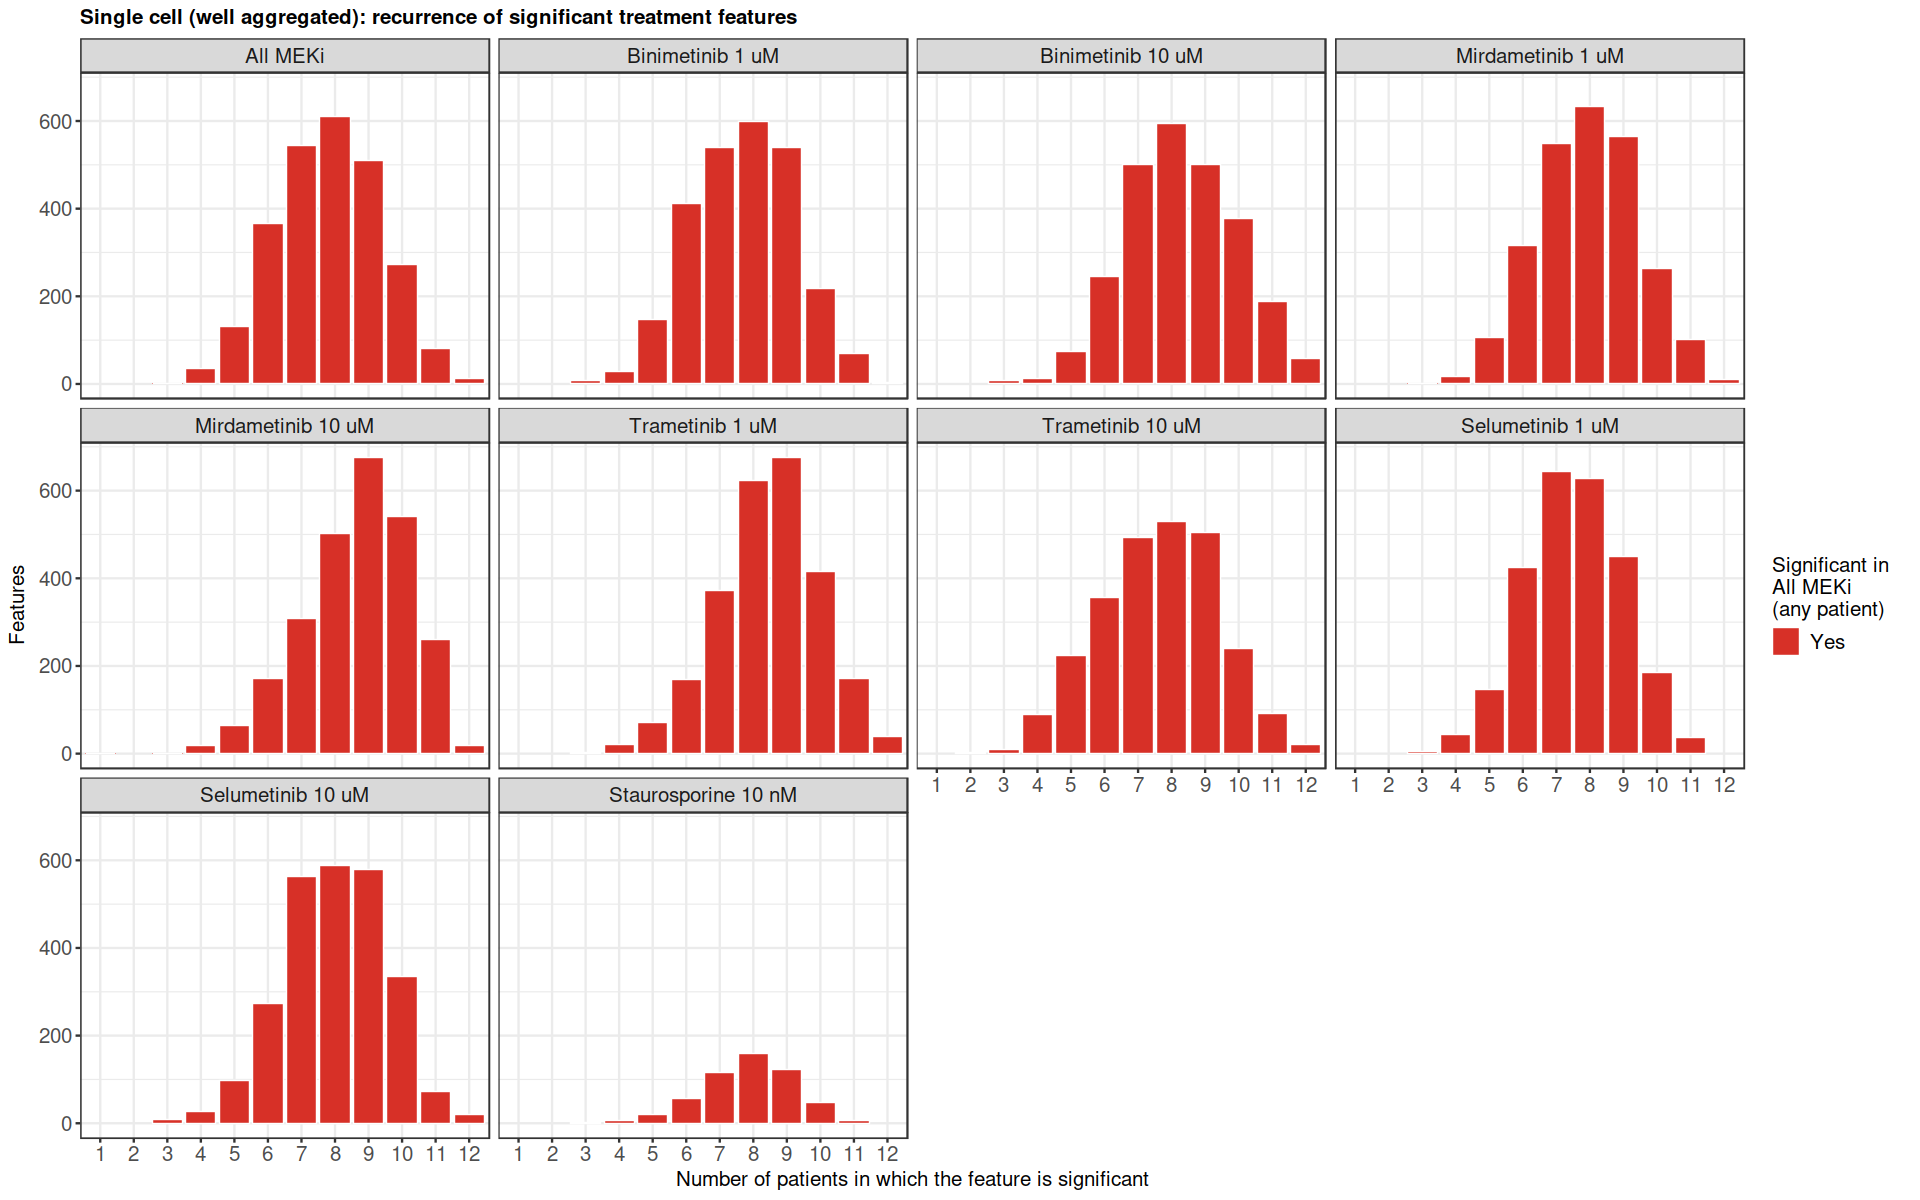

In [12]:
pooled_features <- treatment_df %>%
    filter(mek_group == POOLED_MEK_GROUP) %>%
    group_by(profile, feature) %>%
    summarise(pooled_significant = any(significant), .groups = "drop")
recurrence_df <- treatment_df %>%
    group_by(profile, mek_group, feature) %>%
    summarise(n_patients_significant = sum(significant), .groups = "drop") %>%
    left_join(pooled_features, by = c("profile", "feature")) %>%
    mutate(pooled_significant = coalesce(pooled_significant, FALSE))

recurrence_plot <- function(profile_name) {
    title <- paste0(profile_name, ": recurrence of significant treatment features")
    plot_df <- recurrence_df %>% filter(profile == profile_name, n_patients_significant > 0)
    if (nrow(plot_df) == 0) {
        return(
            ggplot()
            + annotate("text", x = 0, y = 0, label = "No features significant in any patient", size = 6)
            + labs(title = title)
            + theme_manuscript_void(base_size = 12)
        )
    }
    (
        ggplot(plot_df, aes(x = factor(n_patients_significant), fill = pooled_significant))
        + geom_bar(color = "white", linewidth = 0.3)
        + scale_fill_manual(
            values = c("FALSE" = "grey60", "TRUE" = "#d73027"),
            labels = c("FALSE" = "No", "TRUE" = "Yes")
        )
        + facet_wrap(~mek_group, nrow = 3, drop = FALSE)
        + labs(
            title = title,
            x = "Number of patients in which the feature is significant",
            y = "Features",
            fill = paste0("Significant in\n", POOLED_MEK_GROUP, "\n(any patient)")
        )
        + theme_manuscript(base_size = 12)
    )
}

recurrence_plots <- lapply(levels(lm_df$profile), recurrence_plot)
options(repr.plot.width = 16, repr.plot.height = 10)
save_plots_pdf(recurrence_plots, recurrence_path, width = 16, height = 10)
for (recurrence_plot_page in recurrence_plots) print(recurrence_plot_page)

In [13]:
# top features by the number of patients in which they are significant for
# treatment, per profile and MEKi group
recurrence_df %>%
    group_by(profile, mek_group) %>%
    slice_max(n_patients_significant, n = 5, with_ties = FALSE) %>%
    ungroup()

profile,mek_group,feature,n_patients_significant,pooled_significant
<fct>,<fct>,<chr>,<int>,<lgl>
Organoid,All MEKi,Organoid_ER_Intensity_MeanAbsoluteDeviationIntensity,5,TRUE
Organoid,All MEKi,Organoid_ER_Intensity_StdIntensity,5,TRUE
Organoid,All MEKi,Organoid_AGP_Intensity_MeanIntensityEdge,4,TRUE
Organoid,All MEKi,Organoid_DNA-ER_Colocalization_Correlation,4,TRUE
Organoid,All MEKi,Organoid_DNA-ER_Colocalization_RankWeightedColocalizationCoeff1,4,TRUE
Organoid,Binimetinib 1 uM,Organoid_AGP_Intensity_MeanIntensity,4,TRUE
Organoid,Binimetinib 1 uM,Organoid_DNA_Intensity_MeanIntensityEdge,4,TRUE
Organoid,Binimetinib 1 uM,Organoid_ER_Intensity_MeanAbsoluteDeviationIntensity,4,TRUE
Organoid,Binimetinib 1 uM,Organoid_Mito_Texture_InformationMeasureOfCorrelation1-3-05-256,4,TRUE
